In [1]:
import torch
import os

print("===== RETURNLENS GPU CHECK =====")

print("CUDA Available:", torch.cuda.is_available())
print("GPU Count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")
    print(
        "VRAM:",
        round(torch.cuda.get_device_properties(i).total_memory / 1024**3, 2),
        "GB"
    )

print("\n===== PROJECT CHECK =====")

ROOT = "/kaggle/working/returnlens"

for folder in ["data/raw", "data/processed",
               "data/images/b2_cache", "data/b2"]:
    path = os.path.join(ROOT, folder)
    print(folder, ":", "EXISTS" if os.path.exists(path) else "MISSING")

===== RETURNLENS GPU CHECK =====
CUDA Available: True
GPU Count: 2

GPU 0: Tesla T4
VRAM: 14.56 GB

GPU 1: Tesla T4
VRAM: 14.56 GB

===== PROJECT CHECK =====
data/raw : MISSING
data/processed : MISSING
data/images/b2_cache : MISSING
data/b2 : MISSING


In [2]:
!pip install -q --upgrade transformers accelerate peft bitsandbytes qwen-vl-utils pillow requests

In [3]:
import sys, platform, torch, importlib.metadata as md

print("Python:", sys.version.split()[0], "|", platform.platform())
print("PyTorch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("No GPU. Runtime → Change runtime type → T4 GPU, then restart.")

props = torch.cuda.get_device_properties(0)
print(f"GPU: {props.name} | VRAM: {props.total_memory/1e9:.1f} GB | CUDA build: {torch.version.cuda}")
print("bf16 supported:", torch.cuda.is_bf16_supported(), "(expected False on T4)")

for pkg in ["transformers", "accelerate", "peft", "bitsandbytes", "qwen-vl-utils", "pillow"]:
    try:
        print(f"{pkg}: {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg}: NOT INSTALLED  <-- fix before continuing")

Python: 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cu130 | CUDA available: True
GPU: Tesla T4 | VRAM: 15.6 GB | CUDA build: 13.0
bf16 supported: True (expected False on T4)
transformers: 5.23.0
accelerate: 1.16.0
peft: 0.22.0
bitsandbytes: 0.50.2
qwen-vl-utils: 0.0.14
pillow: 13.0.0


In [4]:
from pathlib import Path
import os

# Kaggle project directory
ROOT = Path("/kaggle/working/returnlens")

# Create project folders
for sub in [
    "data/raw",
    "data/processed",
    "data/images",
    "data/gold",
    "outputs/adapters",
    "outputs/logs",
    "outputs/predictions"
]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Folders created successfully!")
for sub in ["data/raw", "data/processed", "data/images", "data/gold",
            "outputs/adapters", "outputs/logs", "outputs/predictions"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /kaggle/working/returnlens
Folders created successfully!
Project root: /kaggle/working/returnlens


In [5]:
# Qwen2-VL-2B-Instruct is publicly available, so a token is usually not required.
# Needed later only if you push the adapter to a private repo.
from google.colab import userdata
try:
    token = userdata.get("HF_TOKEN")   # stored via the Colab 🔑 Secrets panel
    from huggingface_hub import login
    login(token=token)
    print("Logged in to Hugging Face.")
except Exception as e:
    print("No HF_TOKEN secret found, continuing anonymously:", type(e).__name__)

No HF_TOKEN secret found, continuing anonymously: TimeoutException


In [6]:
from dataclasses import dataclass

@dataclass(frozen=True)
class Config:
    model_id: str = "Qwen/Qwen2-VL-2B-Instruct"
    seed: int = 42
    # Cap image tokens: ~256 visual tokens per image. Must match in training and inference.
    min_pixels: int = 128 * 28 * 28
    max_pixels: int = 256 * 28 * 28
    max_new_tokens: int = 200

CFG = Config()

import random, numpy as np, torch
random.seed(CFG.seed); np.random.seed(CFG.seed); torch.manual_seed(CFG.seed)
print(CFG)

Config(model_id='Qwen/Qwen2-VL-2B-Instruct', seed=42, min_pixels=100352, max_pixels=200704, max_new_tokens=200)


In [7]:
import torch, time
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,   # T4 has no bf16
)

t0 = time.time()
model = Qwen2VLForConditionalGeneration.from_pretrained(
    CFG.model_id,
    quantization_config=bnb_config,
    device_map={"": 0},
    attn_implementation="sdpa",             # FlashAttention-2 is unsupported on T4
    torch_dtype=torch.float16,
)
processor = AutoProcessor.from_pretrained(
    CFG.model_id, min_pixels=CFG.min_pixels, max_pixels=CFG.max_pixels
)
model.eval()

print(f"Loaded in {time.time()-t0:.0f}s")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/56.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Loaded in 32s
GPU memory allocated: 1.53 GB
GPU memory reserved:  1.58 GB


In [8]:
import json, requests
from io import BytesIO
from PIL import Image
from qwen_vl_utils import process_vision_info

# Using the direct full-resolution URL to avoid Wikimedia's custom thumbnail 400 Client Errors
SAMPLE_URL = "https://upload.wikimedia.org/wikipedia/commons/4/47/PNG_transparency_demonstration_1.png"
try:
    r = requests.get(SAMPLE_URL, timeout=15, headers={"User-Agent": "returnlens-colab/0.1"})
    r.raise_for_status()
    img = Image.open(BytesIO(r.content)).convert("RGB")

except Exception as e:
    raise RuntimeError(f"Sample image download failed ({e}). Upload an image and use Image.open('/content/yourfile.jpg').")

SYSTEM = "You are a return-claim verification assistant. Describe only what is visible. Reply with JSON only."
USER_TMPL = (
    "Product title: {title}\nCustomer claim: {claim}\n\n"
    "Return a JSON object with exactly these keys: "
    '"damage_visible" (yes/no/unclear), "product_match" (yes/no/unclear), '
    '"consistent" (yes/no/unclear), "evidence_quality" (good/poor/insufficient), '
    '"action" (approve/ask_more_evidence/human_review), "reason" (one short sentence). '
    "Use \"unclear\" when the image does not let you decide."
)

messages = [
    {"role": "system", "content": SYSTEM},
    {"role": "user", "content": [
        {"type": "image", "image": img},
        {"type": "text", "text": USER_TMPL.format(title="Dice set", claim="The item arrived with a cracked surface.")},
    ]},
]

text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
image_inputs, video_inputs = process_vision_info(messages)
inputs = processor(text=[text], images=image_inputs, videos=video_inputs,
                   padding=True, return_tensors="pt").to("cuda")

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
with torch.no_grad():
    out = model.generate(**inputs, max_new_tokens=CFG.max_new_tokens, do_sample=False)
gen = out[:, inputs.input_ids.shape[1]:]
raw = processor.batch_decode(gen, skip_special_tokens=True)[0]

print(f"Latency: {time.time()-t0:.1f}s | peak GPU: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
print("RAW OUTPUT:\n", raw)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Latency: 8.3s | peak GPU: 1.61 GB
RAW OUTPUT:
 {
  "damage_visible": "unclear",
  "product_match": "unclear",
  "consistent": "unclear",
  "evidence_quality": "insufficient",
  "action": "ask_more_evidence",
  "reason": "The image does not clearly show the condition of the item's surface."
}


In [9]:
SCHEMA = {
    "damage_visible": {"yes", "no", "unclear"},
    "product_match": {"yes", "no", "unclear"},
    "consistent": {"yes", "no", "unclear"},
    "evidence_quality": {"good", "poor", "insufficient"},
    "action": {"approve", "ask_more_evidence", "human_review"},
}

def parse_and_validate(raw: str):
    """Return (parsed_dict | None, list_of_errors). No repair is attempted beyond stripping code fences."""
    s = raw.strip()
    if s.startswith("```"):
        s = s.strip("`")
        s = s[4:].strip() if s.lower().startswith("json") else s
    try:
        obj = json.loads(s)
    except json.JSONDecodeError as e:
        return None, [f"invalid_json: {e}"]
    if not isinstance(obj, dict):
        return None, ["not_an_object"]
    errors = []
    for k, allowed in SCHEMA.items():
        if k not in obj:
            errors.append(f"missing:{k}")
        elif obj[k] not in allowed:
            errors.append(f"bad_value:{k}={obj[k]!r}")
    if "reason" not in obj or not isinstance(obj.get("reason"), str):
        errors.append("missing_or_bad:reason")
    return obj, errors

parsed, errs = parse_and_validate(raw)
print("Parsed:", json.dumps(parsed, indent=2) if parsed else None)
print("Schema errors:", errs if errs else "none")

Parsed: {
  "damage_visible": "unclear",
  "product_match": "unclear",
  "consistent": "unclear",
  "evidence_quality": "insufficient",
  "action": "ask_more_evidence",
  "reason": "The image does not clearly show the condition of the item's surface."
}
Schema errors: none


In [10]:
checks = {
    "GPU detected": torch.cuda.is_available(),
    "Model loaded in 4-bit": getattr(model, "is_loaded_in_4bit", False),
    "Processor loaded": processor is not None,
    "Inference ran": bool(raw),
    "Output is valid JSON": parsed is not None,
    "Output passes schema": parsed is not None and not errs,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)

PASS GPU detected
PASS Model loaded in 4-bit
PASS Processor loaded
PASS Inference ran
PASS Output is valid JSON
PASS Output passes schema


In [11]:
import collections, datetime, gzip, hashlib, json, logging, os, time
from pathlib import Path
from urllib.parse import urlparse
import requests

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("returnlens.b1")
# KAGGLE PROJECT SETUP

from pathlib import Path

# Keep variable name unchanged for compatibility
DRIVE_ROOT = Path("/kaggle/working/returnlens")

# Create project directories
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

RAW_DIR = DRIVE_ROOT / "data/raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

for folder in [
    "data/processed",
    "data/images",
    "data/gold",
    "outputs/adapters",
    "outputs/logs",
    "outputs/predictions"
]:
    (DRIVE_ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

print("ReturnLens AI setup successful!")
print("Project:", DRIVE_ROOT)
print("Raw data:", RAW_DIR)
RAW_DIR = DRIVE_ROOT / "data/raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["Electronics", "Home_and_Kitchen", "Cell_Phones_and_Accessories"]

# (name, url template, is_gzip)
SOURCES = [
    ("ucsd_datarepo",
     "https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/review_categories/{cat}.jsonl.gz", True),
    ("huggingface",
     "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/review_categories/{cat}.jsonl", False),
]
HEADERS = {"User-Agent": "returnlens-colab/0.1"}
ALLOWED_IMAGE_HOSTS = ("media-amazon.com", "ssl-images-amazon.com")   # B1-a prints the real hosts so you can verify
ALLOWED_IMAGE_EXT = (".jpg", ".jpeg", ".png", ".webp")


def iter_lines(url: str, gzipped: bool, start: int = 0, stop: int | None = None):
    """Stream a remote JSONL(.gz) file; yield (line_number, raw_bytes) for start <= line_number < stop.
    The file is never fully downloaded: the connection is closed once `stop` is reached."""
    r = requests.get(url, stream=True, timeout=(15, 60), headers=HEADERS)
    try:
        r.raise_for_status()
        lines = gzip.GzipFile(fileobj=r.raw) if gzipped else r.iter_lines()
        for line_no, raw in enumerate(lines):
            if stop is not None and line_no >= stop:
                return
            if line_no < start:
                continue
            yield line_no, raw
    finally:
        r.close()


def find_working_source(cat: str):
    """Return (source_name, url, gzipped) for the first source that actually streams a line."""
    errors = []
    for name, tmpl, gz in SOURCES:
        url = tmpl.format(cat=cat)
        try:
            next(iter_lines(url, gz, 0, 1))
            return name, url, gz
        except Exception as e:
            errors.append(f"{name}: {type(e).__name__}: {e}")
            log.warning("source failed -> %s", errors[-1])
    raise RuntimeError(f"No source worked for {cat}:\n" + "\n".join(errors))


def is_valid_image_url(u) -> bool:
    if not isinstance(u, str):
        return False
    p = urlparse(u.strip())
    return (p.scheme == "https"
            and any(p.netloc == h or p.netloc.endswith("." + h) for h in ALLOWED_IMAGE_HOSTS)
            and p.path.lower().endswith(ALLOWED_IMAGE_EXT))


def pick_image_url(images) -> str | None:
    """First valid image URL from a review's `images` list (medium ~800px preferred; we resize to 512 later)."""
    for im in images:
        if not isinstance(im, dict):
            continue
        if im.get("attachment_type") not in (None, "IMAGE"):
            continue
        for key in ("medium_image_url", "large_image_url", "small_image_url"):
            if is_valid_image_url(im.get(key)):
                return im[key].strip()
    return None

print("Setup OK. Raw data folder:", RAW_DIR)

ReturnLens AI setup successful!
Project: /kaggle/working/returnlens
Raw data: /kaggle/working/returnlens/data/raw
Setup OK. Raw data folder: /kaggle/working/returnlens/data/raw


In [12]:
SCAN_LINES = 5000

def short(obj, n=1300):
    s = json.dumps(obj, indent=1, ensure_ascii=False)
    return s if len(s) <= n else s[:n] + "\n ...[truncated]"

def check_url(u):
    try:
        r = requests.get(u, stream=True, timeout=15, headers=HEADERS)
        out = (r.status_code, r.headers.get("Content-Type"))
        r.close()
        return out
    except Exception as e:
        return (None, type(e).__name__)

for idx, cat in enumerate(CATEGORIES):
    print("=" * 90, f"\n{cat}")
    src, url, gz = find_working_source(cat)
    print("source used:", src)
    keys, ratings_all, ratings_img = collections.Counter(), collections.Counter(), collections.Counter()
    hosts, att_types = collections.Counter(), collections.Counter()
    n_ok = n_bad = n_img = n_verified = 0
    years, sample_urls, first_img_rec = [], [], None

    for line_no, raw in iter_lines(url, gz, 0, SCAN_LINES):
        if idx == 0 and line_no < 3:
            print(f"\n--- raw record {line_no} ---")
            try:
                print(short(json.loads(raw)))
            except Exception:
                print("UNPARSEABLE:", raw[:300])
        try:
            rec = json.loads(raw)
            assert isinstance(rec, dict)
        except Exception:
            n_bad += 1
            continue
        n_ok += 1
        keys.update(rec.keys())
        ratings_all[rec.get("rating")] += 1
        if rec.get("verified_purchase") is True:
            n_verified += 1
        ts = rec.get("timestamp")
        if isinstance(ts, (int, float)):
            years.append(datetime.datetime.fromtimestamp(ts / 1000, tz=datetime.timezone.utc).year)
        imgs = rec.get("images")
        if isinstance(imgs, list) and imgs:
            n_img += 1
            ratings_img[rec.get("rating")] += 1
            first_img_rec = first_img_rec or rec
            for im in imgs:
                if isinstance(im, dict):
                    att_types[im.get("attachment_type")] += 1
                    for k in ("small_image_url", "medium_image_url", "large_image_url"):
                        if isinstance(im.get(k), str):
                            hosts[urlparse(im[k]).netloc] += 1
            u = pick_image_url(imgs)
            if u and len(sample_urls) < 3:
                sample_urls.append(u)

    print(f"\nparsed={n_ok:,}  corrupted={n_bad:,}  with_images={n_img:,} ({100*n_img/max(n_ok,1):.1f}%)  "
          f"verified_purchase=True: {n_verified:,} ({100*n_verified/max(n_ok,1):.1f}%)")
    print("fields seen (count):", dict(keys))
    print("attachment_type values:", dict(att_types))
    print("image hosts:", dict(hosts))
    if years:
        print(f"review years in first {SCAN_LINES:,} lines: {min(years)} to {max(years)}")
    print("rating dist (all):", dict(sorted(ratings_all.items(), key=lambda x: str(x[0]))))
    print("rating dist (with image):", dict(sorted(ratings_img.items(), key=lambda x: str(x[0]))))
    if first_img_rec:
        print("\nexample `images` field:\n", short(first_img_rec["images"], 700))
    for u in sample_urls:
        print("URL check:", check_url(u), u)

Electronics


2026-11-20 02:42:12,476 WARNING source failed -> ucsd_datarepo: HTTPError: 404 Client Error: Not Found for url: https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz


source used: huggingface

--- raw record 0 ---
{
 "rating": 3.0,
 "title": "Smells like gasoline! Going back!",
 "text": "First & most offensive: they reek of gasoline so if you are sensitive/allergic to petroleum products like I am you will want to pass on these.  Second: the phone adapter is useless as-is. Mine was not drilled far enough to be able to tighten it into place for my iPhone 12 max. It just slipped & slid all over. Stupid me putting the adapter together first without picking up the binoculars to smell them bc I wasted 15 minutes trying to figure out how to put the adapter together bc it does not come with instructions!  I had to come back here to the website which was a total pain. Third: the tripod is also useless. I would not trust the iOS to hold my $1600 phone nor even a Mattel Barbie for that matter. It’s just inefficient for the job imo.  Third: in order to try to give an honest review I did don gloves & eyewear to check the binoculars out.  They seemed average exce

2026-11-20 02:42:14,746 WARNING source failed -> ucsd_datarepo: HTTPError: 404 Client Error: Not Found for url: https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/review_categories/Home_and_Kitchen.jsonl.gz


source used: huggingface

parsed=5,000  corrupted=0  with_images=330 (6.6%)  verified_purchase=True: 4,280 (85.6%)
fields seen (count): {'rating': 5000, 'title': 5000, 'text': 5000, 'images': 5000, 'asin': 5000, 'parent_asin': 5000, 'user_id': 5000, 'timestamp': 5000, 'helpful_vote': 5000, 'verified_purchase': 5000}
attachment_type values: {'IMAGE': 576}
image hosts: {'m.media-amazon.com': 492, 'images-na.ssl-images-amazon.com': 1236}
review years in first 5,000 lines: 2003 to 2023
rating dist (all): {1.0: 257, 2.0: 140, 3.0: 355, 4.0: 709, 5.0: 3539}
rating dist (with image): {1.0: 31, 2.0: 15, 3.0: 20, 4.0: 30, 5.0: 234}

example `images` field:
 [
 {
  "small_image_url": "https://m.media-amazon.com/images/I/616kZbRGDpL._SL256_.jpg",
  "medium_image_url": "https://m.media-amazon.com/images/I/616kZbRGDpL._SL800_.jpg",
  "large_image_url": "https://m.media-amazon.com/images/I/616kZbRGDpL._SL1600_.jpg",
  "attachment_type": "IMAGE"
 },
 {
  "small_image_url": "https://m.media-amazon.com

2026-11-20 02:42:16,836 WARNING source failed -> ucsd_datarepo: HTTPError: 404 Client Error: Not Found for url: https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/review_categories/Cell_Phones_and_Accessories.jsonl.gz


source used: huggingface

parsed=5,000  corrupted=0  with_images=250 (5.0%)  verified_purchase=True: 4,288 (85.8%)
fields seen (count): {'rating': 5000, 'title': 5000, 'text': 5000, 'images': 5000, 'asin': 5000, 'parent_asin': 5000, 'user_id': 5000, 'timestamp': 5000, 'helpful_vote': 5000, 'verified_purchase': 5000}
attachment_type values: {'IMAGE': 456}
image hosts: {'images-na.ssl-images-amazon.com': 879, 'm.media-amazon.com': 489}
review years in first 5,000 lines: 2003 to 2023
rating dist (all): {1.0: 458, 2.0: 232, 3.0: 383, 4.0: 669, 5.0: 3258}
rating dist (with image): {1.0: 21, 2.0: 14, 3.0: 22, 4.0: 50, 5.0: 143}

example `images` field:
 [
 {
  "small_image_url": "https://images-na.ssl-images-amazon.com/images/I/B1PrCo7ZjXS._SL256_.jpg",
  "medium_image_url": "https://images-na.ssl-images-amazon.com/images/I/B1PrCo7ZjXS._SL800_.jpg",
  "large_image_url": "https://images-na.ssl-images-amazon.com/images/I/B1PrCo7ZjXS._SL1600_.jpg",
  "attachment_type": "IMAGE"
 }
]
URL check: (

In [13]:
LINES_PER_CATEGORY = 70_000
FLUSH_EVERY = 5_000
MAX_RETRIES = 5
MIN_TEXT_CHARS, MAX_TEXT_CHARS = 20, 2_000


def _atomic_write_json(path: Path, obj: dict) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1), encoding="utf-8")
    os.replace(tmp, path)


def parse_review(raw: bytes, line_no: int, category: str):
    """Return (status, reason, record). status is 'kept' | 'failed' | 'skipped'."""
    try:
        rec = json.loads(raw)
    except (json.JSONDecodeError, UnicodeDecodeError):
        return "failed", "corrupted_json", None
    if not isinstance(rec, dict):
        return "failed", "not_an_object", None
    try:
        rating = float(rec.get("rating"))
    except (TypeError, ValueError):
        return "failed", "bad_rating", None
    if not 1.0 <= rating <= 5.0:
        return "failed", "bad_rating", None
    parent_asin = rec.get("parent_asin")
    if not isinstance(parent_asin, str) or not parent_asin.strip():
        return "failed", "missing_parent_asin", None
    imgs = rec.get("images")
    if not isinstance(imgs, list) or not imgs:
        return "skipped", "no_images", None
    image_url = pick_image_url(imgs)
    if image_url is None:
        return "failed", "invalid_image_url", None
    text = rec.get("text")
    if not isinstance(text, str):
        return "failed", "bad_text", None
    text = text.strip()
    if len(text) < MIN_TEXT_CHARS:
        return "skipped", "short_text", None
    dedup_key = hashlib.sha1(f"{parent_asin}|{text[:500]}".encode("utf-8")).hexdigest()
    verified = rec.get("verified_purchase")
    return "kept", None, {
        "category": category, "parent_asin": parent_asin.strip(), "asin": rec.get("asin"),
        "rating": rating, "review_title": str(rec.get("title") or "").strip(),
        "text": text[:MAX_TEXT_CHARS],
        "verified_purchase": verified if isinstance(verified, bool) else None,
        "helpful_vote": rec.get("helpful_vote"), "timestamp": rec.get("timestamp"),
        "n_images": len(imgs), "image_url": image_url,
        "source_line": line_no, "dedup_key": dedup_key,
    }


def fresh_state() -> dict:
    return {"processed": 0, "kept_with_image": 0, "failed": 0, "duplicates": 0,
            "fail_reasons": {}, "skipped": {}}


def process_category(cat: str) -> dict:
    part = RAW_DIR / f"reviews_{cat}.jsonl"
    state_path = RAW_DIR / f"reviews_{cat}.progress.json"
    done_path = RAW_DIR / f"reviews_{cat}.DONE"

    if done_path.exists():
        log.info("%s: already complete, skipping.", cat)
        return json.loads(done_path.read_text(encoding="utf-8"))

    st = json.loads(state_path.read_text(encoding="utf-8")) if state_path.exists() else fresh_state()
    if st["processed"] == 0 or not part.exists():
        st = fresh_state()
        if part.exists():
            part.unlink()                      # stale partial file with no valid checkpoint

    # Reconcile the data file with the checkpoint (drop records written after the last saved state).
    seen: set[str] = set()
    if part.exists():
        tmp = part.with_suffix(".jsonl.tmp")
        n_kept = 0
        with part.open(encoding="utf-8") as fin, tmp.open("w", encoding="utf-8") as fout:
            for line in fin:
                try:
                    r = json.loads(line)
                except json.JSONDecodeError:
                    continue
                if r["source_line"] < st["processed"]:
                    fout.write(line if line.endswith("\n") else line + "\n")
                    seen.add(r["dedup_key"])
                    n_kept += 1
        os.replace(tmp, part)
        st["kept_with_image"] = n_kept
        log.info("%s: resuming at line %s with %s kept records.", cat, f"{st['processed']:,}", f"{n_kept:,}")

    src, url, gz = find_working_source(cat)
    log.info("%s: streaming from %s", cat, src)
    t0, attempt, finished = time.time(), 0, st["processed"] >= LINES_PER_CATEGORY

    while not finished:
        try:
            with part.open("a", encoding="utf-8") as out:
                for line_no, raw in iter_lines(url, gz, start=st["processed"], stop=LINES_PER_CATEGORY):
                    status, reason, rec = parse_review(raw, line_no, cat)
                    if status == "kept":
                        if rec["dedup_key"] in seen:
                            st["duplicates"] += 1
                        else:
                            seen.add(rec["dedup_key"])
                            out.write(json.dumps(rec, ensure_ascii=False) + "\n")
                            st["kept_with_image"] += 1
                    elif status == "failed":
                        st["failed"] += 1
                        st["fail_reasons"][reason] = st["fail_reasons"].get(reason, 0) + 1
                    else:
                        st["skipped"][reason] = st["skipped"].get(reason, 0) + 1
                    st["processed"] = line_no + 1
                    if st["processed"] % FLUSH_EVERY == 0:
                        out.flush(); os.fsync(out.fileno())
                        _atomic_write_json(state_path, st)
                        log.info("%s: processed=%s kept=%s failed=%s", cat, f"{st['processed']:,}",
                                 f"{st['kept_with_image']:,}", f"{st['failed']:,}")
            finished = True                    # stream reached the target or the end of the file
        except Exception as e:                 # network drop, truncated gzip, etc.
            attempt += 1
            log.warning("%s: stream error (%s: %s). Retry %d/%d from line %s",
                        cat, type(e).__name__, e, attempt, MAX_RETRIES, f"{st['processed']:,}")
            if attempt > MAX_RETRIES:
                _atomic_write_json(state_path, st)
                raise
            time.sleep(min(60, 2 ** attempt))

    if st["processed"] < LINES_PER_CATEGORY:
        log.warning("%s: file ended early at %s lines (target %s).", cat, f"{st['processed']:,}", f"{LINES_PER_CATEGORY:,}")
    st.update(source=src, elapsed_sec_last_run=round(time.time() - t0, 1))
    _atomic_write_json(state_path, st)
    _atomic_write_json(done_path, st)
    return st


results = {cat: process_category(cat) for cat in CATEGORIES}

print("\n" + "=" * 100)
tot = collections.Counter()
for cat, st in results.items():
    print(f"{cat:30s} processed={st['processed']:>7,}  kept_with_image={st['kept_with_image']:>6,}  "
          f"failed={st['failed']:>5,}  duplicates={st['duplicates']:>4,}")
    print(f"{'':30s} skipped={st['skipped']}  fail_reasons={st['fail_reasons']}")
    tot.update({k: st[k] for k in ("processed", "kept_with_image", "failed", "duplicates")})
print(f"{'TOTAL':30s} processed={tot['processed']:>7,}  kept_with_image={tot['kept_with_image']:>6,}  "
      f"failed={tot['failed']:>5,}  duplicates={tot['duplicates']:>4,}")

2026-11-20 02:42:19,901 WARNING source failed -> ucsd_datarepo: HTTPError: 404 Client Error: Not Found for url: https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/review_categories/Electronics.jsonl.gz
2026-11-20 02:42:20,333 INFO Electronics: streaming from huggingface
2026-11-20 02:42:20,872 INFO Electronics: processed=5,000 kept=194 failed=0
2026-11-20 02:42:20,999 INFO Electronics: processed=10,000 kept=501 failed=0
2026-11-20 02:42:21,126 INFO Electronics: processed=15,000 kept=711 failed=0
2026-11-20 02:42:21,315 INFO Electronics: processed=20,000 kept=1,619 failed=0
2026-11-20 02:42:21,474 INFO Electronics: processed=25,000 kept=2,089 failed=0
2026-11-20 02:42:21,623 INFO Electronics: processed=30,000 kept=2,479 failed=0
2026-11-20 02:42:21,789 INFO Electronics: processed=35,000 kept=3,420 failed=0
2026-11-20 02:42:21,903 INFO Electronics: processed=40,000 kept=3,676 failed=0
2026-11-20 02:42:22,016 INFO Electronics: processed=45,000 kept=3,987 failed=0
2026-11-20 


Electronics                    processed= 70,000  kept_with_image= 5,433  failed=    0  duplicates=   0
                               skipped={'no_images': 64531, 'short_text': 36}  fail_reasons={}
Home_and_Kitchen               processed= 70,000  kept_with_image= 7,662  failed=    0  duplicates=   7
                               skipped={'no_images': 62270, 'short_text': 61}  fail_reasons={}
Cell_Phones_and_Accessories    processed= 70,000  kept_with_image= 4,061  failed=    0  duplicates=   0
                               skipped={'no_images': 65876, 'short_text': 63}  fail_reasons={}
TOTAL                          processed=210,000  kept_with_image=17,156  failed=    0  duplicates=   7


In [14]:
import collections, datetime, hashlib, json, logging, os, random, re, time
from pathlib import Path
from urllib.parse import urlparse
import pandas as pd
import requests

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("returnlens.b1c")
# Kaggle project setup

import os
from pathlib import Path

# Kaggle project setup
DRIVE_ROOT = Path("/kaggle/working/returnlens")

# Create all project directories
DIRS = [
    "data/raw",
    "data/processed",
    "data/images",
    "data/gold",
    "outputs/adapters",
    "outputs/logs",
    "outputs/predictions"
]

for folder in DIRS:
    (DRIVE_ROOT / folder).mkdir(parents=True, exist_ok=True)

# Define directory variables
RAW_DIR = DRIVE_ROOT / "data/raw"
PROC_DIR = DRIVE_ROOT / "data/processed"
IMAGE_DIR = DRIVE_ROOT / "data/images"
GOLD_DIR = DRIVE_ROOT / "data/gold"

ADAPTER_DIR = DRIVE_ROOT / "outputs/adapters"
LOG_DIR = DRIVE_ROOT / "outputs/logs"
PRED_DIR = DRIVE_ROOT / "outputs/predictions"

print("ReturnLens AI setup successful!")
print("Project:", DRIVE_ROOT)
print("Raw:", RAW_DIR)
print("Processed:", PROC_DIR)
print("Images:", IMAGE_DIR)
print("Gold:", GOLD_DIR)

CATEGORIES = ["Electronics", "Home_and_Kitchen", "Cell_Phones_and_Accessories"]
SEED = 42
ALLOWED_IMAGE_HOSTS = ("media-amazon.com", "ssl-images-amazon.com")
ALLOWED_IMAGE_EXT = (".jpg", ".jpeg", ".png", ".webp")


def is_valid_image_url(u) -> bool:
    """Format check only (https, Amazon host, image extension). Reachability is tested in B2."""
    if not isinstance(u, str):
        return False
    p = urlparse(u.strip())
    return (p.scheme == "https"
            and any(p.netloc == h or p.netloc.endswith("." + h) for h in ALLOWED_IMAGE_HOSTS)
            and p.path.lower().endswith(ALLOWED_IMAGE_EXT))


def image_id_from_url(u: str) -> str:
    """'.../I/81FN4c0VHzL._SL800_.jpg' -> '81FN4c0VHzL' (same photo, different size suffix -> same id)."""
    return Path(urlparse(u).path).name.split(".")[0]


def normalize_text(t: str) -> str:
    return re.sub(r"\s+", " ", t.lower()).strip()


def read_jsonl(path: Path):
    """Yield parsed records; corrupt lines are logged and skipped."""
    with path.open(encoding="utf-8") as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                log.warning("corrupt line %d in %s", i, path.name)


def write_jsonl(path: Path, records) -> int:
    tmp = path.with_suffix(path.suffix + ".tmp")
    n = 0
    with tmp.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
            n += 1
    os.replace(tmp, path)
    return n


def write_json(path: Path, obj) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
    os.replace(tmp, path)


print("Setup OK.\nRAW :", RAW_DIR, "\nPROC:", PROC_DIR)

2026-11-20 02:42:28,512 INFO NumExpr defaulting to 4 threads.


ReturnLens AI setup successful!
Project: /kaggle/working/returnlens
Raw: /kaggle/working/returnlens/data/raw
Processed: /kaggle/working/returnlens/data/processed
Images: /kaggle/working/returnlens/data/images
Gold: /kaggle/working/returnlens/data/gold
Setup OK.
RAW : /kaggle/working/returnlens/data/raw 
PROC: /kaggle/working/returnlens/data/processed


In [15]:
REQUIRED = ["category", "parent_asin", "asin", "rating", "text", "image_url", "source_line", "dedup_key"]

for cat in CATEGORIES:
    path, done = RAW_DIR / f"reviews_{cat}.jsonl", RAW_DIR / f"reviews_{cat}.DONE"
    print("=" * 90, f"\n{cat}")
    if not path.exists():
        print("MISSING FILE:", path); continue
    n_lines = sum(1 for l in path.open(encoding="utf-8") if l.strip())
    recs = list(read_jsonl(path))
    df = pd.DataFrame(recs)
    state = json.loads(done.read_text()) if done.exists() else None
    print(f"lines={n_lines:,}  parsed={len(recs):,}  corrupt={n_lines - len(recs):,}  "
          f".DONE={'yes' if state else 'NO'}  checkpoint_kept={state['kept_with_image']:,}" if state else
          f"lines={n_lines:,} parsed={len(recs):,} .DONE=NO")
    if state and state["kept_with_image"] != len(recs):
        print("!! MISMATCH between checkpoint and file")
    print("missing values per required field:",
          {c: (int(df[c].isna().sum()) if c in df else "COLUMN MISSING") for c in REQUIRED})
    print("rating dist:", df["rating"].value_counts().sort_index().to_dict())
    print("verified_purchase:", df["verified_purchase"].astype(str).value_counts().to_dict())
    print("text length chars:", df["text"].str.len().describe(percentiles=[.1, .5, .9]).round(0).to_dict())
    valid = df["image_url"].map(is_valid_image_url)
    print(f"image_url format-valid: {int(valid.sum()):,} / {len(df):,}   invalid: {int((~valid).sum()):,}")
    print("image hosts:", df["image_url"].map(lambda u: urlparse(u).netloc).value_counts().to_dict())
    print("image ext  :", df["image_url"].map(lambda u: Path(urlparse(u).path).suffix.lower()).value_counts().to_dict())
    print(f"unique parent_asin={df['parent_asin'].nunique():,}  "
          f"unique image_url={df['image_url'].nunique():,}  unique image_id={df['image_url'].map(image_id_from_url).nunique():,}")
    yrs = pd.to_datetime(df["timestamp"], unit="ms", errors="coerce").dt.year
    print("review years:", int(yrs.min()), "to", int(yrs.max()))
    print("first record:", json.dumps({k: (v[:160] if isinstance(v, str) else v) for k, v in recs[0].items()},
                                      ensure_ascii=False))

Electronics
lines=5,433  parsed=5,433  corrupt=0  .DONE=yes  checkpoint_kept=5,433
missing values per required field: {'category': 0, 'parent_asin': 0, 'asin': 0, 'rating': 0, 'text': 0, 'image_url': 0, 'source_line': 0, 'dedup_key': 0}
rating dist: {1.0: 294, 2.0: 166, 3.0: 256, 4.0: 783, 5.0: 3934}
verified_purchase: {'True': 3110, 'False': 2323}
text length chars: {'count': 5433.0, 'mean': 641.0, 'std': 543.0, 'min': 20.0, '10%': 151.0, '50%': 432.0, '90%': 1574.0, 'max': 2000.0}
image_url format-valid: 5,433 / 5,433   invalid: 0
image hosts: {'images-na.ssl-images-amazon.com': 3052, 'm.media-amazon.com': 2381}
image ext  : {'.jpg': 5432, '.png': 1}
unique parent_asin=5,132  unique image_url=5,381  unique image_id=5,381
review years: 2005 to 2023
first record: {"category": "Electronics", "parent_asin": "B083NRGZMM", "asin": "B083NRGZMM", "rating": 3.0, "review_title": "Smells like gasoline! Going back!", "text": "First & most offensive: they reek of gasoline so if you are sensitive/

In [16]:
seen_pair, seen_text, seen_img = set(), set(), set()
kept_all, dropped_all, summary = [], [], {}

for cat in CATEGORIES:
    recs = sorted(read_jsonl(RAW_DIR / f"reviews_{cat}.jsonl"), key=lambda r: r["source_line"])
    drops, kept_cat = collections.Counter(), []
    for r in recs:
        reason = None
        text, asin, url = r.get("text"), r.get("parent_asin"), r.get("image_url")
        if not isinstance(text, str) or not text.strip() or not isinstance(asin, str) or not asin:
            reason = "missing_field"
        elif not is_valid_image_url(url):
            reason = "invalid_image_url"
        else:
            nt, iid = normalize_text(text), image_id_from_url(url)
            pair = (asin, nt)
            if pair in seen_pair:   reason = "dup_same_product_text"
            elif nt in seen_text:   reason = "dup_text_other_product"
            elif iid in seen_img:   reason = "dup_image_id"
        if reason:
            drops[reason] += 1
            dropped_all.append({**r, "exclude_reason": reason, "exclude_stage": "dedup"})
            continue
        seen_pair.add(pair); seen_text.add(nt); seen_img.add(iid)
        r["image_id"] = iid
        kept_cat.append(r)

    asins = collections.Counter(r["parent_asin"] for r in kept_cat)
    write_json(PROC_DIR / f"needed_asins_{cat}.json", sorted(asins))
    summary[cat] = {"input": len(recs), "kept": len(kept_cat), "dropped": dict(drops),
                    "unique_parent_asins": len(asins),
                    "max_reviews_per_product": max(asins.values()) if asins else 0}
    kept_all += kept_cat

overlap = {}
sets = {c: {r["parent_asin"] for r in kept_all if r["category"] == c} for c in CATEGORIES}
for i, a in enumerate(CATEGORIES):
    for b in CATEGORIES[i + 1:]:
        overlap[f"{a}&{b}"] = len(sets[a] & sets[b])
summary["_parent_asin_overlap_between_categories"] = overlap

n_kept = write_jsonl(PROC_DIR / "reviews_dedup.jsonl", kept_all)
n_drop = write_jsonl(PROC_DIR / "reviews_excluded_dedup.jsonl", dropped_all)
write_json(PROC_DIR / "dedup_summary.json", summary)

for cat in CATEGORIES:
    print(cat, summary[cat])
print("cross-category parent_asin overlap:", overlap)
print(f"\nSAVED reviews_dedup.jsonl = {n_kept:,} | reviews_excluded_dedup.jsonl = {n_drop:,}")

Electronics {'input': 5433, 'kept': 5377, 'dropped': {'dup_image_id': 49, 'dup_text_other_product': 7}, 'unique_parent_asins': 5080, 'max_reviews_per_product': 5}
Home_and_Kitchen {'input': 7662, 'kept': 7587, 'dropped': {'dup_image_id': 62, 'dup_text_other_product': 13}, 'unique_parent_asins': 7236, 'max_reviews_per_product': 15}
Cell_Phones_and_Accessories {'input': 4061, 'kept': 4041, 'dropped': {'dup_image_id': 18, 'dup_text_other_product': 2}, 'unique_parent_asins': 3776, 'max_reviews_per_product': 7}
cross-category parent_asin overlap: {'Electronics&Home_and_Kitchen': 0, 'Electronics&Cell_Phones_and_Accessories': 0, 'Home_and_Kitchen&Cell_Phones_and_Accessories': 0}

SAVED reviews_dedup.jsonl = 17,005 | reviews_excluded_dedup.jsonl = 151


In [17]:
META_URL = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/meta_categories/meta_{cat}.jsonl"
MAX_META_GB = 3.0                       # per category; raise and re-run to extend coverage
CATEGORIES_TO_RUN = CATEGORIES
CHECKPOINT_EVERY_BYTES = 100 * 1024**2
MAX_RETRIES = 5
HEADERS = {"User-Agent": "returnlens-colab/0.1", "Accept-Encoding": "identity"}
ASIN_RE = re.compile(rb'"parent_asin":\s*"([A-Za-z0-9]+)"')


class RangeNotSupported(RuntimeError):
    pass


def iter_meta_lines(url: str, start_offset: int):
    """Yield (end_byte_offset, line_bytes). Resumes from start_offset via an HTTP Range request."""
    headers = dict(HEADERS)
    if start_offset > 0:
        headers["Range"] = f"bytes={start_offset}-"
    with requests.get(url, stream=True, timeout=(15, 60), headers=headers) as r:
        if r.status_code == 416:                      # offset beyond end of file
            return
        r.raise_for_status()
        if start_offset > 0 and r.status_code != 206:
            raise RangeNotSupported("Server ignored the Range header; cannot resume safely.")
        offset, buf = start_offset, b""
        for chunk in r.iter_content(chunk_size=1 << 20):
            buf += chunk
            lines = buf.split(b"\n")
            buf = lines.pop()
            for ln in lines:
                offset += len(ln) + 1
                yield offset, ln
        if buf.strip():
            offset += len(buf)
            yield offset, buf


def _as_list(x):
    return x if isinstance(x, list) else []


def meta_image_url(images):
    """First valid catalogue image URL. Handles list-of-dicts (raw) and dict-of-lists layouts."""
    cands = []
    if isinstance(images, dict):
        for k in ("large", "hi_res"):
            cands += _as_list(images.get(k))
    elif isinstance(images, list):
        for im in images:
            if isinstance(im, dict):
                cands += [im.get("large"), im.get("hi_res")]
    return next((u for u in cands if is_valid_image_url(u)), None)


def extract_meta(rec: dict) -> dict:
    title = rec.get("title")
    price = rec.get("price")
    return {
        "parent_asin": rec["parent_asin"],
        "meta_title": title.strip() if isinstance(title, str) and title.strip() else None,
        "main_category": rec.get("main_category") if isinstance(rec.get("main_category"), str) else None,
        "store": rec.get("store") if isinstance(rec.get("store"), str) else None,
        "categories": [c for c in _as_list(rec.get("categories")) if isinstance(c, str)][:6],
        "price": price if isinstance(price, (int, float, str)) and not isinstance(price, bool) else None,
        "average_rating": rec.get("average_rating"),
        "rating_number": rec.get("rating_number"),
        "features": [f.strip()[:300] for f in _as_list(rec.get("features")) if isinstance(f, str) and f.strip()][:5],
        "description": " ".join(d for d in _as_list(rec.get("description")) if isinstance(d, str))[:600],
        "meta_image_url": meta_image_url(rec.get("images")),
    }


def scan_meta(cat: str) -> dict:
    needed = set(json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text()))
    needed_b = {a.encode() for a in needed}
    found_path = RAW_DIR / f"meta_found_{cat}.jsonl"
    state_path = RAW_DIR / f"meta_{cat}.progress.json"
    url, cap = META_URL.format(cat=cat), int(MAX_META_GB * 1024**3)
    st = (json.loads(state_path.read_text()) if state_path.exists()
          else {"offset": 0, "lines": 0, "found": 0, "bad_lines": 0, "status": "running"})
    if st["status"] in ("complete_all_found", "complete_eof"):
        log.info("%s: already complete (%s).", cat, st["status"]); return st

    # Reconcile found-file with the checkpoint: drop anything found after the saved offset.
    found: set[str] = set()
    if found_path.exists():
        tmp = found_path.with_suffix(".jsonl.tmp")
        with found_path.open(encoding="utf-8") as fin, tmp.open("w", encoding="utf-8") as fout:
            for line in fin:
                try:
                    r = json.loads(line)
                except json.JSONDecodeError:
                    continue
                if r["end_offset"] <= st["offset"]:
                    fout.write(line if line.endswith("\n") else line + "\n"); found.add(r["parent_asin"])
        os.replace(tmp, found_path)
    st["found"] = len(found)

    def save():
        st["scanned_gb"] = round(st["offset"] / 1024**3, 3)
        write_json(state_path, st)

    if len(found) >= len(needed):
        st["status"] = "complete_all_found"; save(); return st
    if st["offset"] >= cap:
        st["status"] = "paused_at_cap"; save()
        log.info("%s: already at cap (%.2f GB). Raise MAX_META_GB to continue.", cat, st["offset"] / 1024**3)
        return st

    log.info("%s: need %s products | resume at %.2f GB | cap %.1f GB", cat, f"{len(needed):,}",
             st["offset"] / 1024**3, MAX_META_GB)
    t0, start_off, last_ckpt, attempt = time.time(), st["offset"], st["offset"], 0
    while True:
        gen = None
        try:
            with found_path.open("a", encoding="utf-8") as out:
                gen = iter_meta_lines(url, st["offset"])
                for end_off, ln in gen:
                    st["offset"], st["lines"] = end_off, st["lines"] + 1
                    ids = ASIN_RE.findall(ln)
                    if ids and any(a in needed_b for a in ids):
                        try:
                            rec = json.loads(ln)
                        except (json.JSONDecodeError, UnicodeDecodeError):
                            st["bad_lines"] += 1
                        else:
                            pa = rec.get("parent_asin")
                            if pa in needed and pa not in found:
                                m = extract_meta(rec); m["end_offset"] = end_off
                                out.write(json.dumps(m, ensure_ascii=False) + "\n")
                                found.add(pa); st["found"] = len(found)
                    if st["offset"] - last_ckpt >= CHECKPOINT_EVERY_BYTES:
                        out.flush(); os.fsync(out.fileno()); save(); last_ckpt = st["offset"]
                        mbps = (st["offset"] - start_off) / max(time.time() - t0, 1e-6) / 1e6
                        log.info("%s: %.2f GB scanned | %s lines | found %s/%s | %.1f MB/s",
                                 cat, st["offset"] / 1024**3, f"{st['lines']:,}",
                                 f"{len(found):,}", f"{len(needed):,}", mbps)
                    if len(found) >= len(needed):
                        st["status"] = "complete_all_found"; break
                    if st["offset"] >= cap:
                        st["status"] = "paused_at_cap"; break
                else:
                    st["status"] = "complete_eof"
            break
        except Exception as e:
            fatal = isinstance(e, RangeNotSupported) or (
                isinstance(e, requests.HTTPError) and e.response is not None
                and e.response.status_code in (401, 403, 404))
            attempt += 1
            log.warning("%s: %s: %s (retry %d/%d)", cat, type(e).__name__, e, attempt, MAX_RETRIES)
            if fatal or attempt > MAX_RETRIES:
                save(); raise
            time.sleep(min(60, 2 ** attempt))
        finally:
            if gen is not None:
                gen.close()
    save()
    return st


meta_results = {cat: scan_meta(cat) for cat in CATEGORIES_TO_RUN}
print("\n" + "=" * 90)
for cat, st in meta_results.items():
    need = len(json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text()))
    print(f"{cat:30s} status={st['status']:<19s} scanned={st.get('scanned_gb', 0):.2f} GB  "
          f"lines={st['lines']:,}  products_found={st['found']:,}/{need:,} ({100*st['found']/max(need,1):.1f}%)  "
          f"unparseable_matches={st['bad_lines']}")

2026-11-20 02:42:30,917 INFO Electronics: need 5,080 products | resume at 0.00 GB | cap 3.0 GB
2026-11-20 02:42:32,529 INFO Electronics: 0.10 GB scanned | 28,655 lines | found 240/5,080 | 65.1 MB/s
2026-11-20 02:42:33,211 INFO Electronics: 0.20 GB scanned | 57,517 lines | found 441/5,080 | 91.5 MB/s
2026-11-20 02:42:33,876 INFO Electronics: 0.29 GB scanned | 86,621 lines | found 649/5,080 | 106.3 MB/s
2026-11-20 02:42:34,504 INFO Electronics: 0.39 GB scanned | 115,769 lines | found 842/5,080 | 117.0 MB/s
2026-11-20 02:42:35,074 INFO Electronics: 0.49 GB scanned | 145,171 lines | found 1,023/5,080 | 126.2 MB/s
2026-11-20 02:42:35,788 INFO Electronics: 0.59 GB scanned | 174,759 lines | found 1,172/5,080 | 129.2 MB/s
2026-11-20 02:42:36,356 INFO Electronics: 0.68 GB scanned | 204,260 lines | found 1,322/5,080 | 135.0 MB/s
2026-11-20 02:42:37,039 INFO Electronics: 0.78 GB scanned | 234,184 lines | found 1,466/5,080 | 137.0 MB/s
2026-11-20 02:42:37,619 INFO Electronics: 0.88 GB scanned | 26


Electronics                    status=paused_at_cap       scanned=3.00 GB  lines=937,302  products_found=3,921/5,080 (77.2%)  unparseable_matches=0
Home_and_Kitchen               status=paused_at_cap       scanned=3.00 GB  lines=931,988  products_found=3,409/7,236 (47.1%)  unparseable_matches=0
Cell_Phones_and_Accessories    status=paused_at_cap       scanned=3.00 GB  lines=1,007,614  products_found=3,612/3,776 (95.7%)  unparseable_matches=0


In [18]:
def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with p.open("rb") as f:
        for blk in iter(lambda: f.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()


def pct(a, b):
    return round(100 * a / b, 1) if b else None


dedup_summary = json.loads((PROC_DIR / "dedup_summary.json").read_text())
reviews = list(read_jsonl(PROC_DIR / "reviews_dedup.jsonl"))
clean, excluded, product_rows, report_rows = [], [], [], []
PRODUCT_FIELDS = ["main_category", "store", "categories", "price", "average_rating",
                  "rating_number", "features", "description", "meta_image_url"]

for cat in CATEGORIES:
    meta = {}
    for m in read_jsonl(RAW_DIR / f"meta_found_{cat}.jsonl"):
        meta.setdefault(m["parent_asin"], m)
    st_meta = json.loads((RAW_DIR / f"meta_{cat}.progress.json").read_text())
    st_raw = json.loads((RAW_DIR / f"reviews_{cat}.DONE").read_text())
    cat_reviews = [r for r in reviews if r["category"] == cat]
    cat_clean, ex = [], collections.Counter()
    for r in cat_reviews:
        m = meta.get(r["parent_asin"])
        if m is None:
            reason = "no_meta_in_file" if st_meta["status"] == "complete_eof" else "no_meta_in_scanned_region"
        elif not m.get("meta_title"):
            reason = "missing_title"
        else:
            cat_clean.append({**r, "product_title": m["meta_title"], **{k: m.get(k) for k in PRODUCT_FIELDS}})
            continue
        ex[reason] += 1
        excluded.append({**r, "exclude_reason": reason, "exclude_stage": "meta_join"})
    clean += cat_clean
    for pa in sorted({r["parent_asin"] for r in cat_clean}):
        m = meta[pa]
        product_rows.append({"category": cat, "parent_asin": pa, "product_title": m["meta_title"],
                             **{k: m.get(k) for k in PRODUCT_FIELDS}})

    df = pd.DataFrame(cat_clean) if cat_clean else pd.DataFrame(columns=["rating"])
    n_prod_needed = dedup_summary[cat]["unique_parent_asins"]
    row = {
        "category": cat,
        "reviews_with_image_B1b": st_raw["kept_with_image"],
        "after_dedup": dedup_summary[cat]["kept"],
        **{f"dedup_drop_{k}": v for k, v in dedup_summary[cat]["dropped"].items()},
        "products_needed": n_prod_needed,
        "products_with_meta": len(meta),
        "meta_coverage_pct": pct(len(meta), n_prod_needed),
        "meta_scan_status": st_meta["status"],
        "meta_scanned_gb": st_meta.get("scanned_gb"),
        "excluded_no_meta": ex.get("no_meta_in_scanned_region", 0) + ex.get("no_meta_in_file", 0),
        "excluded_missing_title": ex.get("missing_title", 0),
        "clean_records": len(cat_clean),
        "clean_unique_products": df["parent_asin"].nunique() if len(df) and "parent_asin" in df else 0,
    }
    if len(cat_clean):
        row.update({
            "rating_le2": int((df["rating"] <= 2).sum()),
            "rating_eq3": int(((df["rating"] > 2) & (df["rating"] < 4)).sum()),
            "rating_ge4": int((df["rating"] >= 4).sum()),
            "verified_true": int((df["verified_purchase"] == True).sum()),
            "verified_false": int((df["verified_purchase"] == False).sum()),
            "verified_unknown": int(df["verified_purchase"].isna().sum()),
            "text_len_p10": int(df["text"].str.len().quantile(.1)),
            "text_len_median": int(df["text"].str.len().median()),
            "text_len_p90": int(df["text"].str.len().quantile(.9)),
            "title_len_median": int(df["product_title"].str.len().median()),
            "short_titles_lt10": int((df["product_title"].str.len() < 10).sum()),
            "invalid_review_image_urls": int((~df["image_url"].map(is_valid_image_url)).sum()),
            "dup_image_ids": int(len(df) - df["image_id"].nunique()),
            "meta_image_url_present_pct": pct(int(df["meta_image_url"].notna().sum()), len(df)),
        })
    report_rows.append(row)

n_clean = write_jsonl(PROC_DIR / "reviews_clean.jsonl", clean)
n_excl = write_jsonl(PROC_DIR / "reviews_excluded_meta.jsonl", excluded)
n_prod = write_jsonl(PROC_DIR / "product_meta.jsonl", product_rows)

rep_df = pd.DataFrame(report_rows).fillna(0)
total = rep_df.drop(columns=["category", "meta_scan_status", "meta_coverage_pct", "meta_image_url_present_pct",
                             "text_len_p10", "text_len_median", "text_len_p90", "title_len_median"],
                    errors="ignore").sum(numeric_only=True).to_dict()
report = {"generated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
          "params": {"lines_per_category": 70000, "max_meta_gb": MAX_META_GB, "seed": SEED},
          "per_category": report_rows, "total": total}
write_json(PROC_DIR / "b1_quality_report.json", report)
rep_df.to_csv(PROC_DIR / "b1_quality_report.csv", index=False)

files = ["reviews_dedup.jsonl", "reviews_excluded_dedup.jsonl", "reviews_clean.jsonl",
         "reviews_excluded_meta.jsonl", "product_meta.jsonl", "b1_quality_report.json"]
write_json(PROC_DIR / "b1_manifest.json", {
    "created_utc": report["generated_utc"], "params": report["params"],
    "files": {f: {"bytes": (PROC_DIR / f).stat().st_size, "sha256": sha256_file(PROC_DIR / f)} for f in files}})

pd.set_option("display.max_rows", 100, "display.width", 200)
print(rep_df.set_index("category").T.to_string())
print("\nTOTAL:", total)
print(f"\nSAVED: reviews_clean={n_clean:,} | reviews_excluded_meta={n_excl:,} | product_meta={n_prod:,}")

category                             Electronics Home_and_Kitchen Cell_Phones_and_Accessories
reviews_with_image_B1b                      5433             7662                        4061
after_dedup                                 5377             7587                        4041
dedup_drop_dup_image_id                       49               62                          18
dedup_drop_dup_text_other_product              7               13                           2
products_needed                             5080             7236                        3776
products_with_meta                          3921             3409                        3612
meta_coverage_pct                           77.2             47.1                        95.7
meta_scan_status                   paused_at_cap    paused_at_cap               paused_at_cap
meta_scanned_gb                              3.0              3.0                         3.0
excluded_no_meta                            1206            

In [19]:
REQUIRED_CLEAN = ["category", "parent_asin", "asin", "rating", "text", "verified_purchase_key",
                  "image_url", "image_id", "product_title", "source_line"]
checks = []
def check(name, ok):
    checks.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

clean = list(read_jsonl(PROC_DIR / "reviews_clean.jsonl"))
products = list(read_jsonl(PROC_DIR / "product_meta.jsonl"))
report = json.loads((PROC_DIR / "b1_quality_report.json").read_text())
by_cat = collections.defaultdict(list)
for r in clean:
    by_cat[r["category"]].append(r)

for row in report["per_category"]:
    check(f"{row['category']}: reloaded count == report ({row['clean_records']:,})",
          len(by_cat[row["category"]]) == row["clean_records"])
check("all clean records have non-empty core fields",
      all(r.get(k) not in (None, "") for r in clean
          for k in ["category", "parent_asin", "asin", "rating", "text", "image_url", "image_id", "product_title"]))
check("'verified_purchase' key present in every record (value may be null)",
      all("verified_purchase" in r for r in clean))
check("ratings within 1-5", all(1.0 <= r["rating"] <= 5.0 for r in clean))
check("all review image URLs format-valid", all(is_valid_image_url(r["image_url"]) for r in clean))
check("no duplicate (parent_asin, normalized text)",
      len({(r["parent_asin"], normalize_text(r["text"])) for r in clean}) == len(clean))
check("no duplicate image_id", len({r["image_id"] for r in clean}) == len(clean))
check("no user_id stored in any record", not any("user_id" in r for r in clean))
check("product_meta rows == unique products in clean",
      len(products) == len({r["parent_asin"] for r in clean}))

rng = random.Random(SEED)
for cat in CATEGORIES:
    print("\n" + "-" * 90, f"\nSAMPLES: {cat}")
    for r in rng.sample(by_cat[cat], min(2, len(by_cat[cat]))):
        print(json.dumps({"parent_asin": r["parent_asin"], "asin": r["asin"], "rating": r["rating"],
                          "verified_purchase": r["verified_purchase"],
                          "product_title": r["product_title"][:120],
                          "text": r["text"][:200], "image_url": r["image_url"],
                          "meta_image_url": r.get("meta_image_url")}, ensure_ascii=False, indent=1))

print(f"\n{sum(checks)}/{len(checks)} checks passed")

PASS  Electronics: reloaded count == report (4,171)
PASS  Home_and_Kitchen: reloaded count == report (3,655)
PASS  Cell_Phones_and_Accessories: reloaded count == report (3,873)
PASS  all clean records have non-empty core fields
PASS  'verified_purchase' key present in every record (value may be null)
PASS  ratings within 1-5
PASS  all review image URLs format-valid
PASS  no duplicate (parent_asin, normalized text)
PASS  no duplicate image_id
PASS  no user_id stored in any record
PASS  product_meta rows == unique products in clean

------------------------------------------------------------------------------------------ 
SAMPLES: Electronics
{
 "parent_asin": "B094VLCD4F",
 "asin": "B08XTGPRQF",
 "rating": 5.0,
 "verified_purchase": false,
 "product_title": "Digital Optical Audio Toslink Cable 6FT, S/PDIF Port, 24K Gold Plated Connectors for Home Theater, Sound Bar, TV, PS4, X",
 "text": "We had installed a 10 ft optical cable that served its purpose, but with just a little re-arrangem

In [20]:
import collections, datetime, hashlib, json, logging, os, random, re, shutil, time
from pathlib import Path
from urllib.parse import urlparse
import pandas as pd
import requests

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("returnlens.b1d")

DRIVE_ROOT = Path("/kaggle/working/returnlens")
if not DRIVE_ROOT.exists():
    raise RuntimeError("Drive project folder not found. Re-run the drive.mount cell, then this cell.")
RAW_DIR, PROC_DIR = DRIVE_ROOT / "data/raw", DRIVE_ROOT / "data/processed"
BACKUP_DIR = RAW_DIR / "_ckpt_backup"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["Electronics", "Home_and_Kitchen", "Cell_Phones_and_Accessories"]
SEED, GIB = 42, 1024 ** 3
META_URL = "https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/raw/meta_categories/meta_{cat}.jsonl"
HEADERS = {"User-Agent": "returnlens-colab/0.1", "Accept-Encoding": "identity"}
ASIN_RE = re.compile(rb'"parent_asin":\s*"([A-Za-z0-9]+)"')
ALLOWED_IMAGE_HOSTS = ("media-amazon.com", "ssl-images-amazon.com")
ALLOWED_IMAGE_EXT = (".jpg", ".jpeg", ".png", ".webp")
PRODUCT_FIELDS = ["main_category", "store", "categories", "price", "average_rating",
                  "rating_number", "features", "description", "meta_image_url"]


def is_valid_image_url(u) -> bool:
    if not isinstance(u, str):
        return False
    p = urlparse(u.strip())
    return (p.scheme == "https"
            and any(p.netloc == h or p.netloc.endswith("." + h) for h in ALLOWED_IMAGE_HOSTS)
            and p.path.lower().endswith(ALLOWED_IMAGE_EXT))


def read_jsonl(path: Path):
    with path.open(encoding="utf-8") as f:
        for i, line in enumerate(f):
            if not line.strip():
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                log.warning("corrupt line %d in %s", i, path.name)


def write_jsonl(path: Path, records) -> int:
    tmp = path.with_suffix(path.suffix + ".tmp")
    n = 0
    with tmp.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n"); n += 1
    os.replace(tmp, path)
    return n


def write_json(path: Path, obj) -> None:
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
    os.replace(tmp, path)


def _as_list(x):
    return x if isinstance(x, list) else []


def meta_image_url(images):
    cands = []
    if isinstance(images, dict):
        for k in ("large", "hi_res"):
            cands += _as_list(images.get(k))
    elif isinstance(images, list):
        for im in images:
            if isinstance(im, dict):
                cands += [im.get("large"), im.get("hi_res")]
    return next((u for u in cands if is_valid_image_url(u)), None)


def extract_meta(rec: dict) -> dict:
    """IDENTICAL to the C3 extractor, so newly found records match the existing ones."""
    title, price = rec.get("title"), rec.get("price")
    return {
        "parent_asin": rec["parent_asin"],
        "meta_title": title.strip() if isinstance(title, str) and title.strip() else None,
        "main_category": rec.get("main_category") if isinstance(rec.get("main_category"), str) else None,
        "store": rec.get("store") if isinstance(rec.get("store"), str) else None,
        "categories": [c for c in _as_list(rec.get("categories")) if isinstance(c, str)][:6],
        "price": price if isinstance(price, (int, float, str)) and not isinstance(price, bool) else None,
        "average_rating": rec.get("average_rating"),
        "rating_number": rec.get("rating_number"),
        "features": [f.strip()[:300] for f in _as_list(rec.get("features")) if isinstance(f, str) and f.strip()][:5],
        "description": " ".join(d for d in _as_list(rec.get("description")) if isinstance(d, str))[:600],
        "meta_image_url": meta_image_url(rec.get("images")),
    }


class RangeNotSupported(RuntimeError):
    pass


def iter_meta_lines(url: str, start_offset: int):
    """Yield (end_byte_offset, line_bytes); resumes from start_offset with an HTTP Range request."""
    headers = dict(HEADERS)
    if start_offset > 0:
        headers["Range"] = f"bytes={start_offset}-"
    with requests.get(url, stream=True, timeout=(15, 60), headers=headers) as r:
        if r.status_code == 416:
            return
        r.raise_for_status()
        if start_offset > 0 and r.status_code != 206:
            raise RangeNotSupported("Server ignored the Range header; cannot resume safely.")
        offset, buf = start_offset, b""
        for chunk in r.iter_content(chunk_size=1 << 20):
            buf += chunk
            lines = buf.split(b"\n")
            buf = lines.pop()
            for ln in lines:
                offset += len(ln) + 1
                yield offset, ln
        if buf.strip():
            offset += len(buf)
            yield offset, buf


def range_fetch(url: str, start: int, end: int):
    """Fetch bytes [start, end] inclusive. Returns (status, body, total_size). Never reads a full-file body."""
    with requests.get(url, headers={**HEADERS, "Range": f"bytes={start}-{end}"},
                      timeout=(15, 60), stream=True) as r:
        cr = r.headers.get("Content-Range", "")
        tail = cr.rsplit("/", 1)[-1] if "/" in cr else ""
        total = int(tail) if tail.isdigit() else None
        body = r.content if r.status_code == 206 else b""
        return r.status_code, body, total


def load_found(cat: str, offset: int):
    """Read the found-file, keeping only records at/below the checkpoint offset (first occurrence wins)."""
    path = RAW_DIR / f"meta_found_{cat}.jsonl"
    found, info = {}, {"lines": 0, "bad": 0, "dup": 0, "beyond_checkpoint": 0}
    if path.exists():
        with path.open(encoding="utf-8") as f:
            for line in f:
                if not line.strip():
                    continue
                info["lines"] += 1
                try:
                    r = json.loads(line)
                except json.JSONDecodeError:
                    info["bad"] += 1; continue
                if r["end_offset"] > offset:
                    info["beyond_checkpoint"] += 1; continue
                if r["parent_asin"] in found:
                    info["dup"] += 1; continue
                found[r["parent_asin"]] = r
    return found, info


def backup_checkpoint(cat: str) -> Path:
    stamp = datetime.datetime.now(datetime.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    dest = BACKUP_DIR / f"{cat}_{stamp}"
    dest.mkdir(parents=True, exist_ok=True)
    for name in (f"meta_{cat}.progress.json", f"meta_found_{cat}.jsonl"):
        if (RAW_DIR / name).exists():
            shutil.copy2(RAW_DIR / name, dest / name)
    return dest


class RunBudget:
    """Network/time limit shared by all categories in one run."""
    def __init__(self, gib: float, minutes: float):
        self.bytes_left, self.total_bytes = int(gib * GIB), 0
        self.deadline = time.time() + minutes * 60
    def exhausted(self) -> bool:
        return self.bytes_left <= 0 or time.time() > self.deadline


print("D0 OK. Checkpoints are in:", RAW_DIR, "| backups go to:", BACKUP_DIR)

D0 OK. Checkpoints are in: /kaggle/working/returnlens/data/raw | backups go to: /kaggle/working/returnlens/data/raw/_ckpt_backup


In [21]:
rows = []
for cat in CATEGORIES:
    st = json.loads((RAW_DIR / f"meta_{cat}.progress.json").read_text())
    needed = json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text())
    found, _ = load_found(cat, st["offset"])
    _, _, total = range_fetch(META_URL.format(cat=cat), 0, 0)
    rows.append({
        "category": cat, "status": st["status"],
        "file_GiB": round(total / GIB, 2) if total else None,
        "scanned_GiB": round(st["offset"] / GIB, 2),
        "remaining_GiB": round((total - st["offset"]) / GIB, 2) if total else None,
        "found": len(found), "needed": len(needed), "missing": len(needed) - len(found),
        "coverage_%": round(100 * len(found) / len(needed), 1),
        "avg_products_per_GiB": round(len(found) / (st["offset"] / GIB)),
    })
plan = pd.DataFrame(rows)
print(plan.to_string(index=False))
print("\nTotal remaining to reach EOF everywhere: ~", round(plan["remaining_GiB"].sum(), 2), "GiB (streamed, not stored)")
for label, p in [("Colab local disk", "/content"), ("Google Drive path", str(DRIVE_ROOT))]:
    try:
        u = shutil.disk_usage(p); print(f"{label}: free {u.free / GIB:.1f} GiB of {u.total / GIB:.1f} GiB")
    except Exception as e:
        print(f"{label}: unavailable ({e})")

                   category        status  file_GiB  scanned_GiB  remaining_GiB  found  needed  missing  coverage_%  avg_products_per_GiB
                Electronics paused_at_cap      4.89          3.0           1.89   3921    5080     1159        77.2                  1307
           Home_and_Kitchen paused_at_cap     10.98          3.0           7.98   3409    7236     3827        47.1                  1136
Cell_Phones_and_Accessories paused_at_cap      3.74          3.0           0.74   3612    3776      164        95.7                  1204

Total remaining to reach EOF everywhere: ~ 10.61 GiB (streamed, not stored)
Colab local disk: free 2509.9 GiB of 8156.9 GiB
Google Drive path: free 19.4 GiB of 19.5 GiB


In [22]:
N_SAMPLE = 10
rng = random.Random(SEED)
audit_ok = True
for cat in CATEGORIES:
    print("=" * 90, f"\n{cat}")
    st = json.loads((RAW_DIR / f"meta_{cat}.progress.json").read_text())
    needed = set(json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text()))
    found, info = load_found(cat, st["offset"])
    url, problems = META_URL.format(cat=cat), []
    print(f"status={st['status']}  offset={st['offset']:,} B ({st['offset'] / GIB:.3f} GiB)  "
          f"bytes past old 3.0 GiB cap: {st['offset'] - 3 * GIB:,}")
    print(f"found-file: {info} | unique products={len(found):,} | state.found={st['found']:,}")

    if info["bad"] or info["dup"] or info["beyond_checkpoint"]:
        problems.append(f"found-file anomalies: {info}")
    if len(found) != st["found"]:
        problems.append(f"state.found ({st['found']}) != unique records in file ({len(found)})")
    if [a for a in found if a not in needed]:
        problems.append("found-file contains parent_asin values we never asked for")

    # 1) Is the saved offset exactly on a record boundary?
    status, body, total = range_fetch(url, st["offset"] - 1, st["offset"] + 262143)
    if status == 416 or (total is not None and st["offset"] >= total):
        print("boundary probe: offset is at end of file")
    elif status != 206:
        problems.append(f"Range probe returned HTTP {status} (resume would not work)")
    else:
        try:
            nxt = json.loads(body[1:].split(b"\n", 1)[0])
        except (json.JSONDecodeError, UnicodeDecodeError):
            nxt = None
        ok = body[:1] == b"\n" and isinstance(nxt, dict) and "parent_asin" in nxt
        print("boundary probe:", "OK (byte before offset is a newline, next line parses)" if ok else "FAILED")
        if not ok:
            problems.append("saved offset is not on a record boundary (or next record > 256 KB)")

    # 2) Re-read a random sample of saved records from the live source
    ver = mis = inc = 0
    for pa in rng.sample(sorted(found), min(N_SAMPLE, len(found))):
        r = found[pa]; end = r["end_offset"]; start = max(0, end - 65536)
        status, body, _ = range_fetch(url, start, end - 1)
        if status != 206 or not body.endswith(b"\n"):
            inc += 1; continue
        body = body[:-1]
        if b"\n" not in body and start > 0:
            inc += 1; continue
        try:
            src = json.loads(body.rsplit(b"\n", 1)[-1])
        except (json.JSONDecodeError, UnicodeDecodeError):
            inc += 1; continue
        if src.get("parent_asin") == pa and extract_meta(src)["meta_title"] == r["meta_title"]:
            ver += 1
        else:
            mis += 1
    print(f"source re-check of {ver + mis + inc} random saved records: verified={ver} mismatched={mis} inconclusive={inc}")
    if mis:
        problems.append(f"{mis} saved records do not match the source line at their recorded offset")

    print("RESULT:", "PASS" if not problems else "FAIL -> " + "; ".join(problems))
    audit_ok &= not problems
print("\nOVERALL:", "ALL CATEGORIES PASS" if audit_ok else "AT LEAST ONE CATEGORY FAILED. Do not run D3; paste me this output.")

Electronics
status=paused_at_cap  offset=3,221,229,422 B (3.000 GiB)  bytes past old 3.0 GiB cap: 3,950
found-file: {'lines': 3921, 'bad': 0, 'dup': 0, 'beyond_checkpoint': 0} | unique products=3,921 | state.found=3,921
boundary probe: OK (byte before offset is a newline, next line parses)
source re-check of 10 random saved records: verified=10 mismatched=0 inconclusive=0
RESULT: PASS
Home_and_Kitchen
status=paused_at_cap  offset=3,221,226,806 B (3.000 GiB)  bytes past old 3.0 GiB cap: 1,334
found-file: {'lines': 3409, 'bad': 0, 'dup': 0, 'beyond_checkpoint': 0} | unique products=3,409 | state.found=3,409
boundary probe: OK (byte before offset is a newline, next line parses)
source re-check of 10 random saved records: verified=10 mismatched=0 inconclusive=0
RESULT: PASS
Cell_Phones_and_Accessories
status=paused_at_cap  offset=3,221,225,914 B (3.000 GiB)  bytes past old 3.0 GiB cap: 442
found-file: {'lines': 3612, 'bad': 0, 'dup': 0, 'beyond_checkpoint': 0} | unique products=3,612 | sta

In [23]:
CAP_GIB = 6.0
RUN_BUDGET_GIB = 4.0
RUN_MAX_MINUTES = 45
CATEGORY_ORDER = ["Cell_Phones_and_Accessories", "Electronics", "Home_and_Kitchen"]
CHECKPOINT_EVERY_BYTES = 100 * 1024 ** 2
MAX_RETRIES = 5


def scan_meta(cat: str, cap_gib: float, budget: RunBudget) -> dict:
    needed = set(json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text()))
    needed_b = {a.encode() for a in needed}
    state_path = RAW_DIR / f"meta_{cat}.progress.json"
    found_path = RAW_DIR / f"meta_found_{cat}.jsonl"
    if not state_path.exists():
        raise RuntimeError(f"No checkpoint for {cat}. Refusing to start from byte 0 here; use cell C3 instead.")
    st = json.loads(state_path.read_text())
    st.setdefault("runs", [])
    st["_new_found"], st["_run_bytes"] = 0, 0
    url, cap = META_URL.format(cat=cat), int(cap_gib * GIB)

    def save():
        st["scanned_gb"] = round(st["offset"] / GIB, 3)
        write_json(state_path, {k: v for k, v in st.items() if not k.startswith("_")})

    if st["status"] in ("complete_all_found", "complete_eof"):
        log.info("%s: already complete (%s).", cat, st["status"]); return st
    found, info = load_found(cat, st["offset"])
    st["found"] = len(found)
    if len(found) >= len(needed):
        st["status"] = "complete_all_found"; save(); return st
    if st["offset"] >= cap:
        log.info("%s: at cap (%.2f GiB). Raise CAP_GIB to continue.", cat, st["offset"] / GIB); return st
    if budget.exhausted():
        log.info("%s: run budget exhausted; skipping this run.", cat); return st

    log.info("%s: checkpoint backup -> %s", cat, backup_checkpoint(cat))
    if info["bad"] or info["dup"] or info["beyond_checkpoint"]:
        log.warning("%s: trimming found-file anomalies %s (backup taken)", cat, info)
        write_jsonl(found_path, found.values())

    found_before, start_off, last_ckpt = len(found), st["offset"], st["offset"]
    allow, t0, attempt = budget.bytes_left, time.time(), 0
    st["status"] = "running"
    log.info("%s: need %s more products | resume at %.2f GiB | cap %.1f GiB",
             cat, f"{len(needed) - len(found):,}", st["offset"] / GIB, cap_gib)
    try:
        while True:
            gen = None
            try:
                with found_path.open("a", encoding="utf-8") as out:
                    gen = iter_meta_lines(url, st["offset"])
                    for end_off, ln in gen:
                        st["offset"], st["lines"] = end_off, st["lines"] + 1
                        ids = ASIN_RE.findall(ln)
                        if ids and any(a in needed_b for a in ids):
                            try:
                                rec = json.loads(ln)
                            except (json.JSONDecodeError, UnicodeDecodeError):
                                st["bad_lines"] += 1
                            else:
                                pa = rec.get("parent_asin")
                                if pa in needed and pa not in found:
                                    m = extract_meta(rec); m["end_offset"] = end_off
                                    out.write(json.dumps(m, ensure_ascii=False) + "\n")
                                    found[pa] = m; st["found"] = len(found)
                        if st["offset"] - last_ckpt >= CHECKPOINT_EVERY_BYTES:
                            out.flush(); os.fsync(out.fileno()); save(); last_ckpt = st["offset"]
                            mbps = (st["offset"] - start_off) / max(time.time() - t0, 1e-6) / 1e6
                            log.info("%s: %.2f GiB | found %s/%s | +%s this run | %.1f MB/s",
                                     cat, st["offset"] / GIB, f"{len(found):,}", f"{len(needed):,}",
                                     f"{len(found) - found_before:,}", mbps)
                            if time.time() > budget.deadline:
                                st["status"] = "paused_run_budget"; break
                        if len(found) >= len(needed):
                            st["status"] = "complete_all_found"; break
                        if st["offset"] >= cap:
                            st["status"] = "paused_at_cap"; break
                        if st["offset"] - start_off >= allow:
                            st["status"] = "paused_run_budget"; break
                    else:
                        st["status"] = "complete_eof"
                break
            except Exception as e:
                fatal = isinstance(e, RangeNotSupported) or (
                    isinstance(e, requests.HTTPError) and e.response is not None
                    and e.response.status_code in (401, 403, 404))
                attempt += 1
                log.warning("%s: %s: %s (retry %d/%d)", cat, type(e).__name__, e, attempt, MAX_RETRIES)
                if fatal or attempt > MAX_RETRIES:
                    raise
                time.sleep(min(60, 2 ** attempt))
            finally:
                if gen is not None:
                    gen.close()
    finally:   # also runs on Stop/interrupt: state always matches what was written
        run_bytes = st["offset"] - start_off
        budget.bytes_left -= run_bytes; budget.total_bytes += run_bytes
        st["_new_found"], st["_run_bytes"] = len(found) - found_before, run_bytes
        st["runs"].append({"utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
                           "from_offset": start_off, "to_offset": st["offset"], "cap_gib": cap_gib,
                           "found_before": found_before, "found_after": len(found),
                           "status_at_exit": st["status"]})
        save()
    return st


budget = RunBudget(RUN_BUDGET_GIB, RUN_MAX_MINUTES)
results = {}
for cat in CATEGORY_ORDER:
    results[cat] = scan_meta(cat, CAP_GIB, budget)

print("\n" + "=" * 100)
for cat, st in results.items():
    need = len(json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text()))
    gib, new = st["_run_bytes"] / GIB, st["_new_found"]
    print(f"{cat:30s} status={st['status']:<19s} scanned={st['offset'] / GIB:5.2f} GiB  "
          f"found={st['found']:,}/{need:,} ({100 * st['found'] / need:.1f}%)  "
          f"this run: +{new:,} products in {gib:.2f} GiB ({new / gib if gib > 0 else 0:.0f}/GiB)")
print(f"\nNetwork used this run: {budget.total_bytes / GIB:.2f} GiB of {RUN_BUDGET_GIB} GiB budget")
print("paused_run_budget / paused_at_cap = just re-run this cell (after D2) to continue. Nothing restarts.")

2026-11-20 02:43:53,201 INFO Cell_Phones_and_Accessories: checkpoint backup -> /kaggle/working/returnlens/data/raw/_ckpt_backup/Cell_Phones_and_Accessories_20261120T024353Z
2026-11-20 02:43:53,202 INFO Cell_Phones_and_Accessories: need 164 more products | resume at 3.00 GiB | cap 6.0 GiB
2026-11-20 02:43:54,605 INFO Cell_Phones_and_Accessories: 3.10 GiB | found 3,710/3,776 | +98 this run | 74.7 MB/s
2026-11-20 02:43:55,201 INFO Electronics: checkpoint backup -> /kaggle/working/returnlens/data/raw/_ckpt_backup/Electronics_20261120T024355Z
2026-11-20 02:43:55,202 INFO Electronics: need 1,159 more products | resume at 3.00 GiB | cap 6.0 GiB
2026-11-20 02:43:56,357 INFO Electronics: 3.10 GiB | found 4,014/5,080 | +93 this run | 90.8 MB/s
2026-11-20 02:43:57,016 INFO Electronics: 3.20 GiB | found 4,094/5,080 | +173 this run | 115.6 MB/s
2026-11-20 02:43:57,644 INFO Electronics: 3.29 GiB | found 4,173/5,080 | +252 this run | 128.9 MB/s
2026-11-20 02:43:58,368 INFO Electronics: 3.39 GiB | fou


Cell_Phones_and_Accessories    status=complete_all_found  scanned= 3.18 GiB  found=3,776/3,776 (100.0%)  this run: +164 products in 0.18 GiB (929/GiB)
Electronics                    status=complete_all_found  scanned= 4.47 GiB  found=5,080/5,080 (100.0%)  this run: +1,159 products in 1.47 GiB (790/GiB)
Home_and_Kitchen               status=paused_run_budget   scanned= 5.36 GiB  found=4,960/7,236 (68.5%)  this run: +1,551 products in 2.36 GiB (658/GiB)

Network used this run: 4.00 GiB of 4.0 GiB budget
paused_run_budget / paused_at_cap = just re-run this cell (after D2) to continue. Nothing restarts.


In [24]:
dedup_summary = json.loads((PROC_DIR / "dedup_summary.json").read_text())
reviews = list(read_jsonl(PROC_DIR / "reviews_dedup.jsonl"))
v1_clean = {(r["category"], r["source_line"]): r for r in read_jsonl(PROC_DIR / "reviews_clean.jsonl")}
v1_report = {r["category"]: r for r in json.loads((PROC_DIR / "b1_quality_report.json").read_text())["per_category"]}

states, meta_by_cat, scan_info, needed_by_cat = {}, {}, {}, {}
for cat in CATEGORIES:
    states[cat] = json.loads((RAW_DIR / f"meta_{cat}.progress.json").read_text())
    meta_by_cat[cat], scan_info[cat] = load_found(cat, states[cat]["offset"])
    needed_by_cat[cat] = json.loads((PROC_DIR / f"needed_asins_{cat}.json").read_text())

# Every needed product gets a row; missing metadata stays null with an explicit status.
product_rows = []
for cat in CATEGORIES:
    for pa in needed_by_cat[cat]:
        m = meta_by_cat[cat].get(pa)
        if m is None:
            status = "not_found_in_file" if states[cat]["status"] == "complete_eof" else "not_found_in_scanned_region"
            row = {"category": cat, "parent_asin": pa, "meta_status": status, "product_title": None,
                   **{k: None for k in PRODUCT_FIELDS}}
        else:
            status = "found" if m.get("meta_title") else "missing_title"
            row = {"category": cat, "parent_asin": pa, "meta_status": status, "product_title": m.get("meta_title"),
                   **{k: m.get(k) for k in PRODUCT_FIELDS}}
        product_rows.append(row)
prod = {(p["category"], p["parent_asin"]): p for p in product_rows}

REASON = {"missing_title": "missing_title", "not_found_in_file": "no_meta_in_file",
          "not_found_in_scanned_region": "no_meta_in_scanned_region"}
clean2, excl2 = [], []
for r in reviews:
    p = prod[(r["category"], r["parent_asin"])]
    if p["meta_status"] == "found":
        clean2.append({**r, "product_title": p["product_title"], **{k: p[k] for k in PRODUCT_FIELDS}})
    else:
        excl2.append({**r, "exclude_reason": REASON[p["meta_status"]], "exclude_stage": "meta_join"})

v2_by_key = {(r["category"], r["source_line"]): r for r in clean2}
v1_changed = sum(1 for k, r in v1_clean.items() if k in v2_by_key and v2_by_key[k] != r)
v1_missing = sum(1 for k in v1_clean if k not in v2_by_key)

n_c2 = write_jsonl(PROC_DIR / "reviews_clean_v2.jsonl", clean2)
n_e2 = write_jsonl(PROC_DIR / "reviews_excluded_meta_v2.jsonl", excl2)
n_pm = write_jsonl(PROC_DIR / "product_meta_all.jsonl", product_rows)

done = {c: json.loads((RAW_DIR / f"reviews_{c}.DONE").read_text()) for c in CATEGORIES}
raw_rows = {c: sum(1 for _ in read_jsonl(RAW_DIR / f"reviews_{c}.jsonl")) for c in CATEGORIES}
dedup_rows = collections.Counter(r["category"] for r in reviews)
dedup_excl = collections.Counter(r["category"] for r in read_jsonl(PROC_DIR / "reviews_excluded_dedup.jsonl"))
v1_excl = collections.Counter(r["category"] for r in read_jsonl(PROC_DIR / "reviews_excluded_meta.jsonl"))
v1_clean_n = collections.Counter(k[0] for k in v1_clean)
v1_product_meta_rows = sum(1 for _ in read_jsonl(PROC_DIR / "product_meta.jsonl"))

checks = []
def check(name, ok):
    checks.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

rows = []
for cat in CATEGORIES:
    cnt = collections.Counter(p["meta_status"] for p in product_rows if p["category"] == cat)
    c2 = [r for r in clean2 if r["category"] == cat]
    e2 = collections.Counter(r["exclude_reason"] for r in excl2 if r["category"] == cat)
    df = pd.DataFrame(c2)
    need = len(needed_by_cat[cat])
    rows.append({
        "category": cat, "scan_status": states[cat]["status"], "scanned_GiB": round(states[cat]["offset"] / GIB, 2),
        "B1b_reviews_saved": done[cat]["kept_with_image"], "rows_in_raw_file": raw_rows[cat],
        "dedup_dropped": dedup_excl[cat], "after_dedup": dedup_rows[cat],
        "products_needed": need, "meta_record_found": cnt["found"] + cnt["missing_title"],
        "products_with_title": cnt["found"], "products_missing_title": cnt["missing_title"],
        "products_not_found": cnt["not_found_in_scanned_region"] + cnt["not_found_in_file"],
        "meta_coverage_pct": round(100 * (cnt["found"] + cnt["missing_title"]) / need, 1),
        "title_coverage_pct": round(100 * cnt["found"] / need, 1),
        "clean_v1": v1_clean_n[cat], "clean_v2": len(c2), "newly_added_v2": len(c2) - v1_clean_n[cat],
        "excluded_v2": sum(e2.values()), **{f"excl_{k}": v for k, v in e2.items()},
        "rating_le2": int((df["rating"] <= 2).sum()) if len(df) else 0,
        "rating_ge4": int((df["rating"] >= 4).sum()) if len(df) else 0,
        "verified_true": int((df["verified_purchase"] == True).sum()) if len(df) else 0,
    })
    print("-" * 90, f"\n{cat}")
    check("raw file rows == B1-b checkpoint count", raw_rows[cat] == done[cat]["kept_with_image"])
    check("dedup kept + dedup dropped == raw rows", dedup_rows[cat] + dedup_excl[cat] == raw_rows[cat])
    check("v1 clean + v1 excluded == after_dedup", v1_clean_n[cat] + v1_excl[cat] == dedup_rows[cat])
    check("v1 report clean_records == v1 file rows", v1_report[cat]["clean_records"] == v1_clean_n[cat])
    check("v2 clean + v2 excluded == after_dedup", len(c2) + sum(e2.values()) == dedup_rows[cat])
    check("products found + missing_title + not_found == needed", sum(cnt.values()) == need)

print("\n" + "=" * 90, "\nLINKAGE CHECKS (all records)")
titles = collections.defaultdict(set); cats_of = collections.defaultdict(set)
for r in clean2:
    titles[(r["category"], r["parent_asin"])].add(r["product_title"]); cats_of[r["parent_asin"]].add(r["category"])
check("each product has exactly one title across all its reviews", all(len(v) == 1 for v in titles.values()))
check("no parent_asin appears in two categories", all(len(v) == 1 for v in cats_of.values()))
check("every clean review's parent_asin has a metadata record in its own category",
      all(r["parent_asin"] in meta_by_cat[r["category"]] for r in clean2))
check("no duplicate/corrupt/out-of-checkpoint rows in any found-file",
      all(i["bad"] == i["dup"] == i["beyond_checkpoint"] == 0 for i in scan_info.values()))
check("every saved meta parent_asin was requested (in needed set)",
      all(set(meta_by_cat[c]) <= set(needed_by_cat[c]) for c in CATEGORIES))
check("v1 clean records all present and unchanged in v2", v1_changed == 0 and v1_missing == 0)
check("no placeholder titles: null where missing", all(p["product_title"] is None
      for p in product_rows if p["meta_status"] != "found"))

rep = pd.DataFrame(rows)
tot_cols = [c for c in rep.columns if c not in ("category", "scan_status") and not c.endswith("_pct")]
total = rep[tot_cols].sum(numeric_only=True).to_dict()
pd.set_option("display.max_rows", 200, "display.width", 200)
print("\n" + rep.set_index("category").T.to_string())
print("\nTOTAL (sum of the rows above):", total)
print(f"\nv1 product_meta.jsonl rows = {v1_product_meta_rows:,} (only products with a title AND >=1 clean review) "
      f"vs products with a metadata record now = {sum(r['meta_record_found'] for r in rows):,}")
print(f"SAVED v2: reviews_clean_v2={n_c2:,} | reviews_excluded_meta_v2={n_e2:,} | product_meta_all={n_pm:,}")

write_json(PROC_DIR / "b1_quality_report_v2.json",
           {"generated_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
            "per_category": rows, "total": total})
rep.to_csv(PROC_DIR / "b1_quality_report_v2.csv", index=False)

def sha(p):
    h = hashlib.sha256()
    with p.open("rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()
v2_files = ["reviews_clean_v2.jsonl", "reviews_excluded_meta_v2.jsonl", "product_meta_all.jsonl", "b1_quality_report_v2.json"]
write_json(PROC_DIR / "b1_manifest_v2.json", {
    "created_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "scan": {c: {"status": states[c]["status"], "offset": states[c]["offset"]} for c in CATEGORIES},
    "files": {f: {"bytes": (PROC_DIR / f).stat().st_size, "sha256": sha(PROC_DIR / f)} for f in v2_files}})
print(f"\n{sum(checks)}/{len(checks)} checks passed")

------------------------------------------------------------------------------------------ 
Electronics
PASS  raw file rows == B1-b checkpoint count
PASS  dedup kept + dedup dropped == raw rows
PASS  v1 clean + v1 excluded == after_dedup
PASS  v1 report clean_records == v1 file rows
PASS  v2 clean + v2 excluded == after_dedup
PASS  products found + missing_title + not_found == needed
------------------------------------------------------------------------------------------ 
Home_and_Kitchen
PASS  raw file rows == B1-b checkpoint count
PASS  dedup kept + dedup dropped == raw rows
PASS  v1 clean + v1 excluded == after_dedup
PASS  v1 report clean_records == v1 file rows
PASS  v2 clean + v2 excluded == after_dedup
PASS  products found + missing_title + not_found == needed
------------------------------------------------------------------------------------------ 
Cell_Phones_and_Accessories
PASS  raw file rows == B1-b checkpoint count
PASS  dedup kept + dedup dropped == raw rows
PASS  v1 cl

In [25]:
VISUAL_RE = re.compile(r"\b(broke|broken|crack(?:ed|s|ing)?|shatter(?:ed|ing|s)?|smash(?:ed)?|dent(?:ed|s)?|"
                       r"scratch(?:ed|es)?|torn|tore|bent|snapp?ed|chip(?:ped)?|leak(?:ed|ing|s)?|melted)\b", re.I)
FUNC_RE = re.compile(r"(stopped working|doesn'?t work|does not work|not working|"
                     r"won'?t (?:turn on|charge|power on)|dead on arrival|defective|malfunction)", re.I)
NEG_RE = re.compile(r"\b(no|not|never|without|nothing)\b|n't\b", re.I)
PACK_RE = re.compile(r"\b(box|package|packaging|packing|shipping|carton|envelope)\b", re.I)


def sentence_containing(text: str, pos: int, max_len: int = 300) -> str:
    start = 0
    for s in re.split(r"(?<=[.!?])\s+", text):
        idx = text.find(s, start); end = idx + len(s); start = end
        if idx <= pos < end:
            return s[:max_len]
    return text[:max_len]


def classify_review(text: str, rating: float):
    """Weak, transparent rules. These label the CLAIM TEXT only; they are not proof of visible damage."""
    vis = list(VISUAL_RE.finditer(text))
    if rating <= 2:
        if vis:
            good = [m for m in vis
                    if not NEG_RE.search(text[max(0, m.start() - 25):m.start()])
                    and not PACK_RE.search(text[max(0, m.start() - 40):m.end() + 40])]
            if good:
                return "damage_claim_visual", sentence_containing(text, good[0].start())
            return "ambiguous_negated_or_packaging", sentence_containing(text, vis[0].start())
        if FUNC_RE.search(text):
            return "functional_failure_claim", None        # not visually verifiable
        return "other_low_rating", None
    if rating >= 4:
        if vis or FUNC_RE.search(text):
            return "ambiguous_positive_with_damage_terms", None
        return "intact_candidate", None
    return "mid_rating_excluded", None


clean = list(read_jsonl(PROC_DIR / "reviews_clean_v2.jsonl"))
lab = [classify_review(r["text"], r["rating"]) for r in clean]
df = pd.DataFrame([{"category": r["category"], "parent_asin": r["parent_asin"], "rating": r["rating"],
                    "title": r["product_title"], "rule_label": l, "claim_sentence": s}
                   for r, (l, s) in zip(clean, lab)])
print(pd.crosstab(df["category"], df["rule_label"], margins=True).to_string())

g = df.groupby(["category", "parent_asin"])["rule_label"].agg(set)
both = g[g.map(lambda s: "damage_claim_visual" in s and "intact_candidate" in s)]
print("\nProducts with BOTH a damage claim and an intact review (needed for 'intact photo, same product'):",
      both.groupby(level=0).size().to_dict())

for label in ("damage_claim_visual", "ambiguous_negated_or_packaging"):
    sub = df[df["rule_label"] == label]
    print("\n" + "=" * 90, f"\n{label}: {len(sub):,} reviews. Random samples to inspect:")
    for _, r in sub.sample(min(6, len(sub)), random_state=SEED).iterrows():
        print(f"- [{r['rating']:.0f}★] {r['title'][:60]!r}\n    claim: {r['claim_sentence']}")

rule_label                   ambiguous_negated_or_packaging  ambiguous_positive_with_damage_terms  damage_claim_visual  functional_failure_claim  intact_candidate  mid_rating_excluded  other_low_rating    All
category                                                                                                                                                                                                        
Cell_Phones_and_Accessories                               9                                   296                  199                        26              2784                  302               425   4041
Electronics                                               7                                   238                   86                        41              4427                  256               322   5377
Home_and_Kitchen                                          7                                   309                   92                        10              4143  

In [26]:
import collections, dataclasses, datetime, hashlib, io, json, logging, math, os, random, re, sys, threading, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import requests
from PIL import Image, ImageOps, UnidentifiedImageError

Image.MAX_IMAGE_PIXELS = 40_000_000
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(message)s")
log = logging.getLogger("returnlens.b2")

# ---------------- paths: B1 is READ-ONLY, every write is guarded ----------------
ROOT = Path("/kaggle/working/returnlens")
if not ROOT.exists():
    raise RuntimeError("Drive project folder not found. Mount Drive (drive.mount) and re-run.")
B1_DIR = ROOT / "data/processed"
B2_DIR = ROOT / "data/b2"
IMG_DIR = ROOT / "data/images/b2_cache"
GOLD_DIR = B2_DIR / "gold"
for _d in (B2_DIR, IMG_DIR, GOLD_DIR):
    _d.mkdir(parents=True, exist_ok=True)
_WRITABLE = tuple(p.resolve() for p in (B2_DIR, IMG_DIR))


def guard_write(path) -> Path:
    p = Path(path).resolve()
    if not any(p == w or w in p.parents for w in _WRITABLE):
        raise PermissionError(f"Refusing to write outside the B2 output folders: {p}")
    return p


# ---------------- central configuration ----------------
@dataclasses.dataclass(frozen=True)
class B2Config:
    seed: int = 42
    schema_version: str = "b2.v1"
    frac_train: float = 0.80
    frac_val: float = 0.10                  # remainder (0.10) = gold_pool
    target_per_scenario: int = 750          # 4 x 750 = 3,000 examples across all splits
    oversample: float = 1.25                # extra candidates to absorb dead URLs
    max_per_product: int = 3                # cap per (scenario, product) so no product dominates
    claim_min_chars: int = 20
    claim_max_chars: int = 300
    img_min_side: int = 224                 # longest side below this -> rejected (never upscaled)
    img_max_side: int = 512
    jpeg_quality: int = 90
    max_download_bytes: int = 8_000_000
    http_timeout: tuple = (10, 30)
    http_retries: int = 3
    workers: int = 8
    dhash_drop_dist: int = 2                # cross-split near-duplicates (Hamming <=) are dropped
    dhash_flag_dist: int = 6                # near-duplicates (Hamming <=) are reported
    # evidence_quality heuristics: UNCALIBRATED, inspect the distribution in B2-5 and tune if degenerate
    blur_insufficient: float = 8.0
    blur_poor: float = 25.0
    contrast_insufficient: float = 12.0
    dark_poor: float = 40.0
    s1_assume_visible: bool = True          # False -> S1 damage_visible='unclear' (use if the B2-8 audit shows low precision)


CFG = B2Config()
S1, S2, S3, S4 = ("S1_damage_claim_own_photo", "S2_damage_claim_intact_photo",
                  "S3_damage_claim_other_product_photo", "S4_intact_no_claim")
SCENARIOS = [S1, S2, S3, S4]
SPLITS = ["train", "val", "gold_pool"]
ENUMS = {"damage_visible": {"yes", "no", "unclear"}, "product_match": {"yes", "no", "unclear"},
         "consistent": {"yes", "no", "unclear"}, "evidence_quality": {"good", "poor", "insufficient"},
         "action": {"approve", "ask_more_evidence", "human_review"}}
CATEGORY_GROUP = {"Electronics": "electronics", "Cell_Phones_and_Accessories": "electronics", "Home_and_Kitchen": "home"}
FRAC = {"train": CFG.frac_train, "val": CFG.frac_val, "gold_pool": round(1 - CFG.frac_train - CFG.frac_val, 6)}
FINAL_TARGET = {sp: {s: round(CFG.target_per_scenario * FRAC[sp]) for s in SCENARIOS} for sp in SPLITS}
PLAN_QUOTA = {sp: {s: math.ceil(FINAL_TARGET[sp][s] * CFG.oversample) for s in SCENARIOS} for sp in SPLITS}
ALLOWED_HOSTS = ("media-amazon.com", "ssl-images-amazon.com")
PII_RE = re.compile(r"(https?://|www\.|[\w.+-]+@[\w-]+\.[\w.]+|\b\d{3}[-.\s]?\d{3}[-.\s]?\d{4}\b)", re.I)
MANIFEST = B2_DIR / "image_manifest.jsonl"          # append-only download log (checkpoint)


# ---------------- generic helpers ----------------
def utcnow() -> str:
    return datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")


def read_jsonl(path):
    with Path(path).open(encoding="utf-8") as f:
        for i, line in enumerate(f):
            if not line.strip():
                continue
            try:
                yield json.loads(line)
            except json.JSONDecodeError:
                log.warning("corrupt line %d in %s (skipped)", i, Path(path).name)


def write_jsonl(path, records) -> int:
    path = guard_write(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    n = 0
    with tmp.open("w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n"); n += 1
    os.replace(tmp, path)
    return n


def write_json(path, obj) -> None:
    path = guard_write(path)
    tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
    os.replace(tmp, path)


def sha256_file(p) -> str:
    h = hashlib.sha256()
    with Path(p).open("rb") as f:
        for blk in iter(lambda: f.read(1 << 20), b""):
            h.update(blk)
    return h.hexdigest()


def normalize_text(t: str) -> str:
    return re.sub(r"\s+", " ", t.lower()).strip()


def is_allowed_image_url(u) -> bool:
    if not isinstance(u, str):
        return False
    p = urlparse(u.strip())
    return p.scheme == "https" and any(p.netloc == h or p.netloc.endswith("." + h) for h in ALLOWED_HOSTS)


def hash_bucket(key: str) -> float:
    """Deterministic pseudo-random number in [0,1) from (seed, key). Independent of data order."""
    return int(hashlib.sha256(f"{CFG.seed}|{key}".encode("utf-8")).hexdigest()[:12], 16) / float(16 ** 12)


def assign_split(parent_asin: str) -> str:
    b = hash_bucket("split|" + parent_asin)
    return "train" if b < CFG.frac_train else ("val" if b < CFG.frac_train + CFG.frac_val else "gold_pool")


def load_manifest() -> dict:
    """Latest manifest record per image_id (the file is append-only; later lines win)."""
    latest = {}
    if MANIFEST.exists():
        for r in read_jsonl(MANIFEST):
            latest[r["image_id"]] = r
    return latest


_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def near_duplicate_pairs(hashes, max_dist):
    """All index pairs (i<j, dist) whose 64-bit dHash Hamming distance <= max_dist."""
    if len(hashes) < 2:
        return []
    H = np.array(hashes, dtype=np.uint64)
    out = []
    for i in range(len(H) - 1):
        d = _POP[(H[i + 1:] ^ H[i]).view(np.uint8)].reshape(-1, 8).sum(axis=1)
        for jj in np.nonzero(d <= max_dist)[0]:
            out.append((i, i + 1 + int(jj), int(d[jj])))
    return out


# ---------------- label rule table (shared by B2-5 and the tests) ----------------
def derive_core(scenario: str):
    """(damage_visible, product_match, consistent) fixed by how each scenario is CONSTRUCTED. Weak, not verified."""
    if scenario == S1:
        dv = "yes" if CFG.s1_assume_visible else "unclear"
        return dv, "yes", ("yes" if dv == "yes" else "unclear")
    if scenario == S2:
        return "no", "yes", "no"
    if scenario == S3:
        return "unclear", "no", "no"
    if scenario == S4:
        return "no", "yes", "yes"
    raise ValueError(scenario)


def evidence_quality(m: dict) -> str:
    """Heuristic from image metrics only (sharpness/contrast/darkness). NOT a judgement about damage."""
    if m["blur_var"] < CFG.blur_insufficient or m["contrast"] < CFG.contrast_insufficient:
        return "insufficient"
    if m["blur_var"] < CFG.blur_poor or m["brightness"] < CFG.dark_poor:
        return "poor"
    return "good"


def decide_action(product_match: str, consistent: str, evidence: str) -> str:
    if product_match == "no":
        return "human_review"
    if consistent == "yes":
        return "approve" if evidence == "good" else "ask_more_evidence"
    if consistent == "no":
        return "human_review" if evidence == "good" else "ask_more_evidence"
    return "ask_more_evidence"


print("B2-0 OK | seed", CFG.seed, "| schema", CFG.schema_version)
print("B1 (read-only):", B1_DIR, "\nB2 outputs     :", B2_DIR, "\nImage cache    :", IMG_DIR)
print("Final targets per split/scenario:", FINAL_TARGET["train"], "| val:", FINAL_TARGET["val"], "| gold_pool:", FINAL_TARGET["gold_pool"])

B2-0 OK | seed 42 | schema b2.v1
B1 (read-only): /kaggle/working/returnlens/data/processed 
B2 outputs     : /kaggle/working/returnlens/data/b2 
Image cache    : /kaggle/working/returnlens/data/images/b2_cache
Final targets per split/scenario: {'S1_damage_claim_own_photo': 600, 'S2_damage_claim_intact_photo': 600, 'S3_damage_claim_other_product_photo': 600, 'S4_intact_no_claim': 600} | val: {'S1_damage_claim_own_photo': 75, 'S2_damage_claim_intact_photo': 75, 'S3_damage_claim_other_product_photo': 75, 'S4_intact_no_claim': 75} | gold_pool: {'S1_damage_claim_own_photo': 75, 'S2_damage_claim_intact_photo': 75, 'S3_damage_claim_other_product_photo': 75, 'S4_intact_no_claim': 75}


In [27]:
def human(n):
    for u in ("B", "KB", "MB", "GB"):
        if n < 1024 or u == "GB":
            return f"{n:.0f} {u}" if u == "B" else f"{n:.1f} {u}"
        n /= 1024

print("PROJECT TREE (depth <= 3; cache contents and backups skipped)")
for p in sorted(ROOT.rglob("*")):
    rel = p.relative_to(ROOT)
    if "b2_cache" in rel.parts or "_ckpt_backup" in rel.parts or len(rel.parts) > 3:
        continue
    print("  " * (len(rel.parts) - 1) + p.name + ("/" if p.is_dir() else f"   ({human(p.stat().st_size)})"))

NAMED_JSONL = ["reviews_clean_v2.jsonl", "reviews_excluded_meta_v2.jsonl", "product_meta_all.jsonl"]
NAMED_JSON = ["b1_quality_report_v2.json", "b1_manifest_v2.json"]
missing = [n for n in NAMED_JSONL + NAMED_JSON if not (B1_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Missing in {B1_DIR}: {missing}")


def profile_jsonl(path):
    n, keys, nulls, types, first = 0, collections.Counter(), collections.Counter(), collections.defaultdict(collections.Counter), None
    for r in read_jsonl(path):
        n += 1; first = first or r
        for k, v in r.items():
            keys[k] += 1; types[k][type(v).__name__] += 1
            if v is None:
                nulls[k] += 1
    return n, keys, nulls, types, first

profiles = {}
for name in NAMED_JSONL:
    n, keys, nulls, types, first = profile_jsonl(B1_DIR / name)
    profiles[name] = (n, keys)
    print("\n" + "=" * 90, f"\n{name}: {n:,} rows")
    print(pd.DataFrame([{"key": k, "present": c, "null": nulls[k], "types": dict(types[k])} for k, c in keys.items()]).to_string(index=False))
    print("first row:", json.dumps({k: (v[:100] if isinstance(v, str) else v) for k, v in first.items()}, ensure_ascii=False)[:700])

for name in NAMED_JSON:
    obj = json.loads((B1_DIR / name).read_text(encoding="utf-8"))
    print("\n" + "=" * 90, f"\n{name}: top-level keys = {list(obj)}")

# ---- required-schema check (stop here if B1 differs from what B2 expects) ----
REQUIRED_CLEAN = ["category", "parent_asin", "asin", "rating", "text", "image_url", "image_id", "source_line", "product_title"]
REQUIRED_META = ["category", "parent_asin", "meta_status", "product_title"]
bad = {n: [k for k in req if profiles[n][1].get(k, 0) < profiles[n][0]]
       for n, req in (("reviews_clean_v2.jsonl", REQUIRED_CLEAN), ("product_meta_all.jsonl", REQUIRED_META))}
bad = {n: v for n, v in bad.items() if v}
print("\nverified_purchase present in reviews_clean_v2 rows:", profiles["reviews_clean_v2.jsonl"][1].get("verified_purchase", 0),
      "(informational; B2 does not rely on it)")
if bad:
    raise RuntimeError(f"SCHEMA MISMATCH, fields missing or incomplete: {bad}. Send me this output before continuing.")
print("SCHEMA OK: all required fields present on every row.")

# ---- B1 integrity against its own manifest ----
manifest = json.loads((B1_DIR / "b1_manifest_v2.json").read_text(encoding="utf-8"))
print("\nB1 INTEGRITY (sha256 vs b1_manifest_v2.json):")
for fname, meta in manifest.get("files", {}).items():
    p = B1_DIR / fname
    ok = p.exists() and sha256_file(p) == meta["sha256"]
    print(f"  {'MATCH   ' if ok else 'MISMATCH'} {fname}")

# ---- title consistency between the review file and the product-metadata file ----
pm = {(r["category"], r["parent_asin"]): r for r in read_jsonl(B1_DIR / "product_meta_all.jsonl")}
seen, mism, nometa = set(), 0, 0
for r in read_jsonl(B1_DIR / "reviews_clean_v2.jsonl"):
    k = (r["category"], r["parent_asin"])
    if k in seen:
        continue
    seen.add(k)
    m = pm.get(k)
    if m is None or m.get("meta_status") != "found":
        nometa += 1
    elif m["product_title"] != r["product_title"]:
        mism += 1
print(f"\nclean_v2 products: {len(seen):,} | without a 'found' metadata row: {nometa} | title mismatches vs product_meta_all: {mism}")

# ---- fingerprint of inputs (never overwritten) ----
fp_path = B2_DIR / "input_fingerprint.json"
current = {n: {"sha256": sha256_file(B1_DIR / n), "bytes": (B1_DIR / n).stat().st_size,
               "rows": profiles[n][0] if n in profiles else None} for n in NAMED_JSONL + NAMED_JSON}
if fp_path.exists():
    old = json.loads(fp_path.read_text())["files"]
    print("\nFingerprint exists; comparing:", {n: ("same" if old.get(n, {}).get("sha256") == v["sha256"] else "CHANGED") for n, v in current.items()})
else:
    write_json(fp_path, {"created_utc": utcnow(), "files": current})
    print("\nFingerprint saved:", fp_path)

PROJECT TREE (depth <= 3; cache contents and backups skipped)
data/
  b2/
    gold/
  gold/
  images/
  processed/
    b1_manifest.json   (968 B)
    b1_manifest_v2.json   (906 B)
    b1_quality_report.csv   (898 B)
    b1_quality_report.json   (3.2 KB)
    b1_quality_report_v2.csv   (719 B)
    b1_quality_report_v2.json   (2.4 KB)
    dedup_summary.json   (785 B)
    needed_asins_Cell_Phones_and_Accessories.json   (55.3 KB)
    needed_asins_Electronics.json   (74.4 KB)
    needed_asins_Home_and_Kitchen.json   (106.0 KB)
    product_meta.jsonl   (16.8 MB)
    product_meta_all.jsonl   (22.0 MB)
    reviews_clean.jsonl   (28.6 MB)
    reviews_clean_v2.jsonl   (35.8 MB)
    reviews_dedup.jsonl   (16.5 MB)
    reviews_excluded_dedup.jsonl   (150.4 KB)
    reviews_excluded_meta.jsonl   (5.6 MB)
    reviews_excluded_meta_v2.jsonl   (2.5 MB)
  raw/
    meta_Cell_Phones_and_Accessories.progress.json   (369 B)
    meta_Electronics.progress.json   (369 B)
    meta_Home_and_Kitchen.progress.json 

In [28]:
HTML_RE = re.compile(r"<[^>]+>")
VISUAL_RE = re.compile(r"\b(broke|broken|crack(?:ed|s|ing)?|shatter(?:ed|ing|s)?|smash(?:ed)?|dent(?:ed|s)?|"
                       r"scratch(?:ed|es)?|torn|tore|bent|snapp?ed|chip(?:ped)?|leak(?:ed|ing|s)?|melted)\b", re.I)
FUNC_RE = re.compile(r"(stopped working|doesn'?t work|does not work|not working|won'?t (?:turn on|charge|power on)|"
                     r"dead on arrival|defective|malfunction)", re.I)
NEG_RE = re.compile(r"\b(no|not|never|without|nothing)\b|n't\b", re.I)
PACK_RE = re.compile(r"\b(box|package|packaging|packing|shipping|carton|envelope)\b", re.I)
ARRIVAL_RE = re.compile(r"\b(arrived|arrival|received|opened|opening|unbox\w*|out of the box|delivered|shipped|"
                        r"came (?:broken|cracked|damaged|with|in)|first use|day one|right away|straight out)\b", re.I)
RETURN_RE = re.compile(r"\b(return(?:ed|ing)?|refund(?:ed)?|replacement)\b", re.I)
PHOTO_REF_RE = re.compile(r"\b(pic|pics|picture|pictures|photo|photos|image|images|attached|attachment|see below|shown)\b", re.I)


def clean_text(t: str) -> str:
    return re.sub(r"\s+", " ", HTML_RE.sub(" ", t)).strip()


def ascii_ratio(t: str) -> float:
    return sum(ord(c) < 128 for c in t) / max(len(t), 1)


def sentence_spans(text):
    return [(m.start(), m.end()) for m in re.finditer(r"[^.!?\n]+[.!?]*", text) if m.group().strip()]


def extract_claim(text, pos):
    spans = sentence_spans(text)
    idx = next((i for i, (s, e) in enumerate(spans) if s <= pos < e), None)
    if idx is None:
        return None
    out = text[spans[idx][0]:spans[idx][1]].strip()
    if len(out) < 40 and idx + 1 < len(spans):
        out += " " + text[spans[idx + 1][0]:spans[idx + 1][1]].strip()
    return out[:CFG.claim_max_chars].strip()


def claim_problem(c):
    if not c or len(c) < CFG.claim_min_chars: return "too_short"
    if PHOTO_REF_RE.search(c): return "photo_reference"
    if PII_RE.search(c): return "pii_pattern"
    if ascii_ratio(c) < 0.9: return "non_english_or_symbols"
    return None


def classify_review(text, rating):
    """Returns (rule_label, char_position_of_evidence). Weak rules about the REVIEW TEXT, not about the photo."""
    if rating <= 2:
        vis = list(VISUAL_RE.finditer(text))
        if vis:
            good = [m for m in vis if not NEG_RE.search(text[max(0, m.start() - 25):m.start()])
                    and not PACK_RE.search(text[max(0, m.start() - 40):m.end() + 40])]
            if good:
                return ("damage_claim_strict" if ARRIVAL_RE.search(text) else "damage_claim_loose"), good[0].start()
            return "ambiguous_negated_or_packaging", vis[0].start()
        if FUNC_RE.search(text):
            return "ambiguous_functional_failure_only", None
        return "other_low_rating", None
    if rating >= 4:
        if VISUAL_RE.search(text) or FUNC_RE.search(text) or RETURN_RE.search(text):
            return "ambiguous_positive_with_issue_terms", None
        return "intact_candidate", None
    return "mid_rating", None


rows, clean_by_key = [], {}
for r in read_jsonl(B1_DIR / "reviews_clean_v2.jsonl"):
    clean_by_key[(r["category"], r["source_line"])] = r
    text = clean_text(r["text"])
    label, pos = classify_review(text, r["rating"])
    claim, problem = None, None
    if label.startswith("damage_claim"):
        claim = extract_claim(text, pos); problem = claim_problem(claim)
    elif label == "intact_candidate":
        sp = sentence_spans(text)
        claim = extract_claim(text, sp[0][0]) if sp else None; problem = claim_problem(claim)
    usable = label.startswith("damage_claim") or label == "intact_candidate"
    usable = usable and problem is None
    rows.append({"category": r["category"], "source_line": r["source_line"], "parent_asin": r["parent_asin"],
                 "split": assign_split(r["parent_asin"]), "rating": r["rating"], "rule_label": label,
                 "claim_text": claim if usable else None, "usable": usable,
                 "unusable_reason": None if usable else (problem or "not_a_pool_label")})

write_jsonl(B2_DIR / "review_rule_labels.jsonl", rows)
n_amb = write_jsonl(B2_DIR / "ambiguous_reviews.jsonl", [x for x in rows if x["rule_label"].startswith("ambiguous")])
df = pd.DataFrame(rows)
print("RULE LABELS by category (all clean_v2 reviews):")
print(pd.crosstab(df["category"], df["rule_label"], margins=True).T.to_string())
print(f"\nambiguous reviews written separately (never used in pools): {n_amb:,}")
print("\nUSABLE pool sizes per split:")
print(pd.crosstab(df[df.usable]["split"], df[df.usable]["rule_label"], margins=True).to_string())
print("\nclaims dropped by the claim filters:", df[(df.rule_label.str.startswith("damage_claim") | (df.rule_label == "intact_candidate")) & ~df.usable]["unusable_reason"].value_counts().to_dict())

print("\nS2 capacity (products having BOTH a usable damage review and a usable intact review):")
for sp in SPLITS:
    sub = df[(df.split == sp) & df.usable]
    d = sub[sub.rule_label.str.startswith("damage_claim")].groupby("parent_asin").size()
    i = sub[sub.rule_label == "intact_candidate"].groupby("parent_asin").size()
    both = d.index.intersection(i.index)
    cap = int(sum(min(d[p], i[p], CFG.max_per_product) for p in both))
    print(f"  {sp:10s} products_with_both={len(both):>5,}  max S2 examples={cap:>5,}  (final target {FINAL_TARGET[sp][S2]}, planned quota {PLAN_QUOTA[sp][S2]})")

rng = random.Random(CFG.seed)
for label in ("damage_claim_strict", "damage_claim_loose", "ambiguous_negated_or_packaging"):
    sub = [x for x in rows if x["rule_label"] == label]
    print("\n" + "=" * 90, f"\n{label}: {len(sub):,} reviews, 8 random samples (judge them yourself):")
    for x in rng.sample(sub, min(8, len(sub))):
        c = clean_by_key[(x["category"], x["source_line"])]
        print(f"- [{x['rating']:.0f}*] {c['product_title'][:55]!r}\n    claim: {x['claim_text'] or '(not usable: ' + str(x['unusable_reason']) + ')'}")

RULE LABELS by category (all clean_v2 reviews):
category                             Cell_Phones_and_Accessories  Electronics  Home_and_Kitchen    All
rule_label                                                                                            
ambiguous_functional_failure_only                             26           41                10     77
ambiguous_negated_or_packaging                                 9            7                 7     23
ambiguous_positive_with_issue_terms                          369          315               349   1033
damage_claim_loose                                           156           64                51    271
damage_claim_strict                                           43           22                41    106
intact_candidate                                            2711         4350              4103  11164
mid_rating                                                   302          256               364    922
other_low_rating         

In [29]:
labels = {(x["category"], x["source_line"]): x for x in read_jsonl(B2_DIR / "review_rule_labels.jsonl")}
clean = {(r["category"], r["source_line"]): r for r in read_jsonl(B1_DIR / "reviews_clean_v2.jsonl")}
assert set(labels) == set(clean), "rule labels out of sync with reviews_clean_v2: re-run B2-2"


def K(x): return (x["category"], x["source_line"])
def rk(tag, key): return hash_bucket(f"{tag}|{key[0]}|{key[1]}")


def plan_split(sp, rows):
    quota, cap = PLAN_QUOTA[sp], CFG.max_per_product
    D_all = sorted([x for x in rows if x["rule_label"].startswith("damage_claim")], key=lambda x: rk("D", K(x)))
    D_strict = [x for x in D_all if x["rule_label"] == "damage_claim_strict"]
    I_all = sorted([x for x in rows if x["rule_label"] == "intact_candidate"], key=lambda x: rk("I", K(x)))
    used, prod_use, picked, counts = set(), collections.Counter(), [], collections.Counter()

    def add(scn, cx, ix):
        picked.append({"scenario": scn, "split": sp, "claim_key": K(cx), "image_key": K(ix), "order": counts[scn]})
        counts[scn] += 1
        used.update([K(cx), K(ix)])
        prod_use[(scn, cx["parent_asin"])] += 1

    # S2: same product, damage claim + intact photo
    byD, byI = collections.defaultdict(list), collections.defaultdict(list)
    for x in sorted(D_all, key=lambda x: (x["rule_label"] == "damage_claim_strict", rk("D2", K(x)))):
        byD[x["parent_asin"]].append(x)
    for x in I_all:
        byI[x["parent_asin"]].append(x)
    prods = sorted(set(byD) & set(byI), key=lambda p: hash_bucket(f"S2prod|{p}"))
    for i in range(cap):
        for p in prods:
            if counts[S2] >= quota[S2]:
                break
            if len(byD[p]) > i and len(byI[p]) > i:
                add(S2, byD[p][i], byI[p][i])
    # S1: strict damage claim + its own photo
    for x in sorted(D_strict, key=lambda x: rk("S1", K(x))):
        if counts[S1] >= quota[S1]:
            break
        if K(x) in used or prod_use[(S1, x["parent_asin"])] >= cap:
            continue
        add(S1, x, x)
    # S3: damage claim + photo of a product from the OTHER category group
    donors = {g: [x for x in I_all if CATEGORY_GROUP[x["category"]] == g and K(x) not in used] for g in ("electronics", "home")}
    ptr, donor_prod = {"electronics": 0, "home": 0}, collections.Counter()
    for x in sorted([d for d in D_all if K(d) not in used], key=lambda x: rk("S3", K(x))):
        if counts[S3] >= quota[S3]:
            break
        if prod_use[(S3, x["parent_asin"])] >= cap:
            continue
        other = "home" if CATEGORY_GROUP[x["category"]] == "electronics" else "electronics"
        lst = donors[other]
        while ptr[other] < len(lst) and (K(lst[ptr[other]]) in used or donor_prod[lst[ptr[other]]["parent_asin"]] >= cap):
            ptr[other] += 1
        if ptr[other] >= len(lst):
            continue
        d = lst[ptr[other]]; ptr[other] += 1
        donor_prod[d["parent_asin"]] += 1
        add(S3, x, d)
    # S4: intact photo, neutral (non-damage) sentence as the "claim"
    for x in sorted([i for i in I_all if K(i) not in used], key=lambda x: rk("S4", K(x))):
        if counts[S4] >= quota[S4]:
            break
        if prod_use[(S4, x["parent_asin"])] >= cap:
            continue
        add(S4, x, x)
    return picked


plan = []
for sp in SPLITS:
    rows_sp = [x for x in labels.values() if x["split"] == sp and x["usable"]]
    picked = plan_split(sp, rows_sp)
    for e in picked:
        cr, ir, cx = clean[e["claim_key"]], clean[e["image_key"]], labels[e["claim_key"]]
        plan.append({
            "example_id": hashlib.sha1(f"{e['scenario']}|{e['claim_key']}|{e['image_key']}".encode()).hexdigest()[:16],
            "split": sp, "scenario": e["scenario"], "plan_order": e["order"],
            "category": cr["category"], "parent_asin": cr["parent_asin"], "asin": cr.get("asin"),
            "product_title": cr["product_title"], "claim_text": cx["claim_text"],
            "claim_type": "non_damage_comment" if e["scenario"] == S4 else "damage_claim",
            "claim_review": {"category": cr["category"], "source_line": cr["source_line"], "rating": cr["rating"], "rule_label": cx["rule_label"]},
            "image_review": {"category": ir["category"], "source_line": ir["source_line"], "parent_asin": ir["parent_asin"],
                             "asin": ir.get("asin"), "rating": ir["rating"], "image_id": ir["image_id"],
                             "image_url": ir["image_url"], "product_title": ir["product_title"]}})

assert len({p["image_review"]["image_id"] for p in plan}) == len(plan), "an image is used twice in the plan"
write_jsonl(B2_DIR / "plan_examples.jsonl", plan)

summ = []
for sp in SPLITS:
    for s in SCENARIOS:
        n = sum(1 for p in plan if p["split"] == sp and p["scenario"] == s)
        summ.append({"split": sp, "scenario": s, "final_target": FINAL_TARGET[sp][s], "planned_quota": PLAN_QUOTA[sp][s],
                     "planned": n, "SHORT_vs_target": max(0, FINAL_TARGET[sp][s] - n)})
sdf = pd.DataFrame(summ)
write_json(B2_DIR / "plan_summary.json", {"created_utc": utcnow(), "config": dataclasses.asdict(CFG), "rows": summ})
print(sdf.to_string(index=False))
print(f"\nplanned examples: {len(plan):,} | unique images to cache: {len({p['image_review']['image_id'] for p in plan}):,} "
      f"| est. download ~{len(plan) * 0.08:.0f} MB (assuming ~80 KB/image; actual size is measured in B2-4)")
if (sdf["SHORT_vs_target"] > 0).any():
    print("\nWARNING: some scenarios cannot reach their target from the usable pools. This is reported, never padded with fake data.")

    split                            scenario  final_target  planned_quota  planned  SHORT_vs_target
    train           S1_damage_claim_own_photo           600            750       73              527
    train        S2_damage_claim_intact_photo           600            750       20              580
    train S3_damage_claim_other_product_photo           600            750      200              400
    train                  S4_intact_no_claim           600            750      750                0
      val           S1_damage_claim_own_photo            75             94       10               65
      val        S2_damage_claim_intact_photo            75             94        1               74
      val S3_damage_claim_other_product_photo            75             94       17               58
      val                  S4_intact_no_claim            75             94       94                0
gold_pool           S1_damage_claim_own_photo            75             94       10        

In [30]:
HEADERS = {"User-Agent": "returnlens-colab/0.1 (research project)"}
TRANSIENT_HTTP = {408, 425, 429, 500, 502, 503, 504}
PERMANENT = {"ok", "http_error", "not_image", "too_large_bytes", "decode_error", "too_small", "blocked_url"}
_tls = threading.local()


def _session():
    if not hasattr(_tls, "s"):
        _tls.s = requests.Session(); _tls.s.headers.update(HEADERS)
    return _tls.s


def download_bytes(url):
    """Returns (status, http_status, bytes|None, attempts)."""
    last = ("conn_error", None)
    for attempt in range(1, CFG.http_retries + 1):
        try:
            with _session().get(url, stream=True, timeout=CFG.http_timeout) as r:
                code = r.status_code
                if code == 200:
                    ctype = r.headers.get("Content-Type", "").lower()
                    if ctype and not ctype.startswith("image/"):
                        return "not_image", code, None, attempt
                    try:
                        if int(r.headers.get("Content-Length") or 0) > CFG.max_download_bytes:
                            return "too_large_bytes", code, None, attempt
                    except ValueError:
                        pass
                    buf = bytearray()
                    for chunk in r.iter_content(65536):
                        buf += chunk
                        if len(buf) > CFG.max_download_bytes:
                            return "too_large_bytes", code, None, attempt
                    if buf:
                        return "ok", code, bytes(buf), attempt
                    last = ("empty_body", code)
                elif code in TRANSIENT_HTTP:
                    last = ("http_transient", code)
                else:
                    return "http_error", code, None, attempt
        except requests.Timeout:
            last = ("timeout", None)
        except requests.RequestException:
            last = ("conn_error", None)
        time.sleep(min(8, 0.5 * 2 ** attempt))
    return last[0], last[1], None, CFG.http_retries


def process_image(raw: bytes):
    """Returns (status, info, jpeg_bytes|None). Decodes, normalizes to RGB JPEG <=512px, computes metrics."""
    try:
        with Image.open(io.BytesIO(raw)) as probe:
            probe.verify()
        im = Image.open(io.BytesIO(raw))
        im = ImageOps.exif_transpose(im)
        im.load()
    except (UnidentifiedImageError, OSError, ValueError, SyntaxError, Image.DecompressionBombError) as e:
        return "decode_error", {"error": type(e).__name__}, None
    ow, oh = im.size
    info = {"orig_width": ow, "orig_height": oh}
    if max(ow, oh) < CFG.img_min_side or min(ow, oh) < 32:
        return "too_small", info, None
    if im.mode in ("RGBA", "LA", "P"):
        im = im.convert("RGBA"); bg = Image.new("RGB", im.size, (255, 255, 255)); bg.paste(im, mask=im.split()[-1]); im = bg
    else:
        im = im.convert("RGB")
    scale = CFG.img_max_side / max(ow, oh)
    if scale < 1:
        im = im.resize((max(1, round(ow * scale)), max(1, round(oh * scale))), Image.Resampling.LANCZOS)
    g = im.convert("L"); g.thumbnail((256, 256), Image.Resampling.BILINEAR)
    a = np.asarray(g, dtype=np.float32)
    lap = -4 * a[1:-1, 1:-1] + a[:-2, 1:-1] + a[2:, 1:-1] + a[1:-1, :-2] + a[1:-1, 2:]
    g9 = np.asarray(im.convert("L").resize((9, 8), Image.Resampling.LANCZOS), dtype=np.int16)
    bits = int("".join("1" if b else "0" for b in (g9[:, 1:] > g9[:, :-1]).flatten()), 2)
    buf = io.BytesIO(); im.save(buf, "JPEG", quality=CFG.jpeg_quality, optimize=True)
    info.update(width=im.size[0], height=im.size[1], blur_var=round(float(lap.var()), 3),
                brightness=round(float(a.mean()), 3), contrast=round(float(a.std()), 3), dhash=f"{bits:016x}")
    return "ok", info, buf.getvalue()


def cache_one(image_id, url):
    rec = {"image_id": image_id, "url": url, "status": None, "http_status": None, "attempts": 0, "file": None, "ts": utcnow()}
    if not is_allowed_image_url(url):
        rec["status"] = "blocked_url"; return rec
    status, code, raw, attempts = download_bytes(url)
    rec.update(http_status=code, attempts=attempts)
    if status != "ok":
        rec["status"] = status; return rec
    pstatus, info, jpeg = process_image(raw)
    rec.update(info)
    if pstatus != "ok":
        rec["status"] = pstatus; return rec
    sha = hashlib.sha256(jpeg).hexdigest()
    path = guard_write(IMG_DIR / f"{sha[:32]}.jpg")
    if not path.exists():
        tmp = path.with_name(f"{path.name}.{threading.get_ident()}.tmp")
        tmp.write_bytes(jpeg); os.replace(tmp, path)
    rec.update(status="ok", file=str(IMG_DIR.relative_to(ROOT) / path.name), sha256=sha, bytes=len(jpeg))
    return rec


def needs_work(rec):
    if rec is None:
        return True
    if rec["status"] == "ok":
        return not (ROOT / rec["file"]).exists()
    return rec["status"] not in PERMANENT           # transient failures are retried on re-run


plan = list(read_jsonl(B2_DIR / "plan_examples.jsonl"))
img_urls = {p["image_review"]["image_id"]: p["image_review"]["image_url"] for p in plan}
latest = load_manifest()
tasks = [(i, u) for i, u in sorted(img_urls.items()) if needs_work(latest.get(i))]
print(f"planned unique images: {len(img_urls):,} | already cached OK: {sum(1 for i in img_urls if not needs_work(latest.get(i))):,} "
      f"| to download now: {len(tasks):,}")

if tasks:
    guard_write(MANIFEST)
    ex, t0, n, stats = ThreadPoolExecutor(max_workers=CFG.workers), time.time(), 0, collections.Counter()
    try:
        with MANIFEST.open("a", encoding="utf-8") as mf:
            futs = {ex.submit(cache_one, i, u): (i, u) for i, u in tasks}
            for fut in as_completed(futs):
                i, u = futs[fut]
                try:
                    rec = fut.result()
                except Exception as e:      # worker bug -> recorded as transient so a re-run retries it
                    rec = {"image_id": i, "url": u, "status": "worker_exception", "error": type(e).__name__, "ts": utcnow()}
                mf.write(json.dumps(rec, ensure_ascii=False) + "\n")
                n += 1; stats[rec["status"]] += 1
                if n % 100 == 0:
                    mf.flush(); os.fsync(mf.fileno())
                if n % 250 == 0:
                    log.info("%d/%d done | %.1f img/s | %s", n, len(tasks), n / (time.time() - t0), dict(stats))
    except KeyboardInterrupt:
        ex.shutdown(wait=False, cancel_futures=True)
        log.warning("Interrupted. Progress is saved in image_manifest.jsonl; re-run this cell to continue.")
        raise
    finally:
        ex.shutdown(wait=False, cancel_futures=True)

latest = load_manifest()
st = collections.Counter(latest[i]["status"] for i in img_urls if i in latest)
print("\nSTATUS of planned images:", dict(st), "| not attempted:", sum(1 for i in img_urls if i not in latest))
fails = collections.Counter((latest[i]["status"], latest[i].get("http_status")) for i in img_urls if i in latest and latest[i]["status"] != "ok")
print("failures by (status, http):", dict(fails))
transient = sum(1 for i in img_urls if i in latest and latest[i]["status"] not in PERMANENT)
print(f"transient failures still retryable: {transient}  -> re-run this cell to retry them" if transient else "no retryable failures left")
print(f"cache size: {sum(f.stat().st_size for f in IMG_DIR.glob('*.jpg')) / 1e6:.0f} MB in {sum(1 for _ in IMG_DIR.glob('*.jpg')):,} files")

planned unique images: 1,295 | already cached OK: 0 | to download now: 1,295


2026-11-20 02:44:38,316 INFO 250/1295 done | 82.6 img/s | {'ok': 214, 'too_small': 1, 'http_error': 35}
2026-11-20 02:44:41,298 INFO 500/1295 done | 83.2 img/s | {'ok': 426, 'too_small': 1, 'http_error': 73}
2026-11-20 02:44:44,311 INFO 750/1295 done | 83.1 img/s | {'ok': 662, 'too_small': 1, 'http_error': 87}
2026-11-20 02:44:47,187 INFO 1000/1295 done | 84.1 img/s | {'ok': 899, 'too_small': 1, 'http_error': 100}
2026-11-20 02:44:50,212 INFO 1250/1295 done | 83.8 img/s | {'ok': 1144, 'too_small': 1, 'http_error': 105}



STATUS of planned images: {'ok': 1188, 'too_small': 1, 'http_error': 106} | not attempted: 0
failures by (status, http): {('too_small', 200): 1, ('http_error', 404): 106}
no retryable failures left
cache size: 53 MB in 1,188 files


In [31]:
PROVENANCE = {
    S1: {"conf": {"damage_visible": "low", "product_match": "low", "consistent": "low"},
         "note": "Claim sentence and photo come from the same <=2-star review describing damage; visible damage is NOT verified."},
    S2: {"conf": {"damage_visible": "low", "product_match": "low", "consistent": "low"},
         "note": "Claim from a damage review of product P; photo from a 4-5-star review of the same product without damage terms; the photo may still show damage."},
    S3: {"conf": {"damage_visible": "low", "product_match": "medium", "consistent": "medium"},
         "note": "Photo belongs to a product from a different category group (mismatch by construction); not visually verified."},
    S4: {"conf": {"damage_visible": "low", "product_match": "low", "consistent": "low"},
         "note": "No damage claim: the 'claim' is a neutral sentence from a 4-5-star review; photo is that review's own photo."}}
SPLIT_PRI = {"gold_pool": 0, "val": 1, "train": 2}

plan = list(read_jsonl(B2_DIR / "plan_examples.jsonl"))
man = load_manifest()
plan.sort(key=lambda e: (SPLIT_PRI[e["split"]], SCENARIOS.index(e["scenario"]), e["plan_order"]))
dropped, kept, seen_sha, seen_claim = [], [], set(), set()


def drop(e, reason):
    dropped.append({"example_id": e["example_id"], "split": e["split"], "scenario": e["scenario"], "reason": reason})


for e in plan:
    m = man.get(e["image_review"]["image_id"])
    if m is None:
        drop(e, "image_not_attempted"); continue
    if m["status"] != "ok":
        drop(e, f"image_{m['status']}"); continue
    if not (ROOT / m["file"]).exists():
        drop(e, "image_file_missing"); continue
    nc = normalize_text(e["claim_text"])
    if m["sha256"] in seen_sha:
        drop(e, "duplicate_image_content"); continue
    if nc in seen_claim:
        drop(e, "duplicate_claim_text"); continue
    seen_sha.add(m["sha256"]); seen_claim.add(nc); kept.append((e, m))

pairs = near_duplicate_pairs([int(m["dhash"], 16) for _, m in kept], CFG.dhash_flag_dist)
drop_idx, same_flags, cross_flags, cross_pairs = set(), 0, 0, []
for i, j, d in pairs:
    if kept[i][0]["split"] == kept[j][0]["split"]:
        same_flags += 1
    else:
        cross_flags += 1
        if d <= CFG.dhash_drop_dist and i not in drop_idx and j not in drop_idx:
            drop_idx.add(j); cross_pairs.append({"kept": kept[i][0]["example_id"], "dropped": kept[j][0]["example_id"], "dist": d})
for j in sorted(drop_idx):
    drop(kept[j][0], "near_duplicate_across_splits")
kept = [x for k, x in enumerate(kept) if k not in drop_idx]

final, counts = [], collections.Counter()
for e, m in kept:
    if counts[(e["split"], e["scenario"])] >= FINAL_TARGET[e["split"]][e["scenario"]]:
        drop(e, "surplus_over_target"); continue
    counts[(e["split"], e["scenario"])] += 1
    final.append((e, m))

train_recs, val_recs, gold_rows, gold_prov = [], [], [], []
for e, m in final:
    if e["split"] == "gold_pool":
        gold_rows.append({"candidate_id": e["example_id"], "image_path": m["file"],
                          "product_title": e["product_title"], "claim_text": e["claim_text"]})
        gold_prov.append({"candidate_id": e["example_id"], "scenario": e["scenario"], "category": e["category"],
                          "parent_asin": e["parent_asin"], "claim_review": e["claim_review"], "image_review": e["image_review"],
                          "image_sha256": m["sha256"]})
        continue
    metrics = {k: m[k] for k in ("blur_var", "brightness", "contrast")}
    eq = evidence_quality(metrics)
    dv, pm, cons = derive_core(e["scenario"])
    rec = {"example_id": e["example_id"], "split": e["split"], "scenario": e["scenario"], "plan_order": e["plan_order"],
           "category": e["category"], "parent_asin": e["parent_asin"], "asin": e["asin"],
           "product_title": e["product_title"], "claim_text": e["claim_text"], "claim_type": e["claim_type"],
           "claim_review": e["claim_review"], "image_review": e["image_review"],
           "image_path": m["file"], "image_sha256": m["sha256"], "image_dhash": m["dhash"],
           "image_width": m["width"], "image_height": m["height"],
           "evidence_metrics": {**metrics, "orig_width": m["orig_width"], "orig_height": m["orig_height"]},
           "weak_labels": {"damage_visible": dv, "product_match": pm, "consistent": cons,
                           "evidence_quality": eq, "action": decide_action(pm, cons, eq)},
           "label_provenance": {"source": "weak_rules", "schema_version": CFG.schema_version,
                                "per_field_confidence": {**PROVENANCE[e["scenario"]]["conf"], "evidence_quality": "heuristic",
                                                         "action": "derived_from_rule_table"},
                                "note": PROVENANCE[e["scenario"]]["note"]},
           "needs_visual_audit": e["scenario"] in (S1, S2, S4)}
    (train_recs if e["split"] == "train" else val_recs).append(rec)

write_jsonl(B2_DIR / "claims_train.jsonl", train_recs)
write_jsonl(B2_DIR / "claims_val.jsonl", val_recs)
gold_rows.sort(key=lambda r: hash_bucket("goldorder|" + r["candidate_id"]))     # shuffled: no scenario blocks for annotators
guard_write(GOLD_DIR / "gold_candidates.csv")
pd.DataFrame(gold_rows, columns=["candidate_id", "image_path", "product_title", "claim_text"]).to_csv(GOLD_DIR / "gold_candidates.csv", index=False)
write_jsonl(GOLD_DIR / "_provenance_do_not_open_before_labelling.jsonl", gold_prov)
write_jsonl(B2_DIR / "dropped_examples.jsonl", dropped)

used_by = {e["image_review"]["image_id"]: e["example_id"] for e, _ in final}
write_json(B2_DIR / "image_manifest.json", {
    "schema_version": CFG.schema_version, "created_utc": utcnow(),
    "n_attempted": len(man), "status_counts": dict(collections.Counter(v["status"] for v in man.values())),
    "images": {i: {**v, "used_by_example": used_by.get(i)} for i, v in man.items()}})

summary_rows = []
def add_counts(split, dim, values):
    for v, n in sorted(collections.Counter(values).items()):
        summary_rows.append({"split": split, "dimension": dim, "value": v, "count": n})
for sp, lst in (("train", train_recs), ("val", val_recs)):
    add_counts(sp, "scenario", [e["scenario"] for e in lst]); add_counts(sp, "category", [e["category"] for e in lst])
    add_counts(sp, "scenario|category", [f"{e['scenario']}|{e['category']}" for e in lst])
    for f in ENUMS:
        add_counts(sp, f"label:{f}", [e["weak_labels"][f] for e in lst])
    add_counts(sp, "label:action|scenario", [f"{e['weak_labels']['action']}|{e['scenario']}" for e in lst])
add_counts("gold_pool", "scenario", [g["scenario"] for g in gold_prov]); add_counts("gold_pool", "category", [g["category"] for g in gold_prov])
pd.DataFrame(summary_rows).to_csv(guard_write(B2_DIR / "claims_summary.csv"), index=False)
write_json(B2_DIR / "dedup_report.json", {"dropped_by_reason": dict(collections.Counter(d["reason"] for d in dropped)),
           "near_dup_pairs_same_split_flagged": same_flags, "near_dup_pairs_cross_split_flagged": cross_flags,
           "cross_split_dropped_pairs": cross_pairs[:50], "dhash_drop_dist": CFG.dhash_drop_dist, "dhash_flag_dist": CFG.dhash_flag_dist})

print(f"WRITTEN: claims_train={len(train_recs):,} | claims_val={len(val_recs):,} | gold candidates={len(gold_rows):,} | dropped logged={len(dropped):,}")
print("dropped by reason:", dict(collections.Counter(d["reason"] for d in dropped)))
print(f"near-duplicate image pairs flagged: same split={same_flags}, across splits={cross_flags} (cross-split pairs <= {CFG.dhash_drop_dist} were dropped)")
tab = pd.DataFrame([{"split": sp, "scenario": s, "target": FINAL_TARGET[sp][s], "final": counts[(sp, s)],
                     "SHORT": max(0, FINAL_TARGET[sp][s] - counts[(sp, s)])} for sp in SPLITS for s in SCENARIOS])
print("\n" + tab.to_string(index=False))
allrecs = train_recs + val_recs
for f in ENUMS:
    print(f"label {f}:", dict(collections.Counter(e['weak_labels'][f] for e in allrecs)))
eqd = collections.Counter(e["weak_labels"]["evidence_quality"] for e in allrecs)
if allrecs and max(eqd.values()) / len(allrecs) > 0.9:
    print("\nWARNING: evidence_quality is almost one class. The blur/contrast thresholds in B2Config are uncalibrated: "
          "send me the distribution below and we will tune them (labels only; no re-download).")
print("evidence metrics (median, p10, p90):", {k: tuple(np.round(np.percentile([e["evidence_metrics"][k] for e in allrecs], [50, 10, 90]), 1)) for k in ("blur_var", "brightness", "contrast")} if allrecs else None)

WRITTEN: claims_train=881 | claims_val=103 | gold candidates=111 | dropped logged=200
dropped by reason: {'image_http_error': 106, 'image_too_small': 1, 'surplus_over_target': 93}
near-duplicate image pairs flagged: same split=0, across splits=0 (cross-split pairs <= 2 were dropped)

    split                            scenario  target  final  SHORT
    train           S1_damage_claim_own_photo     600     72    528
    train        S2_damage_claim_intact_photo     600     20    580
    train S3_damage_claim_other_product_photo     600    189    411
    train                  S4_intact_no_claim     600    600      0
      val           S1_damage_claim_own_photo      75     10     65
      val        S2_damage_claim_intact_photo      75      1     74
      val S3_damage_claim_other_product_photo      75     17     58
      val                  S4_intact_no_claim      75     75      0
gold_pool           S1_damage_claim_own_photo      75     10     65
gold_pool        S2_damage_claim_in

In [32]:
REQUIRED_FIELDS = ["example_id", "split", "scenario", "category", "parent_asin", "product_title", "claim_text", "image_path",
                   "image_sha256", "weak_labels", "claim_review", "image_review", "label_provenance"]
train = list(read_jsonl(B2_DIR / "claims_train.jsonl")); val = list(read_jsonl(B2_DIR / "claims_val.jsonl"))
gcsv = pd.read_csv(GOLD_DIR / "gold_candidates.csv")
gprov = {g["candidate_id"]: g for g in read_jsonl(GOLD_DIR / "_provenance_do_not_open_before_labelling.jsonl")}
mani = json.loads((B2_DIR / "image_manifest.json").read_text())["images"]
by_file = {v["file"]: v for v in mani.values() if v.get("file")}
pmeta = {(r["category"], r["parent_asin"]): r for r in read_jsonl(B1_DIR / "product_meta_all.jsonl")}
fp = json.loads((B2_DIR / "input_fingerprint.json").read_text())["files"]

items = [{"id": e["example_id"], "split": e["split"], "scenario": e["scenario"], "category": e["category"], "asin": e["parent_asin"],
          "title": e["product_title"], "claim": e["claim_text"], "path": e["image_path"],
          "img_asin": e["image_review"]["parent_asin"], "img_cat": e["image_review"]["category"]} for e in train + val]
for _, g in gcsv.iterrows():
    p = gprov[g["candidate_id"]]
    items.append({"id": g["candidate_id"], "split": "gold_pool", "scenario": p["scenario"], "category": p["category"], "asin": p["parent_asin"],
                  "title": g["product_title"], "claim": g["claim_text"], "path": g["image_path"],
                  "img_asin": p["image_review"]["parent_asin"], "img_cat": p["image_review"]["category"]})

img_check = {}
for it in items:                                            # one read per image: hash + decode + size
    pth = ROOT / it["path"]; res = {"exists": pth.exists(), "hash": None, "decode": False, "size_ok": False}
    if res["exists"]:
        raw = pth.read_bytes(); res["hash"] = hashlib.sha256(raw).hexdigest()
        try:
            with Image.open(io.BytesIO(raw)) as im:
                im.load(); res["decode"] = im.format == "JPEG" and im.mode == "RGB"
                res["size_ok"] = CFG.img_min_side <= max(im.size) <= CFG.img_max_side
        except Exception:
            pass
    img_check[it["id"]] = res

results = []
def test(name, fn, severity="FAIL"):
    try:
        ok, detail = fn()
    except Exception as e:
        ok, detail = False, f"EXCEPTION {type(e).__name__}: {e}"
    status = "PASS" if ok else severity
    results.append({"test": name, "status": status, "detail": detail}); print(f"{status:5s} {name}: {detail}")

def t_required():
    bad = [(e.get("example_id"), k) for e in train + val for k in REQUIRED_FIELDS if e.get(k) in (None, "", [], {})]
    bad += [(e["example_id"], "weak_labels_keys") for e in train + val if set(e["weak_labels"]) != set(ENUMS)]
    return not bad, f"{len(bad)} problems {bad[:3]}"
def t_enums():
    bad = [(e["example_id"], k, e["weak_labels"][k]) for e in train + val for k in ENUMS if e["weak_labels"].get(k) not in ENUMS[k]]
    return not bad, f"{len(bad)} invalid values {bad[:3]}"
def t_paths():
    base = IMG_DIR.resolve(); bad = []
    for it in items:
        p = Path(it["path"])
        if p.is_absolute() or ".." in p.parts or base not in (ROOT / p).resolve().parents or not img_check[it["id"]]["exists"]:
            bad.append(it["id"])
    return not bad, f"{len(bad)} bad/missing paths among {len(items):,}"
def t_decode():
    bad = [i for i, c in img_check.items() if not (c["decode"] and c["size_ok"])]
    return not bad, f"{len(bad)} images fail JPEG/RGB decode or the {CFG.img_min_side}-{CFG.img_max_side}px range"
def t_hash():
    bad = [it["id"] for it in items if by_file.get(it["path"], {}).get("sha256") != img_check[it["id"]]["hash"]]
    return not bad, f"{len(bad)} files whose bytes do not match the manifest sha256"
def t_unique_ids():
    ids = [it["id"] for it in items]; return len(ids) == len(set(ids)), f"{len(ids) - len(set(ids))} duplicate example ids"
def t_dup_img():
    hs = [img_check[it["id"]]["hash"] for it in items]; return len(hs) == len(set(hs)), f"{len(hs) - len(set(hs))} exact duplicate images"
def t_near_dup():
    hs = [int(by_file[it["path"]]["dhash"], 16) for it in items]
    cross = [p for p in near_duplicate_pairs(hs, CFG.dhash_drop_dist) if items[p[0]]["split"] != items[p[1]]["split"]]
    return not cross, f"{len(cross)} cross-split near-duplicate pairs (dHash <= {CFG.dhash_drop_dist})"
def t_dup_claims():
    cl = [normalize_text(it["claim"]) for it in items]; return len(cl) == len(set(cl)), f"{len(cl) - len(set(cl))} duplicate claim texts"
def t_product_consistency():
    bad = []
    for it in items:
        m = pmeta.get((it["category"], it["asin"]))
        if m is None or m["meta_status"] != "found" or m["product_title"] != it["title"]: bad.append((it["id"], "title"))
        same_product = it["scenario"] in (S1, S2, S4)
        if same_product and it["img_asin"] != it["asin"]: bad.append((it["id"], "image_product"))
        if it["scenario"] == S3 and (it["img_asin"] == it["asin"] or CATEGORY_GROUP[it["img_cat"]] == CATEGORY_GROUP[it["category"]]):
            bad.append((it["id"], "S3_not_mismatched"))
    return not bad, f"{len(bad)} inconsistencies {bad[:3]}"
def t_leakage():
    sp = collections.defaultdict(set)
    for it in items: sp[it["split"]].add(it["asin"]); sp[it["split"]].add(it["img_asin"])
    overlaps = {f"{a}&{b}": len(sp[a] & sp[b]) for a in SPLITS for b in SPLITS if a < b}
    wrong = [it["id"] for it in items if assign_split(it["asin"]) != it["split"] or assign_split(it["img_asin"]) != it["split"]]
    return not any(overlaps.values()) and not wrong, f"product overlaps {overlaps}; examples in the wrong split {len(wrong)}"
def t_category_dist():
    c = collections.Counter(e["category"] for e in train); shares = {k: round(v / len(train), 3) for k, v in c.items()}
    return all(CATEGORY_GROUP and shares.get(k, 0) >= 0.05 for k in CATEGORY_GROUP), f"train category shares {shares}"
def t_label_dist():
    probs = []
    for name, lst in (("train", train), ("val", val)):
        sc = collections.Counter(e["scenario"] for e in lst)
        probs += [f"{name}: scenario {s} share {sc[s] / max(len(lst), 1):.2f}" for s in SCENARIOS if sc[s] / max(len(lst), 1) < 0.15]
        probs += [f"{name}: {f} has <2 distinct values" for f in ENUMS if len({e['weak_labels'][f] for e in lst}) < 2]
    return not probs, "all scenarios >=15% and every label field varies" if not probs else "; ".join(probs)
def t_scenarios_present():
    miss = [f"{n}:{s}" for n, l in (("train", train), ("val", val)) for s in SCENARIOS if not any(e["scenario"] == s for e in l)]
    return not miss, f"missing scenarios {miss}"
def t_missing_meta():
    nulls = {k: sum(1 for it in items if it[k] in (None, "")) for k in ("title", "claim", "path", "asin")}
    return not any(nulls.values()), f"null/empty counts {nulls}"
def t_gold_sep():
    ids = {it["id"] for it in items if it["split"] != "gold_pool"}
    no_labels = not any(k in g for g in gprov.values() for k in ("weak_labels", "labels"))
    cols_ok = list(gcsv.columns) == ["candidate_id", "image_path", "product_title", "claim_text"]
    return not (set(gcsv["candidate_id"]) & ids) and no_labels and cols_ok, f"id overlap {len(set(gcsv['candidate_id']) & ids)}; unlabeled csv {cols_ok}; no weak labels in provenance {no_labels}"
def t_b1_unchanged():
    changed = [n for n, v in fp.items() if sha256_file(B1_DIR / n) != v["sha256"]]
    return not changed, f"changed B1 files: {changed}"
def t_label_rules():
    bad = []
    for e in train + val:
        w = e["weak_labels"]; dv, pm, cons = derive_core(e["scenario"])
        if (w["damage_visible"], w["product_match"], w["consistent"]) != (dv, pm, cons) or w["action"] != decide_action(pm, cons, w["evidence_quality"]):
            bad.append(e["example_id"])
    return not bad, f"{len(bad)} examples violate the documented rule table"
def t_claim_text():
    bad = [it["id"] for it in items if PII_RE.search(it["claim"]) or not (CFG.claim_min_chars <= len(it["claim"]) <= CFG.claim_max_chars + 5)]
    return not bad, f"{len(bad)} claims with PII patterns or out-of-range length"

for name, fn, sev in [("T01 required fields", t_required, "FAIL"), ("T02 label enums", t_enums, "FAIL"), ("T03 image paths valid", t_paths, "FAIL"),
                      ("T04 images decode as RGB JPEG within size range", t_decode, "FAIL"), ("T05 file hash matches manifest", t_hash, "FAIL"),
                      ("T06 unique example ids", t_unique_ids, "FAIL"), ("T07 no exact duplicate images", t_dup_img, "FAIL"),
                      ("T08 no cross-split near-duplicates", t_near_dup, "FAIL"), ("T09 no duplicate claims", t_dup_claims, "FAIL"),
                      ("T10 product id/title consistency", t_product_consistency, "FAIL"), ("T11 no train/val/gold product leakage", t_leakage, "FAIL"),
                      ("T12 category distribution", t_category_dist, "WARN"), ("T13 label/scenario distribution", t_label_dist, "WARN"),
                      ("T14 all scenarios present", t_scenarios_present, "FAIL"), ("T15 no missing metadata", t_missing_meta, "FAIL"),
                      ("T16 gold pool separated and unlabeled", t_gold_sep, "FAIL"), ("T17 B1 inputs unchanged", t_b1_unchanged, "FAIL"),
                      ("T18 labels follow the documented rule table", t_label_rules, "FAIL"), ("T19 claim text bounds / PII", t_claim_text, "FAIL")]:
    test(name, fn, sev)

overall = "FAIL" if any(r["status"] == "FAIL" for r in results) else ("PASS_WITH_WARNINGS" if any(r["status"] == "WARN" for r in results) else "PASS")
write_json(B2_DIR / "b2_validation_results.json", {"created_utc": utcnow(), "overall": overall, "results": results})
print(f"\nOVERALL: {overall}  ({sum(r['status'] == 'PASS' for r in results)}/{len(results)} passed)")

PASS  T01 required fields: 0 problems []
PASS  T02 label enums: 0 invalid values []
PASS  T03 image paths valid: 0 bad/missing paths among 1,095
PASS  T04 images decode as RGB JPEG within size range: 0 images fail JPEG/RGB decode or the 224-512px range
PASS  T05 file hash matches manifest: 0 files whose bytes do not match the manifest sha256
PASS  T06 unique example ids: 0 duplicate example ids
PASS  T07 no exact duplicate images: 0 exact duplicate images
PASS  T08 no cross-split near-duplicates: 0 cross-split near-duplicate pairs (dHash <= 2)
PASS  T09 no duplicate claims: 0 duplicate claim texts
PASS  T10 product id/title consistency: 0 inconsistencies []
PASS  T11 no train/val/gold product leakage: product overlaps {'train&val': 0, 'gold_pool&train': 0, 'gold_pool&val': 0}; examples in the wrong split 0
PASS  T12 category distribution: train category shares {'Home_and_Kitchen': 0.333, 'Electronics': 0.32, 'Cell_Phones_and_Accessories': 0.347}
WARN  T13 label/scenario distribution: t

In [33]:
def md_table(rows, cols):
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    out += ["| " + " | ".join(str(r.get(c, "")) for c in cols) + " |" for r in rows]
    return "\n".join(out)

train = list(read_jsonl(B2_DIR / "claims_train.jsonl")); val = list(read_jsonl(B2_DIR / "claims_val.jsonl"))
gold_n = len(pd.read_csv(GOLD_DIR / "gold_candidates.csv"))
man = json.loads((B2_DIR / "image_manifest.json").read_text())
dd = json.loads((B2_DIR / "dedup_report.json").read_text())
tests = json.loads((B2_DIR / "b2_validation_results.json").read_text())
plan_summary = json.loads((B2_DIR / "plan_summary.json").read_text())["rows"]
rule_rows = list(read_jsonl(B2_DIR / "review_rule_labels.jsonl"))
fpj = json.loads((B2_DIR / "input_fingerprint.json").read_text())
allrecs = train + val
scn_rows = [{"split": sp, "scenario": s, "target": FINAL_TARGET[sp][s],
             "final": (sum(1 for e in train if e["scenario"] == s) if sp == "train" else sum(1 for e in val if e["scenario"] == s) if sp == "val"
                       else sum(1 for g in read_jsonl(GOLD_DIR / "_provenance_do_not_open_before_labelling.jsonl") if g["scenario"] == s))}
            for sp in SPLITS for s in SCENARIOS]
for r in scn_rows:
    r["short"] = max(0, r["target"] - r["final"])
status_counts = man["status_counts"]
lab_rows = [{"field": f, "distribution": dict(collections.Counter(e["weak_labels"][f] for e in allrecs))} for f in ENUMS]
cat_rows = [{"category": c, "train": sum(1 for e in train if e["category"] == c), "val": sum(1 for e in val if e["category"] == c)} for c in CATEGORY_GROUP]
amb = collections.Counter(x["rule_label"] for x in rule_rows if x["rule_label"].startswith("ambiguous"))
n_ok = status_counts.get("ok", 0); n_att = man["n_attempted"]

report = f"""# ReturnLens Track B, B2 report: weak-label dataset and image cache
Generated {utcnow()} | schema `{CFG.schema_version}` | seed {CFG.seed}

## 1. Summary
- Final examples: **{len(allrecs) + gold_n:,}** (train {len(train):,}, val {len(val):,}, gold-pool candidates {gold_n:,}; target {4 * CFG.target_per_scenario:,}).
- Images attempted: {n_att:,}; cached OK: {n_ok:,}; failed: {n_att - n_ok:,}. Status counts: `{status_counts}`.
- Data-quality tests: **{tests['overall']}** ({sum(r['status'] == 'PASS' for r in tests['results'])}/{len(tests['results'])} passed).
- **All labels are weak or constructed by rule. None are human-verified.** The gold set is created separately in B3.

## 2. Inputs and provenance
Read-only B1 inputs (sha256): {', '.join(f'`{n}` {v["sha256"][:12]}' for n, v in fpj['files'].items())}.
Splits are made by a seeded hash of `parent_asin`: train {CFG.frac_train:.0%}, val {CFG.frac_val:.0%}, gold-pool {FRAC['gold_pool']:.0%}; a product (as claim product or photo source) never crosses splits.

## 3. Scenarios and weak-label rules
| Scenario | Construction | damage_visible | product_match | consistent |
|---|---|---|---|---|
| S1 | strict damage review: claim and own photo | {derive_core(S1)[0]} | yes | {derive_core(S1)[2]} |
| S2 | damage claim + intact-review photo, same product | no | yes | no |
| S3 | damage claim + photo of a product from another category group | unclear | no | no |
| S4 | neutral sentence + intact-review photo, no damage claim | no | yes | yes |

evidence_quality is a heuristic on image sharpness/contrast/darkness. action follows a fixed table: product_match=no -> human_review; consistent=yes & good evidence -> approve; consistent=no & good evidence -> human_review; otherwise ask_more_evidence.

## 4. Examples per scenario and split
{md_table(scn_rows, ['split', 'scenario', 'target', 'final', 'short'])}

By category:
{md_table(cat_rows, ['category', 'train', 'val'])}

## 5. Label distribution (train + val)
{md_table(lab_rows, ['field', 'distribution'])}

## 6. Image caching and de-duplication
- Dropped examples by reason: `{dd['dropped_by_reason']}`
- Near-duplicate pairs flagged (dHash <= {dd['dhash_flag_dist']}): same split {dd['near_dup_pairs_same_split_flagged']}, across splits {dd['near_dup_pairs_cross_split_flagged']}; cross-split pairs <= {dd['dhash_drop_dist']} were dropped from train.
- Images are RGB JPEG, longest side <= {CFG.img_max_side}px, rejected if the longest side < {CFG.img_min_side}px (no upscaling).

## 7. Data-quality tests
{md_table(tests['results'], ['test', 'status', 'detail'])}

## 8. Known limitations and unresolved cases
- S1 `damage_visible=yes` rests only on review text; the photo may show packaging or an intact item. S2/S4 `no` is equally unverified. Use the B2-8 audit to estimate precision.
- Reviews are not return claims. Claims are extracted sentences; S4 "claims" are neutral review sentences, a distribution shift from real return messages.
- S3 mismatches are across category groups (home vs electronics), so they are easy mismatches. Look-alike products (two similar phone cases) are not represented.
- evidence_quality thresholds are uncalibrated heuristics and do not measure whether damage could be assessed.
- No blurred/unclear synthetic scenario, so the unclear-evidence behaviour needs a separate test set.
- Sampling bias: reviews are the first 70,000 lines per category and metadata scanning was partial, so only products with metadata found are included.
- Ambiguous reviews excluded from all pools: {sum(amb.values()):,} (`{dict(amb)}`).
- Duplicate detection covers exact content and dHash near-duplicates only; crops, edits, and same-damage independent photos are not detected here.
- A photo cannot establish that the returned physical unit is the one ordered (serial/IMEI checks, Track A image reuse, and history are future work, not implemented).
- Shortfalls vs targets (if any) are shown in section 4 and were not padded.
"""
write_json(B2_DIR / "b2_report_meta.json", {"created_utc": utcnow(), "overall_tests": tests["overall"], "n_train": len(train), "n_val": len(val), "n_gold_candidates": gold_n})
(guard_write(B2_DIR / "b2_report.md")).write_text(report, encoding="utf-8")
print(report)
print("\nSaved:", B2_DIR / "b2_report.md")

# ReturnLens Track B, B2 report: weak-label dataset and image cache
Generated 2026-11-20T02:44:53+00:00 | schema `b2.v1` | seed 42

## 1. Summary
- Final examples: **1,095** (train 881, val 103, gold-pool candidates 111; target 3,000).
- Images attempted: 1,295; cached OK: 1,188; failed: 107. Status counts: `{'ok': 1188, 'too_small': 1, 'http_error': 106}`.
- Data-quality tests: **PASS_WITH_WARNINGS** (18/19 passed).
- **All labels are weak or constructed by rule. None are human-verified.** The gold set is created separately in B3.

## 2. Inputs and provenance
Read-only B1 inputs (sha256): `reviews_clean_v2.jsonl` f99a6d938611, `reviews_excluded_meta_v2.jsonl` 2b050d5e0197, `product_meta_all.jsonl` 3eee5757d7e8, `b1_quality_report_v2.json` f797bd2da21f, `b1_manifest_v2.json` 37f814274f46.
Splits are made by a seeded hash of `parent_asin`: train 80%, val 10%, gold-pool 10%; a product (as claim product or photo source) never crosses splits.

## 3. Scenarios and weak-label rules
| Scenari

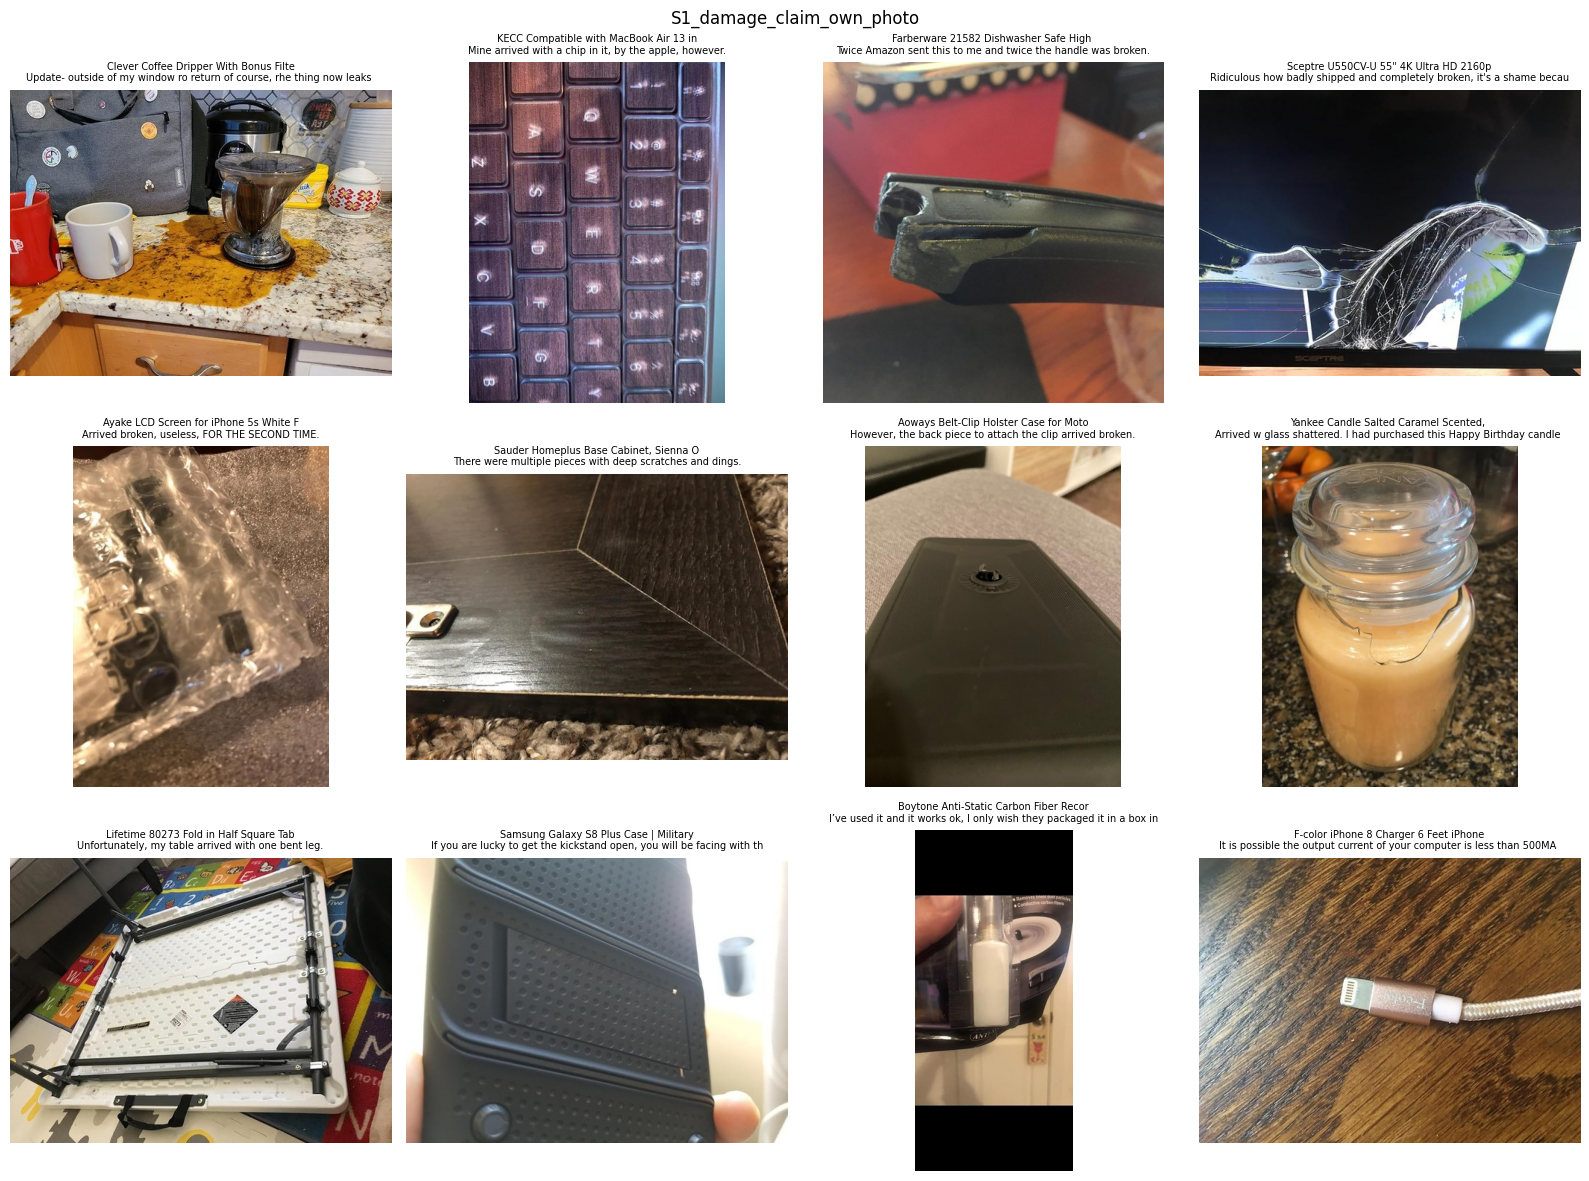

Saved audit_template.csv with 80 rows. Fill the two blank columns, then send me the counts.


In [34]:
import matplotlib.pyplot as plt

recs = list(read_jsonl(B2_DIR / "claims_train.jsonl"))
rng = random.Random(CFG.seed)

def show(scenario, n=12):
    sub = [e for e in recs if e["scenario"] == scenario]
    pick = rng.sample(sub, min(n, len(sub)))
    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    for ax, e in zip(axes.flat, pick):
        ax.imshow(Image.open(ROOT / e["image_path"])); ax.axis("off")
        ax.set_title(f"{e['product_title'][:38]}\n{e['claim_text'][:70]}", fontsize=7)
    for ax in list(axes.flat)[len(pick):]:
        ax.axis("off")
    fig.suptitle(scenario); plt.tight_layout(); plt.show()

show(S1)      # does each photo actually look damaged? Try S2 and S4 too.

audit = []
for scn, n in ((S1, 40), (S2, 20), (S4, 20)):
    sub = [e for e in recs if e["scenario"] == scn]
    audit += [{"example_id": e["example_id"], "scenario": scn, "image_path": e["image_path"], "product_title": e["product_title"],
               "claim_text": e["claim_text"], "human_damage_visible(yes/no/unclear)": "", "human_product_match(yes/no/unclear)": ""}
              for e in rng.sample(sub, min(n, len(sub)))]
pd.DataFrame(audit).to_csv(guard_write(B2_DIR / "audit_template.csv"), index=False)
print("Saved audit_template.csv with", len(audit), "rows. Fill the two blank columns, then send me the counts.")

In [35]:
# B2-2 DIAGNOSTIC (read-only): confirm label false positives/negatives before changing any rule
import json, random
from pathlib import Path
B2 = Path("/kaggle/working/returnlens/data/b2")
B1 = Path("/kaggle/working/returnlens/data/processed")
def rj(p):
    with open(p, encoding="utf-8") as f:
        for l in f:
            if l.strip(): yield json.loads(l)
lab = {(x["category"], x["source_line"]): x for x in rj(B2/"review_rule_labels.jsonl")}
txt = {(r["category"], r["source_line"]): r for r in rj(B1/"reviews_clean_v2.jsonl")}

print("A) ALL ambiguous_negated_or_packaging (full text, 300 chars)\n")
for k, x in lab.items():
    if x["rule_label"] == "ambiguous_negated_or_packaging":
        print(f"[{x['rating']:.0f}*] {txt[k]['text'][:300]!r}\n")

print("="*80, "\nB) 20 random damage_claim_strict claims (mark each: REAL damage / NOT damage)\n")
strict = sorted([k for k, x in lab.items() if x["rule_label"] == "damage_claim_strict" and x["usable"]])
random.Random(7).shuffle(strict)
for i, k in enumerate(strict[:20], 1):
    print(f"{i:>2}. {lab[k]['claim_text']!r}")

A) ALL ambiguous_negated_or_packaging (full text, 300 chars)

[1*] 'I’ve been using this for only less than a week and it’s already not working. It scratches several of my rare vinyls, and it stopped playing. Such a bad product'

[1*] 'Straight out of the box. Completely broken.'

[2*] 'Very disappointed. This is the second time I purchased a B&W filter from Amazon the came with a broken seal on box... dust on the filter glass... the plastic hinge on the filter box appears to have been opened multiple times ( the stress fractures you see on plastic hinges... and the foam was obviou'

[1*] 'Do not buy this item it does not work! We broke our brand new quarts counter top and we’re super excited even hired a real contracted electrician but it doesn’t charge. Piece of crap don’t waste ur money. The company doesn’t even let you replace the item for the same one. Thank goodness Amazon has g'

[1*] "I ordered this and couldn't believe my eyes when I opened the box.  First of all, it had obvio

In [36]:
# B2-2b DRY RUN (read-only, writes NOTHING): compare improved damage-claim rules vs current labels
import re, json, random, collections
from pathlib import Path
import pandas as pd
B2 = Path("/kaggle/working/returnlens/data/b2")
B1 = Path("/kaggle/working/returnlens/data/processed")
def rj(p):
    with open(p, encoding="utf-8") as f:
        for l in f:
            if l.strip(): yield json.loads(l)

HTML = re.compile(r"<[^>]+>")
def clean(t): return re.sub(r"\s+", " ", HTML.sub(" ", t)).strip()

# participles only: no bare crack/scratch/break verbs ("crack the egg", "cats would scratch")
VIS = re.compile(r"\b(broke|broken|cracked|shattered|smashed|dented|scratched|scratches|torn|tore|bent|snapped|"
                 r"chipped|crumbled|leaked|leaking|melted)\b", re.I)
NEG = re.compile(r"\b(no|not|never|without|nothing)\b|n't\b", re.I)
PACK = re.compile(r"\b(box|package|packaging|packing|shipping|carton|envelope|bag|wrapper)\b", re.I)
PACK_LOC = re.compile(r"\b(in|inside|out of|from|within)\s+(the|its|their|a)\s+(box|package|packaging|carton)\b", re.I)
ITEM = re.compile(r"\b(item|product|arrived|came|all \d|both|handle|lid|screen|glass|base|leg)\b", re.I)
USER = re.compile(
    r"\b(dropped|dropping|knocked|sat on|stepped on|spilled)\b"
    r"|\bwhile (?:i was )?(?:installing|applying|scraping|cleaning|using)\b"
    r"|\bin my (?:\w+ )?(?:backpack|bag|purse|pocket)\b"
    r"|\b(?:my|her|his|their)\s+(?:\w+\s+){0,2}?(?:iphone|phone|screen|tablet|ipad|laptop)\b"
    r"(?!\s*(?:case|cover|protector|holder|mount|charger|stand))[^.!?]{0,25}\b(?:shattered|cracked|smashed)\b", re.I)
FUNC = re.compile(r"(stopped working|doesn'?t work|does not work|not working|won'?t (?:turn on|charge|power on)|"
                  r"dead on arrival|defective|malfunction)", re.I)
ISSUE = re.compile(r"\b(return(?:ed|ing)?|refund(?:ed)?|replacement)\b", re.I)
ARRIVAL = re.compile(r"\b(arrived|arrival|received|opened|opening|unbox\w*|out of the box|delivered|shipped|came|"
                     r"first use|day one|right away|straight out|upon)\b", re.I)

def sentence_of(text, pos):
    for m in re.finditer(r"[^.!?\n]+[.!?]*", text):
        if m.start() <= pos < m.end():
            return m.group().strip()
    return text[:200]

def classify_v2(text, rating):
    """returns (label, evidence_sentence)"""
    if rating <= 2:
        vis = list(VIS.finditer(text))
        if vis:
            reasons, good = [], []
            for m in vis:
                s = sentence_of(text, m.start())
                if NEG.search(text[max(0, m.start() - 25):m.start()]): reasons.append("negated"); continue
                if USER.search(s): reasons.append("user_or_device"); continue
                s2 = PACK_LOC.sub(" ", s)
                if PACK.search(s2) and not ITEM.search(s2): reasons.append("packaging_only"); continue
                good.append(m)
            if good:
                lab = "damage_claim_strict" if ARRIVAL.search(text) else "damage_claim_loose"
                return lab, sentence_of(text, good[0].start())
            return "ambiguous_" + collections.Counter(reasons).most_common(1)[0][0], sentence_of(text, vis[0].start())
        if FUNC.search(text): return "ambiguous_functional_failure_only", None
        return "other_low_rating", None
    if rating >= 4:
        if VIS.search(text) or FUNC.search(text) or ISSUE.search(text): return "ambiguous_positive_with_issue_terms", None
        return "intact_candidate", None
    return "mid_rating", None

old = {(x["category"], x["source_line"]): x for x in rj(B2 / "review_rule_labels.jsonl")}
new, ev, meta = {}, {}, {}
for r in rj(B1 / "reviews_clean_v2.jsonl"):
    k = (r["category"], r["source_line"])
    new[k], ev[k] = classify_v2(clean(r["text"]), r["rating"])
    meta[k] = (r["category"], r["rating"])

def bucket(l):
    return l if l.startswith(("damage_claim", "intact", "mid", "other")) else ("ambiguous_other" if l.startswith("ambiguous_") and "positive" not in l else l)
df = pd.DataFrame({"old": [old[k]["rule_label"] for k in new], "new": [new[k] for k in new], "cat": [meta[k][0] for k in new]})
low = df[df.old.isin(["damage_claim_strict","damage_claim_loose","ambiguous_negated_or_packaging",
                      "ambiguous_functional_failure_only","other_low_rating"])]
print("OLD (rows) vs NEW (cols), low-rating reviews only\n")
print(pd.crosstab(low.old, low.new, margins=True).to_string())
print("\nNEW damage pools per category:")
print(pd.crosstab(df[df.new.str.startswith("damage_claim")].cat, df[df.new.str.startswith("damage_claim")].new, margins=True).to_string())

rnd = random.Random(11)
flip_out = [k for k in new if old[k]["rule_label"].startswith("damage_claim") and not new[k].startswith("damage_claim")]
flip_in = [k for k in new if not old[k]["rule_label"].startswith("damage_claim") and new[k].startswith("damage_claim")]
rnd.shuffle(flip_out); rnd.shuffle(flip_in)
print(f"\n{'='*80}\nREMOVED from damage pool by new rules: {len(flip_out)} (showing 15)\n")
for k in flip_out[:15]: print(f"- [{new[k]}] {ev[k]!r}")
print(f"\n{'='*80}\nADDED to damage pool by new rules: {len(flip_in)} (showing 12)\n")
for k in flip_in[:12]: print(f"- [{old[k]['rule_label']} -> {new[k]}] {ev[k]!r}")
kept = sorted(k for k in new if new[k] == "damage_claim_strict"); rnd.shuffle(kept)
print(f"\n{'='*80}\n20 random NEW damage_claim_strict claims (judge: REAL / NOT)\n")
for i, k in enumerate(kept[:20], 1): print(f"{i:>2}. {ev[k][:200]!r}")

OLD (rows) vs NEW (cols), low-rating reviews only

new                                ambiguous_functional_failure_only  ambiguous_negated  ambiguous_packaging_only  ambiguous_user_or_device  damage_claim_loose  damage_claim_strict  other_low_rating   All
old                                                                                                                                                                                                         
ambiguous_functional_failure_only                                 77                  0                         0                         0                   0                    0                 0    77
ambiguous_negated_or_packaging                                     0                  8                         3                         0                   4                    7                 1    23
damage_claim_loose                                                 3                  1                         5                

In [37]:
# ===== B2-2c READ-ONLY COMPARISON of proposed rule spec v3. Writes NOTHING. =====
import re, json, random, collections
from pathlib import Path
import pandas as pd
pd.set_option("display.width", 230); pd.set_option("display.max_colwidth", 150); pd.set_option("display.max_rows", 200)
B2 = Path("/kaggle/working/returnlens/data/b2")
B1 = Path("/kaggle/working/returnlens/data/processed")
def rj(p):
    with open(p, encoding="utf-8") as f:
        for l in f:
            if l.strip(): yield json.loads(l)
def clean(t): return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", t)).strip()

# ---------------- PROPOSED RULES v3 ----------------
VERB = re.compile(r"\b(?:broke|broken|cracked|shattered|smashed|dented|scratched|torn|tore|bent|snapped|chipped|"
                  r"crumbled|deformed|warped)\b", re.I)
NOUN = re.compile(r"\b(?:a|an|two|three|four|some|big|small|several|many|deep|few|large|tiny|huge|minor|major)\s+"
                  r"(?:[\w-]+\s+){0,2}(?:cracks?|dents?|scratch(?:es)?)\b(?![- ]?(?:resist|proof|guard|free))"
                  r"|\b(?:cracks|dents|scratches)\b", re.I)
NEG = re.compile(r"\b(?:no|not|never|without|nothing)\b|n['’]t\b", re.I)
PREVENT = re.compile(r"\b(?:protect|prevent|stop|resist|avoid|guard)\w*\b", re.I)
DELIM = re.compile(r"\b(?:but|and|however|though|while|because)\b|[,;:()]", re.I)
PACKW = re.compile(r"(?:box|package|packaging|packing|pkg|carton|envelope|bag|wrapper|seal|shipping)", re.I)
PACK_LOC = re.compile(r"\b(?:in|inside|out of|from|within)\s+(?:the|its|their|a|an)?\s*(?:box|package|packaging|carton|pkg)\b", re.I)
USER = re.compile(
    r"\b(?:dropped|dropping|knocked|sat on|stepped on|spilled|fell off)\b"
    r"|\b(?:as|when|while)\s+(?:i|we|she|he|they)\s+(?:was|were)\s+(?!opening|unboxing|unpacking|checking|reading|looking|watching)\w+ing\b"
    r"|\b(?:trying|tried|attempt\w*)\s+to\b|\bcaught\s+(?:on|in|against)\b"
    r"|\b(?:i|we)\s+(?:put|placed|stuffed|threw)\b[^.!?]{0,30}\b(?:in|into|back)\b"
    r"|\bin my (?:\w+ )?(?:backpack|bag|purse|pocket)\b"
    r"|\b(?:my|her|his|their)\s+(?:\w+\s+){0,2}?(?:iphone|phone|screen|tablet|ipad|laptop)\b"
    r"(?!\s*(?:case|cover|protector|holder|mount|charger|stand))[^.!?]{0,25}\b(?:shattered|cracked|smashed)\b", re.I)
FUNC = re.compile(r"(?:stopped working|doesn['’]?t work|does not work|not working|won['’]?t (?:turn on|charge|power on)|"
                  r"wouldn['’]?t (?:turn on|charge|power on)|dead on arrival|defective|malfunction|leak\w*|"
                  r"no longer work\w*|turned off)", re.I)
STRONG_POST = re.compile(r"\bafter (?:a|an|one|two|three|\d+|several|few|about|only)\s+(?:\w+\s+)?(?:days?|weeks?|months?|years?|uses?|washes)\b"
                         r"|\b(?:had|have had|used|using|owned)\s+(?:it|them|this)\b"
                         r"|\bfor (?:a|an|one|two|three|\d+|several|few)\s+(?:\w+\s+)?(?:days?|weeks?|months?|years?)\b"
                         r"|\bat some point\b|\beventually\b|\bover time\b|\bstarted\b|\bstopped\b"
                         r"|\b(?:days?|weeks?|months?|years?|hours?)\s+(?:later|after|ago)\b|\bwithin\b|\bafter (?:using|use|installing|wearing)\b", re.I)
WEAK_POST = re.compile(r"\balready\b|\bfirst (?:time|use)\b", re.I)
ARRIVAL = re.compile(r"\b(?:arrived|arrival|received|unbox(?:ed|ing)|opened|opening|delivered|shipped|in transit|"
                     r"upon (?:arrival|opening|receipt|receiving)|out of (?:the )?(?:box|package|pkg)|"
                     r"came (?:all |completely |totally )?(?:broken|cracked|damaged|dented|scratched|bent|smashed|shattered|torn|deformed|in|with))\b", re.I)
PHOTO = re.compile(r"\b(?:pic|pics|picture|pictures|photo|photos|image|images|attached|attachment|see below|shown)\b", re.I)
PII = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+|\b\d{3}[-.\s]?\d{3}[-.\s]?\d{4}\b")
SENT = re.compile(r"[^.!?\n]+[.!?]*")
RANK = ["damage_claim_strict", "damage_claim_loose", "post_use_damage", "needs_human_mixed", "damage_low_context",
        "ambiguous_user_caused", "ambiguous_packaging_only", "ambiguous_negated_or_preventive"]

def hits_in(s): return list(VERB.finditer(s)) + list(NOUN.finditer(s))

def analyze(text):
    sents = [m.group().strip() for m in SENT.finditer(text) if m.group().strip()]
    found = []
    for i, s in enumerate(sents):
        hits = hits_in(s)
        if not hits: continue
        ok = []
        for m in hits:
            before = DELIM.split(s[max(0, m.start() - 40):m.start()])[-1]
            if NEG.search(before[-25:]) or PREVENT.search(before): continue
            ok.append(m)
        if not ok: found.append(("ambiguous_negated_or_preventive", s)); continue
        if USER.search(s): found.append(("ambiguous_user_caused", s)); continue
        s2 = PACK_LOC.sub(" LOCPH ", s)
        h2 = hits_in(s2); pack_only = bool(h2)
        for m in h2:
            left = re.findall(r"\w+", DELIM.split(s2[:m.start()])[-1])[-7:]
            right = re.findall(r"\w+", DELIM.split(s2[m.end():])[0])[:4]
            if not any(PACKW.fullmatch(w) for w in left + right): pack_only = False; break
        if pack_only: found.append(("ambiguous_packaging_only", s)); continue
        if FUNC.search(s): found.append(("needs_human_mixed", s)); continue
        if len(re.findall(r"\w+", s)) <= 3: found.append(("damage_low_context", s)); continue
        nb = [sents[j] for j in (i - 1, i + 1) if 0 <= j < len(sents)]
        if STRONG_POST.search(s): lab = "post_use_damage"
        elif ARRIVAL.search(s): lab = "damage_claim_strict"
        elif WEAK_POST.search(s): lab = "post_use_damage"
        elif any(ARRIVAL.search(x) and not STRONG_POST.search(x) and not WEAK_POST.search(x) for x in nb): lab = "damage_claim_strict"
        else: lab = "damage_claim_loose"
        found.append((lab, s))
    if not found:
        return ("ambiguous_functional_failure_only" if FUNC.search(text) else "other_low_rating"), None, set()
    best = min(found, key=lambda x: RANK.index(x[0]))
    return best[0], best[1], {l for l, _ in found}

def usable_claim(ev):
    if not ev: return False
    cfg = globals().get("CFG")
    mn = getattr(cfg, "claim_min_chars", 25); mx = getattr(cfg, "claim_max_chars", 300)
    asc = sum(ord(c) < 128 for c in ev) / max(len(ev), 1)
    return mn <= len(ev) <= mx and not PHOTO.search(ev) and not PII.search(ev) and asc >= 0.9

# ---------------- SELFTEST on the 20 reviewed claims ----------------
ST = [("It came all broken has a big dent on the side.", "damage_claim_strict"),
 ("I just now unboxed to find two good size scratches.", "damage_claim_strict"),
 ("But I dont use my laptop often and have had it for a week, the case is just tacky looking and is already cracked.", "post_use_damage"),
 ("At some point, the material gave way and the boss for the screw broke out (see pics).", "post_use_damage"),
 ("The front edge corners are all battered into broken bits with the enamel veneer peeling off.", "damage_claim_loose"),
 ("This arrived today completely deformed, torn, and unusable.", "damage_claim_strict"),
 ("Ridiculous how badly shipped and completely broken, it's a shame because it looked like it was going to be descent for the price.", "damage_claim_strict"),
 ("I would like to have four replaced, as 4 came broken.", "damage_claim_strict"),
 ("It came broken and cracked.", "damage_claim_strict"),
 ("It had also somehow started leaking grounds.", "ambiguous_functional_failure_only"),
 ("Tablet screen was scratched pretty bad and it wouldn't power on at first so I charged it to 100% powered on and 3 minutes later it turned off.", "needs_human_mixed"),
 ("The monitor protector arrived bent at the corners, and does not stick flush to the screen.", "damage_claim_strict"),
 ("Just opened don't know nor have the time to return but I would because it came broken ...", "damage_claim_strict"),
 ("The hinge on everyone of these was broken upon arrival.", "damage_claim_strict"),
 ("I received a case was a defective product which lid never close completely due to the unnecessary spaces in the bent part.", "needs_human_mixed"),
 ("Completely broken.", "damage_low_context"),
 ("The paint is cracked and it looks like we would need to caulk it for it to possibly look decent.", "damage_claim_loose"),
 ("It super easily broke off when trying to fish it out with tweezers.", "ambiguous_user_caused"),
 ("As I was scrapping the screen, from bottom to top (again as Instructed to do), the scrapper caught the bottom of the protector and shattered it.", "ambiguous_user_caused"),
 ("Opened Pkg and one of them was broken out of pkg.", "damage_claim_strict")]
# note: list has 20 entries in the same order as the annotation table (IDs 1-20)
print("SELFTEST (expected vs actual on the 20 reviewed claims)")
bad = 0
for i, (t, exp) in enumerate(ST, 1):
    got = analyze(clean(t))[0]
    bad += got != exp
    print(f"  #{i:>2} {'PASS' if got == exp else 'FAIL'}  expected={exp}  got={got}")
print(f"  -> {len(ST) - bad}/{len(ST)} pass\n")

# ---------------- RUN ON ALL LOW-RATING REVIEWS ----------------
old = {(x["category"], x["source_line"]): x for x in rj(B2 / "review_rule_labels.jsonl")}
rows = []
for r in rj(B1 / "reviews_clean_v2.jsonl"):
    if r["rating"] > 2: continue
    k = (r["category"], r["source_line"]); o = old[k]; txt = clean(r["text"])
    lab, ev, tiers = analyze(txt)
    rows.append(dict(category=r["category"], parent_asin=r["parent_asin"], split=o["split"], old=o["rule_label"],
                     old_claim=o["claim_text"], new=lab, ev=ev, tiers=tiers, ok=usable_claim(ev), text=txt))
D = pd.DataFrame(rows)
T3 = ["damage_claim_strict", "damage_claim_loose", "post_use_damage"]
print(f"low-rating (<=2) reviews analysed: {len(D):,} (mid/high ratings unchanged)\n")

print("=" * 90, "\n1) RECORD COUNTS (all low-rating reviews)\n")
print(pd.crosstab(D.new, D.category, margins=True).to_string())
print("\n   by split (all):"); print(pd.crosstab(D.new, D.split, margins=True).to_string())
print("\n   by split (usable claim only):"); print(pd.crosstab(D[D.ok].new, D[D.ok].split, margins=True).to_string())

print("\n" + "=" * 90, "\n2) OLD (rows) -> NEW (cols)\n")
print(pd.crosstab(D.old, D.new, margins=True).to_string())

print("\n" + "=" * 90, "\n3) OVERLAP between tiers\n")
multi = D[D.tiers.apply(lambda t: len(t & set(T3)) > 1)]
print(f"reviews with more than one damage tier in different sentences: {len(multi)}")
print(collections.Counter(tuple(sorted(t & set(T3))) for t in multi.tiers))
A = D[(D.new == "damage_claim_strict") & D.ok]; B = D[D.new.isin(T3) & D.ok]
print(f"\nApproach A (strict-only, usable): {len(A)} | Approach B (strict+loose+post_use, usable): {len(B)} | B minus A: {len(B) - len(A)}")
print(pd.crosstab(B.new, B.split, margins=True).to_string())

print("\n" + "=" * 90, "\n4) POTENTIAL FALSE POSITIVES\n")
MARK = {"packaging_word": re.compile(r"\b(box|package|packaging|pkg|carton|envelope|bag|wrapper|seal)\b", re.I),
        "hedge": re.compile(r"\b(seems?|might|maybe|looks like|appears?|probably|i think)\b", re.I),
        "second_hand": re.compile(r"\b(my|her|his|our) (husband|wife|son|daughter|kid|kids|mom|dad|friend)\b", re.I),
        "functional_word": FUNC, "photo_ref": PHOTO}
mk = []
for lab in T3 + ["needs_human_mixed", "damage_low_context"]:
    s = D[D.new == lab]
    mk.append({"class": lab, "n": len(s), **{m: f"{100 * s.ev.fillna('').apply(lambda e: bool(rx.search(e))).mean():.0f}%" if len(s) else "-" for m, rx in MARK.items()}})
print("risk markers inside the evidence sentence (share of class):"); print(pd.DataFrame(mk).to_string(index=False))
rnd = random.Random(21)
for lab in T3 + ["needs_human_mixed", "damage_low_context"]:
    s = D[D.new == lab].ev.dropna().tolist(); rnd.shuffle(s)
    print(f"\n-- {lab}: {len(s)} total, 10 random (judge REAL/NOT):")
    for e in s[:10]: print("   -", repr(e[:170]))

print("\n" + "=" * 90, "\n5) POTENTIAL FALSE NEGATIVES\n")
lost = D[D.old.str.startswith("damage_claim") & ~D.new.isin(T3)]
print(f"old damage_claim_* now NOT in strict/loose/post_use: {len(lost)} | by new label: {dict(lost.new.value_counts())}")
ls = lost.sample(min(20, len(lost)), random_state=5)
for _, x in ls.iterrows(): print(f"   - [{x.new}] OLD CLAIM: {str(x.old_claim)[:150]!r}")
RES = re.compile(r"\b(damaged|crushed|ripped|dinged|bashed|chewed|stained|missing|dirty)\b", re.I)
oth = D[D.new.isin(["other_low_rating", "ambiguous_functional_failure_only"])]
cnt = collections.Counter(w.lower() for t in oth.text for w in set(RES.findall(t)))
print(f"\nlow-rating reviews NOT in any damage class but containing residual damage words: {dict(cnt)} (of {len(oth)})")
res_s = [(x.new, next((s for s in re.findall(r"[^.!?\n]+", x.text) if RES.search(s)), "")) for x in oth.itertuples() if RES.search(x.text)]
rnd.shuffle(res_s)
for lab, s in res_s[:15]: print(f"   - [{lab}] {s.strip()[:150]!r}")

print("\n" + "=" * 90, "\n6) DOWNSTREAM CAPACITY (S1 / S2), approximate, claim filters approximated\n")
I_cnt = {sp: collections.Counter() for sp in ("train", "val", "gold_pool")}
for o in old.values():
    if o["rule_label"] == "intact_candidate" and o["usable"]: I_cnt[o["split"]][o["parent_asin"]] += 1
SETS = {"A strict only": ["damage_claim_strict"],
        "B-S1 strict+loose+post_use": T3,
        "B-S2 strict+loose (post_use excluded)": ["damage_claim_strict", "damage_claim_loose"]}
cap = []
for name, tiers in SETS.items():
    P = D[D.new.isin(tiers) & D.ok]
    for sp in ("train", "val", "gold_pool"):
        Ps = P[P.split == sp]; dc = Ps.parent_asin.value_counts()
        both = [a for a in dc.index if I_cnt[sp][a] > 0]
        cap.append({"set": name, "split": sp, "S1_candidates": len(Ps), "S1_after_~8pct_404": int(len(Ps) * 0.92),
                    "S2_products": len(both), "S2_max_pairs": sum(min(dc[a], I_cnt[sp][a]) for a in both)})
print(pd.DataFrame(cap).to_string(index=False))
print("\nREAD-ONLY DONE. Nothing was written.")

SELFTEST (expected vs actual on the 20 reviewed claims)
  # 1 PASS  expected=damage_claim_strict  got=damage_claim_strict
  # 2 PASS  expected=damage_claim_strict  got=damage_claim_strict
  # 3 PASS  expected=post_use_damage  got=post_use_damage
  # 4 PASS  expected=post_use_damage  got=post_use_damage
  # 5 PASS  expected=damage_claim_loose  got=damage_claim_loose
  # 6 PASS  expected=damage_claim_strict  got=damage_claim_strict
  # 7 PASS  expected=damage_claim_strict  got=damage_claim_strict
  # 8 PASS  expected=damage_claim_strict  got=damage_claim_strict
  # 9 PASS  expected=damage_claim_strict  got=damage_claim_strict
  #10 PASS  expected=ambiguous_functional_failure_only  got=ambiguous_functional_failure_only
  #11 PASS  expected=needs_human_mixed  got=needs_human_mixed
  #12 FAIL  expected=damage_claim_strict  got=ambiguous_negated_or_preventive
  #13 PASS  expected=damage_claim_strict  got=damage_claim_strict
  #14 PASS  expected=damage_claim_strict  got=damage_claim_strict
  

In [38]:
# ===== B2-2d READ-ONLY: rule spec v4 (v3 + 2 narrow negation fixes) vs v3. Writes NOTHING. =====
# Fix 1: 'protector(s)' (product noun) no longer counts as the preventive verb 'protect'.
# Fix 2: negation/prevention scope carries across a bare noun list ('no dents, scratches, or cracks').
# Flags FIX_PROTECTOR / FIX_LIST = False reproduces v3 exactly (verified).
import re, json, random, collections
from pathlib import Path
import pandas as pd
pd.set_option("display.width", 230); pd.set_option("display.max_colwidth", 150); pd.set_option("display.max_rows", 200)
B2 = Path("/kaggle/working/returnlens/data/b2")
B1 = Path("/kaggle/working/returnlens/data/processed")
def rj(p):
    with open(p, encoding="utf-8") as f:
        for l in f:
            if l.strip(): yield json.loads(l)
def clean(t): return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", t)).strip()

# ---------------- PROPOSED RULES v3 ----------------
VERB = re.compile(r"\b(?:broke|broken|cracked|shattered|smashed|dented|scratched|torn|tore|bent|snapped|chipped|"
                  r"crumbled|deformed|warped)\b", re.I)
NOUN = re.compile(r"\b(?:a|an|two|three|four|some|big|small|several|many|deep|few|large|tiny|huge|minor|major)\s+"
                  r"(?:[\w-]+\s+){0,2}(?:cracks?|dents?|scratch(?:es)?)\b(?![- ]?(?:resist|proof|guard|free))"
                  r"|\b(?:cracks|dents|scratches)\b", re.I)
NEG = re.compile(r"\b(?:no|not|never|without|nothing)\b|n['’]t\b", re.I)
PREVENT = re.compile(r"\b(?:protect|prevent|stop|resist|avoid|guard)\w*\b", re.I)
DELIM = re.compile(r"\b(?:but|and|however|though|while|because)\b|[,;:()]", re.I)
PACKW = re.compile(r"(?:box|package|packaging|packing|pkg|carton|envelope|bag|wrapper|seal|shipping)", re.I)
PACK_LOC = re.compile(r"\b(?:in|inside|out of|from|within)\s+(?:the|its|their|a|an)?\s*(?:box|package|packaging|carton|pkg)\b", re.I)
USER = re.compile(
    r"\b(?:dropped|dropping|knocked|sat on|stepped on|spilled|fell off)\b"
    r"|\b(?:as|when|while)\s+(?:i|we|she|he|they)\s+(?:was|were)\s+(?!opening|unboxing|unpacking|checking|reading|looking|watching)\w+ing\b"
    r"|\b(?:trying|tried|attempt\w*)\s+to\b|\bcaught\s+(?:on|in|against)\b"
    r"|\b(?:i|we)\s+(?:put|placed|stuffed|threw)\b[^.!?]{0,30}\b(?:in|into|back)\b"
    r"|\bin my (?:\w+ )?(?:backpack|bag|purse|pocket)\b"
    r"|\b(?:my|her|his|their)\s+(?:\w+\s+){0,2}?(?:iphone|phone|screen|tablet|ipad|laptop)\b"
    r"(?!\s*(?:case|cover|protector|holder|mount|charger|stand))[^.!?]{0,25}\b(?:shattered|cracked|smashed)\b", re.I)
FUNC = re.compile(r"(?:stopped working|doesn['’]?t work|does not work|not working|won['’]?t (?:turn on|charge|power on)|"
                  r"wouldn['’]?t (?:turn on|charge|power on)|dead on arrival|defective|malfunction|leak\w*|"
                  r"no longer work\w*|turned off)", re.I)
STRONG_POST = re.compile(r"\bafter (?:a|an|one|two|three|\d+|several|few|about|only)\s+(?:\w+\s+)?(?:days?|weeks?|months?|years?|uses?|washes)\b"
                         r"|\b(?:had|have had|used|using|owned)\s+(?:it|them|this)\b"
                         r"|\bfor (?:a|an|one|two|three|\d+|several|few)\s+(?:\w+\s+)?(?:days?|weeks?|months?|years?)\b"
                         r"|\bat some point\b|\beventually\b|\bover time\b|\bstarted\b|\bstopped\b"
                         r"|\b(?:days?|weeks?|months?|years?|hours?)\s+(?:later|after|ago)\b|\bwithin\b|\bafter (?:using|use|installing|wearing)\b", re.I)
WEAK_POST = re.compile(r"\balready\b|\bfirst (?:time|use)\b", re.I)
ARRIVAL = re.compile(r"\b(?:arrived|arrival|received|unbox(?:ed|ing)|opened|opening|delivered|shipped|in transit|"
                     r"upon (?:arrival|opening|receipt|receiving)|out of (?:the )?(?:box|package|pkg)|"
                     r"came (?:all |completely |totally )?(?:broken|cracked|damaged|dented|scratched|bent|smashed|shattered|torn|deformed|in|with))\b", re.I)
PHOTO = re.compile(r"\b(?:pic|pics|picture|pictures|photo|photos|image|images|attached|attachment|see below|shown)\b", re.I)
PII = re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+|\b\d{3}[-.\s]?\d{3}[-.\s]?\d{4}\b")
SENT = re.compile(r"[^.!?\n]+[.!?]*")
RANK = ["damage_claim_strict", "damage_claim_loose", "post_use_damage", "needs_human_mixed", "damage_low_context",
        "ambiguous_user_caused", "ambiguous_packaging_only", "ambiguous_negated_or_preventive"]

def hits_in(s): return list(VERB.finditer(s)) + list(NOUN.finditer(s))


FIX_PROTECTOR, FIX_LIST = True, False
PREVENT_V4 = re.compile(r"\b(?:protect(?!ors?\b)|prevent|stop|resist|avoid|guard)\w*\b", re.I)
LIST_GAP = re.compile(r"^\s*(?:,\s*(?:and\s+|or\s+|nor\s+)?|(?:and|or|nor|&|/)\s+)(?:(?:any|a|an|some|the)\s+)?$", re.I)

def ok_hits(s):
    """damage hits NOT suppressed by negation/prevention. v3 logic + the two flagged fixes."""
    prev = PREVENT_V4 if FIX_PROTECTOR else PREVENT
    hs = sorted([(m, "N") for m in NOUN.finditer(s)] + [(m, "V") for m in VERB.finditer(s)], key=lambda x: x[0].start())
    out, last = [], None
    for m, k in hs:
        before = DELIM.split(s[max(0, m.start() - 40):m.start()])[-1]
        sup = bool(NEG.search(before[-25:]) or prev.search(before))
        if (not sup and FIX_LIST and last and k == "N" and last[1] == "N" and last[2]
                and LIST_GAP.match(s[last[0].end():m.start()])):
            sup = True
        last = (m, k, sup)
        if not sup: out.append(m)
    return out

def analyze_as(text, fp, fl):
    global FIX_PROTECTOR, FIX_LIST
    old = (FIX_PROTECTOR, FIX_LIST); FIX_PROTECTOR, FIX_LIST = fp, fl
    try: return analyze(text)
    finally: FIX_PROTECTOR, FIX_LIST = old

def analyze(text):
    sents = [m.group().strip() for m in SENT.finditer(text) if m.group().strip()]
    found = []
    for i, s in enumerate(sents):
        hits = hits_in(s)
        if not hits: continue
        ok = ok_hits(s)
        if not ok: found.append(("ambiguous_negated_or_preventive", s)); continue
        if USER.search(s): found.append(("ambiguous_user_caused", s)); continue
        s2 = PACK_LOC.sub(" LOCPH ", s)
        h2 = hits_in(s2); pack_only = bool(h2)
        for m in h2:
            left = re.findall(r"\w+", DELIM.split(s2[:m.start()])[-1])[-7:]
            right = re.findall(r"\w+", DELIM.split(s2[m.end():])[0])[:4]
            if not any(PACKW.fullmatch(w) for w in left + right): pack_only = False; break
        if pack_only: found.append(("ambiguous_packaging_only", s)); continue
        if FUNC.search(s): found.append(("needs_human_mixed", s)); continue
        if len(re.findall(r"\w+", s)) <= 3: found.append(("damage_low_context", s)); continue
        nb = [sents[j] for j in (i - 1, i + 1) if 0 <= j < len(sents)]
        if STRONG_POST.search(s): lab = "post_use_damage"
        elif ARRIVAL.search(s): lab = "damage_claim_strict"
        elif WEAK_POST.search(s): lab = "post_use_damage"
        elif any(ARRIVAL.search(x) and not STRONG_POST.search(x) and not WEAK_POST.search(x) for x in nb): lab = "damage_claim_strict"
        else: lab = "damage_claim_loose"
        found.append((lab, s))
    if not found:
        return ("ambiguous_functional_failure_only" if FUNC.search(text) else "other_low_rating"), None, set()
    best = min(found, key=lambda x: RANK.index(x[0]))
    return best[0], best[1], {l for l, _ in found}

def usable_claim(ev):
    if not ev: return False
    cfg = globals().get("CFG")
    mn = getattr(cfg, "claim_min_chars", 25); mx = getattr(cfg, "claim_max_chars", 300)
    asc = sum(ord(c) < 128 for c in ev) / max(len(ev), 1)
    return mn <= len(ev) <= mx and not PHOTO.search(ev) and not PII.search(ev) and asc >= 0.9


PROBE = ["The monitor protector arrived bent at the corners, and does not stick flush to the screen.",
 "Never had a dent or scratch", "Never had a dent and scratches", "No dents, scratches, or cracks.",
 "It has no cracks and scratches", "Without any dents, cracks or scratches.", "This case protects against scratches and dents.",
 "2 of the 3 screen protectors were cracked over a majority of the surface.", "The screen protector had a large section that was smashed.",
 "This protector prevents scratches.", "The screen guard arrived cracked.", "No dents but scratches all over the screen.",
 "It arrived with no dents, but a crack in the base.", "No dents, and it arrived with cracks across the glass.",
 "It had no dents and scratches on the back were deep.", "Arrived with a dent, scratches, and cracks."]
print("0) NEGATION PROBE (v3 -> v4); probes are NOT part of the 20 approved self-tests")
for t in PROBE: print(f"   {analyze_as(t, False, False)[0][:24]:24} -> {analyze_as(t, True, True)[0][:24]:24} | {t[:95]}")
print()
# ---------------- SELFTEST on the 20 reviewed claims ----------------
ST = [("It came all broken has a big dent on the side.", "damage_claim_strict"),
 ("I just now unboxed to find two good size scratches.", "damage_claim_strict"),
 ("But I dont use my laptop often and have had it for a week, the case is just tacky looking and is already cracked.", "post_use_damage"),
 ("At some point, the material gave way and the boss for the screw broke out (see pics).", "post_use_damage"),
 ("The front edge corners are all battered into broken bits with the enamel veneer peeling off.", "damage_claim_loose"),
 ("This arrived today completely deformed, torn, and unusable.", "damage_claim_strict"),
 ("Ridiculous how badly shipped and completely broken, it's a shame because it looked like it was going to be descent for the price.", "damage_claim_strict"),
 ("I would like to have four replaced, as 4 came broken.", "damage_claim_strict"),
 ("It came broken and cracked.", "damage_claim_strict"),
 ("It had also somehow started leaking grounds.", "ambiguous_functional_failure_only"),
 ("Tablet screen was scratched pretty bad and it wouldn't power on at first so I charged it to 100% powered on and 3 minutes later it turned off.", "needs_human_mixed"),
 ("The monitor protector arrived bent at the corners, and does not stick flush to the screen.", "damage_claim_strict"),
 ("Just opened don't know nor have the time to return but I would because it came broken ...", "damage_claim_strict"),
 ("The hinge on everyone of these was broken upon arrival.", "damage_claim_strict"),
 ("I received a case was a defective product which lid never close completely due to the unnecessary spaces in the bent part.", "needs_human_mixed"),
 ("Completely broken.", "damage_low_context"),
 ("The paint is cracked and it looks like we would need to caulk it for it to possibly look decent.", "damage_claim_loose"),
 ("It super easily broke off when trying to fish it out with tweezers.", "ambiguous_user_caused"),
 ("As I was scrapping the screen, from bottom to top (again as Instructed to do), the scrapper caught the bottom of the protector and shattered it.", "ambiguous_user_caused"),
 ("Opened Pkg and one of them was broken out of pkg.", "damage_claim_strict")]
# note: list has 20 entries in the same order as the annotation table (IDs 1-20)
print("SELFTEST (expected vs actual on the 20 reviewed claims)")
bad = 0
for i, (t, exp) in enumerate(ST, 1):
    got = analyze(clean(t))[0]; g3 = analyze_as(clean(t), False, False)[0]
    bad += got != exp
    print(f"  #{i:>2} {'PASS' if got == exp else 'FAIL'}  expected={exp}  got={got}" + ("" if g3 == got else f"   (v3 gave {g3})"))
print(f"  -> v4: {len(ST) - bad}/{len(ST)} pass | v3: {sum(analyze_as(clean(t), False, False)[0] == e for t, e in ST)}/{len(ST)} pass\n")

# ---------------- RUN ON ALL LOW-RATING REVIEWS ----------------
old = {(x["category"], x["source_line"]): x for x in rj(B2 / "review_rule_labels.jsonl")}
rows = []
for r in rj(B1 / "reviews_clean_v2.jsonl"):
    if r["rating"] > 2: continue
    k = (r["category"], r["source_line"]); o = old[k]; txt = clean(r["text"])
    lab, ev, tiers = analyze(txt); lab3 = analyze_as(txt, False, False)[0]
    rows.append(dict(category=r["category"], parent_asin=r["parent_asin"], split=o["split"], old=o["rule_label"],
                     old_claim=o["claim_text"], new=lab, new_v3=lab3, ev=ev, tiers=tiers, ok=usable_claim(ev), text=txt))
D = pd.DataFrame(rows)
T3 = ["damage_claim_strict", "damage_claim_loose", "post_use_damage"]
print(f"low-rating (<=2) reviews analysed: {len(D):,} (mid/high ratings unchanged)\n")

print("=" * 90, "\n1) RECORD COUNTS (all low-rating reviews)\n")
print(pd.crosstab(D.new, D.category, margins=True).to_string())
print("\n   by split (all):"); print(pd.crosstab(D.new, D.split, margins=True).to_string())
print("\n   by split (usable claim only):"); print(pd.crosstab(D[D.ok].new, D[D.ok].split, margins=True).to_string())

print("\n" + "=" * 90, "\n2) OLD (rows) -> NEW (cols)\n")
print(pd.crosstab(D.old, D.new, margins=True).to_string())

print("\n" + "=" * 90, "\n3) OVERLAP between tiers\n")
multi = D[D.tiers.apply(lambda t: len(t & set(T3)) > 1)]
print(f"reviews with more than one damage tier in different sentences: {len(multi)}")
print(collections.Counter(tuple(sorted(t & set(T3))) for t in multi.tiers))
A = D[(D.new == "damage_claim_strict") & D.ok]; B = D[D.new.isin(T3) & D.ok]
print(f"\nApproach A (strict-only, usable): {len(A)} | Approach B (strict+loose+post_use, usable): {len(B)} | B minus A: {len(B) - len(A)}")
print(pd.crosstab(B.new, B.split, margins=True).to_string())

print("\n" + "=" * 90, "\n4) POTENTIAL FALSE POSITIVES\n")
MARK = {"packaging_word": re.compile(r"\b(box|package|packaging|pkg|carton|envelope|bag|wrapper|seal)\b", re.I),
        "hedge": re.compile(r"\b(seems?|might|maybe|looks like|appears?|probably|i think)\b", re.I),
        "second_hand": re.compile(r"\b(my|her|his|our) (husband|wife|son|daughter|kid|kids|mom|dad|friend)\b", re.I),
        "functional_word": FUNC, "photo_ref": PHOTO}
mk = []
for lab in T3 + ["needs_human_mixed", "damage_low_context"]:
    s = D[D.new == lab]
    mk.append({"class": lab, "n": len(s), **{m: f"{100 * s.ev.fillna('').apply(lambda e: bool(rx.search(e))).mean():.0f}%" if len(s) else "-" for m, rx in MARK.items()}})
print("risk markers inside the evidence sentence (share of class):"); print(pd.DataFrame(mk).to_string(index=False))
rnd = random.Random(21)
for lab in T3 + ["needs_human_mixed", "damage_low_context"]:
    s = D[D.new == lab].ev.dropna().tolist(); rnd.shuffle(s)
    print(f"\n-- {lab}: {len(s)} total, 10 random (judge REAL/NOT):")
    for e in s[:10]: print("   -", repr(e[:170]))

print("\n" + "=" * 90, "\n5) POTENTIAL FALSE NEGATIVES\n")
lost = D[D.old.str.startswith("damage_claim") & ~D.new.isin(T3)]
print(f"old damage_claim_* now NOT in strict/loose/post_use: {len(lost)} | by new label: {dict(lost.new.value_counts())}")
ls = lost.sample(min(20, len(lost)), random_state=5)
for _, x in ls.iterrows(): print(f"   - [{x.new}] OLD CLAIM: {str(x.old_claim)[:150]!r}")
RES = re.compile(r"\b(damaged|crushed|ripped|dinged|bashed|chewed|stained|missing|dirty)\b", re.I)
oth = D[D.new.isin(["other_low_rating", "ambiguous_functional_failure_only"])]
cnt = collections.Counter(w.lower() for t in oth.text for w in set(RES.findall(t)))
print(f"\nlow-rating reviews NOT in any damage class but containing residual damage words: {dict(cnt)} (of {len(oth)})")
res_s = [(x.new, next((s for s in re.findall(r"[^.!?\n]+", x.text) if RES.search(s)), "")) for x in oth.itertuples() if RES.search(x.text)]
rnd.shuffle(res_s)
for lab, s in res_s[:15]: print(f"   - [{lab}] {s.strip()[:150]!r}")

print("\n" + "=" * 90, "\n6) DOWNSTREAM CAPACITY (S1 / S2), approximate, claim filters approximated\n")
I_cnt = {sp: collections.Counter() for sp in ("train", "val", "gold_pool")}
for o in old.values():
    if o["rule_label"] == "intact_candidate" and o["usable"]: I_cnt[o["split"]][o["parent_asin"]] += 1
SETS = {"A strict only": ["damage_claim_strict"],
        "B-S1 strict+loose+post_use": T3,
        "B-S2 strict+loose (post_use excluded)": ["damage_claim_strict", "damage_claim_loose"]}
cap = []
for name, tiers in SETS.items():
    P = D[D.new.isin(tiers) & D.ok]
    for sp in ("train", "val", "gold_pool"):
        Ps = P[P.split == sp]; dc = Ps.parent_asin.value_counts()
        both = [a for a in dc.index if I_cnt[sp][a] > 0]
        cap.append({"set": name, "split": sp, "S1_candidates": len(Ps), "S1_after_~8pct_404": int(len(Ps) * 0.92),
                    "S2_products": len(both), "S2_max_pairs": sum(min(dc[a], I_cnt[sp][a]) for a in both)})
print(pd.DataFrame(cap).to_string(index=False))
print("\n" + "=" * 90, "\n7) v3 -> v4 DELTA (every changed review; SUSPECTED unless you confirm)\n")
ch = D[D.new != D.new_v3]
print(f"reviews whose label changed: {len(ch)} of {len(D)}")
print(pd.crosstab(D.new_v3, D.new, margins=True).to_string())
for fp, fl, nm in [(True, False, "Fix1 only (protector)"), (False, True, "Fix2 only (list scope)")]:
    n = sum(analyze_as(t, fp, fl)[0] != o for t, o in zip(D.text, D.new_v3))
    print(f"   attribution - {nm}: changes {n} labels vs v3")
for x in ch.itertuples():
    print(f"   - {x.category[:6]} | {x.new_v3} -> {x.new} | usable_now={x.ok}\n       {str(x.ev)[:200]!r}")
print("\nREAD-ONLY DONE. Nothing was written.")

0) NEGATION PROBE (v3 -> v4); probes are NOT part of the 20 approved self-tests
   ambiguous_negated_or_pre -> damage_claim_strict      | The monitor protector arrived bent at the corners, and does not stick flush to the screen.
   ambiguous_negated_or_pre -> ambiguous_negated_or_pre | Never had a dent or scratch
   ambiguous_negated_or_pre -> ambiguous_negated_or_pre | Never had a dent and scratches
   damage_claim_loose       -> ambiguous_negated_or_pre | No dents, scratches, or cracks.
   damage_claim_loose       -> ambiguous_negated_or_pre | It has no cracks and scratches
   damage_claim_loose       -> ambiguous_negated_or_pre | Without any dents, cracks or scratches.
   damage_claim_loose       -> ambiguous_negated_or_pre | This case protects against scratches and dents.
   ambiguous_negated_or_pre -> damage_claim_loose       | 2 of the 3 screen protectors were cracked over a majority of the surface.
   ambiguous_negated_or_pre -> damage_claim_loose       | The screen protector ha

In [39]:
N = D[D.new == "ambiguous_negated_or_preventive"]
print(len(N))
for i, x in enumerate(N.itertuples(), 1):
    print(f"\n[{i}] {x.category} | split={x.split} | old={x.old} | usable={x.ok}\n{x.text}")

8

[1] Electronics | split=gold_pool | old=damage_claim_loose | usable=True
Product provides protection against scratches but it DOES show fingerprints! I do not think the product justifies the high price ! Also, following directions was difficult. The print was very small and hard to read since it was in several languages. I question whether this is really glass and not plastic.

[2] Electronics | split=train | old=damage_claim_loose | usable=True
I have a MacBook Air and I would like to have a keyboard cover so I won’t spill water on it and ruin my computer, cause I did it several times before. This one is very cheaply made and I don’t think the overall quality is as good. The feeling of using this cover to type feels strange and it’s uncomfortable to use it. But for preventing my MacBook to be broken from water damage I guess this is what I have to do

[3] Electronics | split=train | old=ambiguous_negated_or_packaging | usable=True
First of all, I'm looking at reviews and pictures o

In [40]:

from textwrap import fill

N = D[D.new == "ambiguous_negated_or_preventive"]

print("TOTAL REMAINING:", len(N))

for i, x in enumerate(N.itertuples(), 1):
    print("\n" + "="*90)
    print(f"REVIEW {i} | CATEGORY: {x.category}")
    print(f"SPLIT: {x.split} | OLD LABEL: {x.old} | USABLE: {x.ok}")
    print("-"*90)
    print(fill(str(x.text), width=100))


TOTAL REMAINING: 8

REVIEW 1 | CATEGORY: Electronics
SPLIT: gold_pool | OLD LABEL: damage_claim_loose | USABLE: True
------------------------------------------------------------------------------------------
Product provides protection against scratches but it DOES show fingerprints! I do not think the
product justifies the high price ! Also, following directions was difficult. The print was very
small and hard to read since it was in several languages. I question whether this is really glass
and not plastic.

REVIEW 2 | CATEGORY: Electronics
SPLIT: train | OLD LABEL: damage_claim_loose | USABLE: True
------------------------------------------------------------------------------------------
I have a MacBook Air and I would like to have a keyboard cover so I won’t spill water on it and ruin
my computer, cause I did it several times before. This one is very cheaply made and I don’t think
the overall quality is as good. The feeling of using this cover to type feels strange and it’s
uncomf

In [41]:
# ===== B2-3 FALSE-NEGATIVE AUDIT, STAGE 1: READ-ONLY LISTING. Writes NOTHING. =====
START, END = 60, 87   # then (30, 60) and (60, 87)
T3 = ["damage_claim_strict", "damage_claim_loose", "post_use_damage"]
old = {(x["category"], x["source_line"]): x for x in rj(B2 / "review_rule_labels.jsonl")}
I_cnt = collections.Counter((o["split"], o["parent_asin"]) for o in old.values()
                            if o["rule_label"] == "intact_candidate" and o["usable"])
FL = {"USER": USER, "FUNC": FUNC, "PACK_LOC": PACK_LOC, "NEG": NEG, "PREVENT": PREVENT,
      "ARRIVAL": ARRIVAL, "STRONG_POST": STRONG_POST, "WEAK_POST": WEAK_POST}
rows = []
for r in rj(B1 / "reviews_clean_v2.jsonl"):
    if r["rating"] > 2: continue
    k = (r["category"], r["source_line"]); o = old[k]
    if not o["rule_label"].startswith("damage_claim"): continue
    txt = clean(r["text"]); lab, ev, tiers = analyze_as(txt, True, False)
    if lab in T3: continue
    probe = ev or txt
    rows.append(dict(category=r["category"], split=o["split"], src=r["source_line"], old=o["rule_label"],
                     new=lab, ok=usable_claim(ev), s2=I_cnt[(o["split"], r["parent_asin"])],
                     flags=[n for n, rx in FL.items() if rx.search(probe)],
                     old_claim=o["claim_text"], ev=ev, text=txt))
rows.sort(key=lambda x: (x["new"], x["category"], x["src"]))
print(f"total lost damage_claim_* reviews: {len(rows)} (expected 87)\n")
for i, x in enumerate(rows[START:END], START + 1):
    print(f"[{i}] {x['category']} | split={x['split']} | source_line={x['src']} | old={x['old']} | now={x['new']}"
          f" | usable_now={x['ok']} | intact_in_same_product={x['s2']}")
    print(f"    regex flags on evidence: {x['flags']}")
    print(f"    OLD CLAIM : {x['old_claim']}")
    print(f"    EVIDENCE  : {x['ev']}")
    print(f"    FULL TEXT : {x['text']}\n")
print("READ-ONLY DONE. Nothing was written.")

total lost damage_claim_* reviews: 87 (expected 87)

[61] Home_and_Kitchen | split=train | source_line=63865 | old=damage_claim_strict | now=damage_low_context | usable_now=False | intact_in_same_product=0
    regex flags on evidence: ['WEAK_POST']
    OLD CLAIM : already chipped. I AM NOT HAPPY, and can NO LONGER RECOMMEND THESE, despite being oh so useable.
    EVIDENCE  : already chipped.
    FULL TEXT : UPDATE: 2 months later, in a quiet house with 2 adults, I discovered the rim of one bowl.was.already chipped. I AM NOT HAPPY, and can NO LONGER RECOMMEND THESE, despite being oh so useable. VERY DISAPPOINTED!! Original Review:After a very long and exhaustive search for the perfect ' pasta bowl' , including some real errors that went back, these arrived. FINALLY: a flat bottom that is wide enough, straight sides that do their job, sturdy, don't get hot in the microwave, and have a nice clean look. Sold!

[62] Electronics | split=train | source_line=29731 | old=damage_claim_strict | n

In [42]:

import os

print("=== RETURNLENS DATA CHECK ===")

for root, dirs, files in os.walk("/kaggle/input"):
    if files:
        print("\nFolder:", root)
        for f in files[:10]:
            print("  ", f)

print("\n=== WORKING DIRECTORY ===")

for root, dirs, files in os.walk("/kaggle/working/returnlens"):
    if files:
        print("\nFolder:", root)
        for f in files[:10]:
            print("  ", f)


=== RETURNLENS DATA CHECK ===

Folder: /kaggle/input/datasets/manishchopraa/indian-agriculture-dataset-2022-2026
   merged_preprocessed_all_reports.csv

Folder: /kaggle/input/datasets/moksh64/audit123
   audit_1_87.csv

=== WORKING DIRECTORY ===

Folder: /kaggle/working/returnlens/data/images/b2_cache
   7f64e8df0514372f2509a994dbc44554.jpg
   896d44092f3e60bbce23f93391e64665.jpg
   5302dc36f27360c172b5b9e91a8ca87b.jpg
   578a06934d01fb16bbb424146921181a.jpg
   03b879eb31c40ea7e96aec70e3b3aee4.jpg
   87f54220d0cd7893ba441fa232b07d7b.jpg
   cdaa81ecabff9695c2caa5e154920663.jpg
   de2599a5f08a5adee6d5b321ce9ccfc6.jpg
   1372ec3f114b44f1f0b10c6ecc115f42.jpg
   ce78196438e11c8a375d5309b2d6e948.jpg

Folder: /kaggle/working/returnlens/data/processed
   b1_manifest_v2.json
   reviews_excluded_meta_v2.jsonl
   needed_asins_Cell_Phones_and_Accessories.json
   product_meta.jsonl
   b1_quality_report.csv
   reviews_dedup.jsonl
   b1_manifest.json
   b1_quality_report.json
   needed_asins_Home_and

In [43]:

import os
import json
from pathlib import Path

ROOT = Path("/kaggle/working/returnlens")

print("===== RETURNLENS B3 DATA INSPECTION =====")

files_to_check = [
    "data/processed/reviews_clean_v2.jsonl",
    "data/processed/reviews_clean_meta.jsonl",
    "data/b2/claims_train.jsonl",
    "data/b2/review_rule_labels.jsonl",
    "data/b2/image_manifest.jsonl",
]

for rel in files_to_check:
    path = ROOT / rel

    print(f"\nFILE: {rel}")

    if not path.exists():
        print("NOT FOUND")
        continue

    print("Size:", round(path.stat().st_size / 1024**2, 2), "MB")

    if path.suffix == ".jsonl":
        with open(path, encoding="utf-8") as f:
            for i, line in enumerate(f):
                if i >= 2:
                    break
                try:
                    record = json.loads(line)
                    print("Record", i+1)
                    print("Keys:", list(record.keys()))
                    print(json.dumps(record, ensure_ascii=False)[:700])
                except Exception as e:
                    print("Read error:", e)

print("\n===== INSPECTION COMPLETE =====")


===== RETURNLENS B3 DATA INSPECTION =====

FILE: data/processed/reviews_clean_v2.jsonl
Size: 35.77 MB
Record 1
Keys: ['category', 'parent_asin', 'asin', 'rating', 'review_title', 'text', 'verified_purchase', 'helpful_vote', 'timestamp', 'n_images', 'image_url', 'source_line', 'dedup_key', 'image_id', 'product_title', 'main_category', 'store', 'categories', 'price', 'average_rating', 'rating_number', 'features', 'description', 'meta_image_url']
{"category": "Electronics", "parent_asin": "B083NRGZMM", "asin": "B083NRGZMM", "rating": 3.0, "review_title": "Smells like gasoline! Going back!", "text": "First & most offensive: they reek of gasoline so if you are sensitive/allergic to petroleum products like I am you will want to pass on these.  Second: the phone adapter is useless as-is. Mine was not drilled far enough to be able to tighten it into place for my iPhone 12 max. It just slipped & slid all over. Stupid me putting the adapter together first without picking up the binoculars to sme

In [44]:

import json
from pathlib import Path
from collections import Counter

ROOT = Path("/kaggle/working/returnlens")

CLAIMS = ROOT / "data/b2/claims_train.jsonl"
MANIFEST = ROOT / "data/b2/image_manifest.jsonl"
LABELS = ROOT / "data/b2/review_rule_labels.jsonl"

def read_jsonl(path):
    records = []
    if not path.exists():
        print("MISSING:", path)
        return records

    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                try:
                    records.append(json.loads(line))
                except Exception:
                    continue
    return records

print("=" * 55)
print("RETURNLENS B3 QUALITY AUDIT")
print("=" * 55)

claims = read_jsonl(CLAIMS)
manifest = read_jsonl(MANIFEST)
labels = read_jsonl(LABELS)

print("\n1. CLAIM DATA")
print("Total records:", len(claims))
print("Splits:", Counter(r.get("split") for r in claims))
print("Scenarios:", Counter(r.get("scenario") for r in claims))
print("Categories:", Counter(r.get("category") for r in claims))
print("Claim types:", Counter(r.get("claim_type") for r in claims))

print("\n2. IMAGE AUDIT")
image_status = Counter(r.get("status") for r in manifest)
print("Manifest records:", len(manifest))
print("Image statuses:", image_status)

image_found = 0
image_missing = 0
no_image_path = 0

for r in claims:
    p = r.get("image_path")

    if not p:
        no_image_path += 1
        continue

    p = Path(p)
    if not p.is_absolute():
        p = ROOT / p

    if p.is_file():
        image_found += 1
    else:
        image_missing += 1

print("Images found:", image_found)
print("Images missing:", image_missing)
print("Records without image path:", no_image_path)

print("\n3. LABEL AUDIT")
print("Rule label counts:",
      Counter(r.get("rule_label") for r in labels))
print("Usable counts:",
      Counter(r.get("usable") for r in labels))

print("\n4. VISUAL AUDIT")
print("Needs visual audit:",
      Counter(r.get("needs_visual_audit") for r in claims))

print("\n5. DUPLICATE CHECK")
ids = [r.get("example_id") for r in claims]
print("Unique example IDs:", len(set(ids)))
print("Duplicate example IDs:", len(ids) - len(set(ids)))

print("\n6. SAMPLE TRAINING RECORD")
for r in claims[:2]:
    print(json.dumps(r, indent=2, ensure_ascii=False)[:1800])

print("\n" + "=" * 55)
print("B3 QUALITY AUDIT COMPLETE")
print("READ ONLY: No files modified.")
print("=" * 55)


RETURNLENS B3 QUALITY AUDIT

1. CLAIM DATA
Total records: 881
Splits: Counter({'train': 881})
Scenarios: Counter({'S4_intact_no_claim': 600, 'S3_damage_claim_other_product_photo': 189, 'S1_damage_claim_own_photo': 72, 'S2_damage_claim_intact_photo': 20})
Categories: Counter({'Cell_Phones_and_Accessories': 306, 'Home_and_Kitchen': 293, 'Electronics': 282})
Claim types: Counter({'non_damage_comment': 600, 'damage_claim': 281})

2. IMAGE AUDIT
Manifest records: 1295
Image statuses: Counter({'ok': 1188, 'http_error': 106, 'too_small': 1})
Images found: 881
Images missing: 0
Records without image path: 0

3. LABEL AUDIT
Rule label counts: Counter({'intact_candidate': 11164, 'other_low_rating': 1077, 'ambiguous_positive_with_issue_terms': 1033, 'mid_rating': 922, 'damage_claim_loose': 271, 'damage_claim_strict': 106, 'ambiguous_functional_failure_only': 77, 'ambiguous_negated_or_packaging': 23})
Usable counts: Counter({True: 11141, False: 3532})

4. VISUAL AUDIT
Needs visual audit: Counter({

In [45]:

import json
from pathlib import Path
from collections import Counter, defaultdict

CLAIMS_FILE = Path(
    "/kaggle/working/returnlens/data/b2/claims_train.jsonl"
)

records = []

with open(CLAIMS_FILE, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

print("===== RETURNLENS NEXT STAGE CHECK =====")
print("Total records:", len(records))

print("\nScenario distribution:")
print(Counter(r["scenario"] for r in records))

print("\nCategory distribution:")
print(Counter(r["category"] for r in records))

print("\nUnique parent products:")
print(len(set(r["parent_asin"] for r in records)))

print("\nUnique ASINs:")
print(len(set(r["asin"] for r in records)))

print("\nExisting splits:")
print(Counter(r["split"] for r in records))

print("\nVisual audit status:")
print(Counter(r.get("needs_visual_audit") for r in records))

print("\n===== CHECK COMPLETE =====")


===== RETURNLENS NEXT STAGE CHECK =====
Total records: 881

Scenario distribution:
Counter({'S4_intact_no_claim': 600, 'S3_damage_claim_other_product_photo': 189, 'S1_damage_claim_own_photo': 72, 'S2_damage_claim_intact_photo': 20})

Category distribution:
Counter({'Cell_Phones_and_Accessories': 306, 'Home_and_Kitchen': 293, 'Electronics': 282})

Unique parent products:
876

Unique ASINs:
881

Existing splits:
Counter({'train': 881})

Visual audit status:
Counter({True: 692, False: 189})

===== CHECK COMPLETE =====


In [46]:

import json
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit
from collections import Counter, defaultdict

ROOT = Path("/kaggle/working/returnlens")
SOURCE = ROOT / "data/b2/claims_train.jsonl"

OUTPUT_DIR = ROOT / "outputs/b3_preparation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTPUT_DIR / "claims_b3_group_split_v1.jsonl"

# Load original records (read-only)
with open(SOURCE, encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

assert records, "No records found"
assert all(r.get("parent_asin") for r in records), \
    "Missing parent_asin: resolve before splitting"

groups = [r["parent_asin"] for r in records]

# Step 1: Reserve 15% for test
first_split = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)

trainval_idx, test_idx = next(
    first_split.split(records, groups=groups)
)

# Step 2: Reserve approximately 15% overall for validation
trainval_records = [records[i] for i in trainval_idx]
trainval_groups = [groups[i] for i in trainval_idx]

second_split = GroupShuffleSplit(
    n_splits=1, test_size=0.1765, random_state=42
)

train_idx, val_idx = next(
    second_split.split(trainval_records, groups=trainval_groups)
)

# Assign new split field; preserve original "split"
split_records = []

for i in train_idx:
    split_records.append({**trainval_records[i], "b3_split": "train"})

for i in val_idx:
    split_records.append({**trainval_records[i], "b3_split": "validation"})

for i in test_idx:
    split_records.append({**records[i], "b3_split": "test"})

# Verify parent product separation
parent_sets = {
    name: {r["parent_asin"] for r in split_records
           if r["b3_split"] == name}
    for name in ["train", "validation", "test"]
}

assert not (parent_sets["train"] & parent_sets["validation"])
assert not (parent_sets["train"] & parent_sets["test"])
assert not (parent_sets["validation"] & parent_sets["test"])

# Verify image hash separation
hash_sets = {
    name: {r.get("image_sha256") for r in split_records
           if r["b3_split"] == name and r.get("image_sha256")}
    for name in ["train", "validation", "test"]
}

hash_overlap = {
    "train-validation": len(hash_sets["train"] & hash_sets["validation"]),
    "train-test": len(hash_sets["train"] & hash_sets["test"]),
    "validation-test": len(hash_sets["validation"] & hash_sets["test"])
}

# Save a NEW file, never overwrite original
with open(OUTPUT, "w", encoding="utf-8") as f:
    for r in split_records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print("===== B3 GROUP SPLIT REPORT =====")
print("Total records:", len(split_records))
print("Split counts:", Counter(r["b3_split"] for r in split_records))

for name in ["train", "validation", "test"]:
    subset = [r for r in split_records if r["b3_split"] == name]
    print(f"\n{name.upper()} scenario distribution:")
    print(Counter(r["scenario"] for r in subset))

print("\nParent product overlap: ZERO")
print("Image hash overlaps:", hash_overlap)
print("Output:", OUTPUT)
print("Original dataset modified: NO")
print("SPLIT CREATION COMPLETE")


===== B3 GROUP SPLIT REPORT =====
Total records: 881
Split counts: Counter({'train': 615, 'validation': 133, 'test': 133})

TRAIN scenario distribution:
Counter({'S4_intact_no_claim': 430, 'S3_damage_claim_other_product_photo': 129, 'S1_damage_claim_own_photo': 44, 'S2_damage_claim_intact_photo': 12})

VALIDATION scenario distribution:
Counter({'S4_intact_no_claim': 81, 'S3_damage_claim_other_product_photo': 31, 'S1_damage_claim_own_photo': 18, 'S2_damage_claim_intact_photo': 3})

TEST scenario distribution:
Counter({'S4_intact_no_claim': 89, 'S3_damage_claim_other_product_photo': 29, 'S1_damage_claim_own_photo': 10, 'S2_damage_claim_intact_photo': 5})

Parent product overlap: ZERO
Image hash overlaps: {'train-validation': 0, 'train-test': 0, 'validation-test': 0}
Output: /kaggle/working/returnlens/outputs/b3_preparation/claims_b3_group_split_v1.jsonl
Original dataset modified: NO
SPLIT CREATION COMPLETE


In [47]:

import json
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path("/kaggle/working/returnlens")
INPUT_FILE = ROOT / "outputs/b3_preparation/claims_b3_group_split_v1.jsonl"

records = []
with open(INPUT_FILE, "r", encoding="utf-8") as f:
    for line in f:
        records.append(json.loads(line))

print("===== B3 LABEL QUALITY AUDIT =====")
print("Total records:", len(records))

# Label provenance distribution
provenance = Counter()
for r in records:
    source = r.get("label_provenance", {})
    if isinstance(source, dict):
        provenance[source.get("source", "missing")] += 1
    else:
        provenance[str(source)] += 1

print("\nLabel provenance:")
print(provenance)

# Weak label field coverage
fields = [
    "damage_visible",
    "product_match",
    "consistent",
    "evidence_quality",
    "action"
]

for field in fields:
    counts = Counter()
    missing = 0

    for r in records:
        labels = r.get("weak_labels", {})
        value = labels.get(field) if isinstance(labels, dict) else None

        if value is None:
            missing += 1
        else:
            counts[str(value)] += 1

    print(f"\n{field}:")
    print("Values:", counts)
    print("Missing:", missing)

# Visual audit status
print("\nNeeds visual audit:")
print(Counter(str(r.get("needs_visual_audit")) for r in records))

# Split-wise provenance
print("\nProvenance by B3 split:")
split_provenance = defaultdict(Counter)

for r in records:
    split = r.get("b3_split", "missing")
    source = r.get("label_provenance", {})
    if isinstance(source, dict):
        source = source.get("source", "missing")
    split_provenance[split][str(source)] += 1

for split, counts in split_provenance.items():
    print(split, counts)

print("\nLABEL QUALITY AUDIT COMPLETE")



===== B3 LABEL QUALITY AUDIT =====
Total records: 881

Label provenance:
Counter({'weak_rules': 881})

damage_visible:
Values: Counter({'no': 620, 'unclear': 189, 'yes': 72})
Missing: 0

product_match:
Values: Counter({'yes': 692, 'no': 189})
Missing: 0

consistent:
Values: Counter({'yes': 672, 'no': 209})
Missing: 0

evidence_quality:
Values: Counter({'good': 860, 'poor': 17, 'insufficient': 4})
Missing: 0

action:
Values: Counter({'approve': 656, 'human_review': 208, 'ask_more_evidence': 17})
Missing: 0

Needs visual audit:
Counter({'True': 692, 'False': 189})

Provenance by B3 split:
train Counter({'weak_rules': 615})
validation Counter({'weak_rules': 133})
test Counter({'weak_rules': 133})

LABEL QUALITY AUDIT COMPLETE


In [48]:
# B5 Full QLoRA Training (Self-Contained, No Hang)
import gc, json, torch
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset
from transformers import (
    Qwen2VLForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from qwen_vl_utils import process_vision_info

# 1. Clear old GPU memory
for var in ["model", "trainer"]:
    if var in globals():
        del globals()[var]
gc.collect()
torch.cuda.empty_cache()

# 2. Paths & Prompts
ROOT        = Path("/kaggle/working/returnlens")
SRC         = ROOT / "outputs/b3_preparation/claims_b3_group_split_v1.jsonl"
CKPT_DIR    = ROOT / "outputs/b5_checkpoints"
ADAPTER_DIR = ROOT / "outputs/adapters/qwen2vl_2b_returnlens_lora"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)

SYSTEM = "You are a return-claim verification assistant. Describe only what is visible. Reply with JSON only."
USER_TMPL = (
    "Product title: {title}\nCustomer claim: {claim}\n\n"
    "Return a JSON object with exactly these keys: "
    '"damage_visible" (yes/no/unclear), "product_match" (yes/no/unclear), '
    '"consistent" (yes/no/unclear), "evidence_quality" (good/poor/insufficient), '
    '"action" (approve/ask_more_evidence/human_review), "reason" (one short sentence). '
    'Use "unclear" when the image does not let you decide.'
)

REASON_MAP = {
    "S1_damage_claim_own_photo": "The image appears consistent with the customer's damage claim for this product.",
    "S2_damage_claim_intact_photo": "The product matches, but the claimed damage is not visible in the photo.",
    "S3_damage_claim_other_product_photo": "The item shown in the photo does not match the claimed product.",
    "S4_intact_no_claim": "The item matches the product description with no visible damage.",
}

# 3. Load 4-bit Qwen2-VL-2B + LoRA
MODEL_ID   = "Qwen/Qwen2-VL-2B-Instruct"
MIN_PIXELS = 128 * 28 * 28
MAX_PIXELS = 256 * 28 * 28

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map={"": 0},
    attn_implementation="sdpa",
    torch_dtype=torch.float16,
)
processor = AutoProcessor.from_pretrained(
    MODEL_ID, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS
)

model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

# 4. Dataset & Answer-Only Collator
def make_target(rec):
    wl = rec["weak_labels"]
    return json.dumps({
        "damage_visible": wl["damage_visible"],
        "product_match": wl["product_match"],
        "consistent": wl["consistent"],
        "evidence_quality": wl["evidence_quality"],
        "action": wl["action"],
        "reason": REASON_MAP.get(rec["scenario"], "Decision based on visible evidence."),
    }, ensure_ascii=False)

class ClaimDataset(Dataset):
    def __init__(self, recs):
        self.recs = recs
    def __len__(self):
        return len(self.recs)
    def __getitem__(self, idx):
        r = self.recs[idx]
        img = Image.open(ROOT / r["image_path"]).convert("RGB")
        return [
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": [
                {"type": "image", "image": img},
                {"type": "text", "text": USER_TMPL.format(
                    title=r["product_title"][:200],
                    claim=r["claim_text"][:300],
                )},
            ]},
            {"role": "assistant", "content": make_target(r)},
        ]

class AnswerOnlyCollator:
    def __init__(self, processor):
        self.processor = processor
        self.header_ids = processor.tokenizer.encode("<|im_start|>assistant\n", add_special_tokens=False)
    def __call__(self, batch_msgs):
        texts = [self.processor.apply_chat_template(m, tokenize=False, add_generation_prompt=False) for m in batch_msgs]
        imgs, vids = process_vision_info(batch_msgs)
        batch = self.processor(text=texts, images=imgs, videos=vids, padding=True, return_tensors="pt")
        labels = batch["input_ids"].clone()
        labels[labels == self.processor.tokenizer.pad_token_id] = -100
        hlen = len(self.header_ids)
        for i in range(labels.size(0)):
            seq = batch["input_ids"][i].tolist()
            for j in range(len(seq) - hlen, -1, -1):
                if seq[j:j + hlen] == self.header_ids:
                    labels[i, :j + hlen] = -100
                    break
        batch["labels"] = labels
        return batch

all_recs   = [json.loads(l) for l in open(SRC, encoding="utf-8") if l.strip()]
train_recs = [r for r in all_recs if r.get("b3_split") == "train"]
val_recs   = [r for r in all_recs if r.get("b3_split") == "validation"]
print(f"Train: {len(train_recs)} | Val: {len(val_recs)}")

train_ds = ClaimDataset(train_recs)
val_ds   = ClaimDataset(val_recs)
collator = AnswerOnlyCollator(processor)

# 5. Train (2 epochs, live logging every 5 steps, eval at epoch end)
full_args = TrainingArguments(
    output_dir=str(CKPT_DIR),
    num_train_epochs=2,
    per_device_train_batch_size=1,
    per_device_eval_batch_size=1,
    gradient_accumulation_steps=8,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=8,
    fp16=True,
    optim="paged_adamw_8bit",
    dataloader_num_workers=0,
    logging_steps=5,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    remove_unused_columns=False,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=full_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
)

torch.cuda.reset_peak_memory_stats()
train_res = trainer.train()
print(f"\nFull Training DONE! Peak VRAM: {torch.cuda.max_memory_allocated()/1e9:.2f} GB")
print(train_res)

model.save_pretrained(ADAPTER_DIR)
processor.save_pretrained(ADAPTER_DIR)
print(f"Final LoRA Adapter saved to: {ADAPTER_DIR}")

2026-11-20 02:45:04,162 INFO TensorFlow version 2.21.0 available.
2026-11-20 02:45:04,165 INFO JAX version 0.11.1 available.
2026-11-20 02:45:06,003 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct/revision/main "HTTP/1.1 200 OK"


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

2026-11-20 02:45:09,299 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct "HTTP/1.1 200 OK"
2026-11-20 02:45:09,320 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-11-20 02:45:09,350 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-11-20 02:45:09,370 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-11-20 02:45:09,767 INFO HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2-VL-2B-Instruct "HTTP/1.1 200 OK"


trainable params: 18,464,768 || all params: 2,227,450,368 || trainable%: 0.8290
Train: 615 | Val: 133


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


Epoch,Training Loss,Validation Loss
1,0.029907,0.021724
2,0.009941,0.015779


2026-11-20 02:56:42,868 INFO HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-20 02:56:42,875 INFO HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2-VL-2B-Instruct/895c3a49bc3fa70a340399125c650a463535e71c/config.json?%2FQwen%2FQwen2-VL-2B-Instruct%2Fresolve%2Fmain%2Fconfig.json=&etag=%228e922d54443e7d2ad46c01baea1b772ecbc6228e%22 "HTTP/1.1 200 OK"
/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
2026-11-20 03:08:16,515 INFO HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-20 03:08:16,523 INFO HTTP Request: HEAD https:/


Full Training DONE! Peak VRAM: 5.42 GB
TrainOutput(global_step=78, training_loss=0.10049544752408297, metrics={'train_runtime': 1385.6447, 'train_samples_per_second': 0.888, 'train_steps_per_second': 0.056, 'total_flos': 7388113892060160.0, 'train_loss': 0.10049544752408297, 'epoch': 2.0})


2026-11-20 03:08:17,384 INFO HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2-VL-2B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-20 03:08:17,390 INFO HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2-VL-2B-Instruct/895c3a49bc3fa70a340399125c650a463535e71c/config.json?%2FQwen%2FQwen2-VL-2B-Instruct%2Fresolve%2Fmain%2Fconfig.json=&etag=%228e922d54443e7d2ad46c01baea1b772ecbc6228e%22 "HTTP/1.1 200 OK"


Final LoRA Adapter saved to: /kaggle/working/returnlens/outputs/adapters/qwen2vl_2b_returnlens_lora


In [49]:
import shutil
from IPython.display import FileLink

shutil.make_archive(
    "/kaggle/working/qwen2vl_2b_returnlens_lora",
    "zip",
    "/kaggle/working/returnlens/outputs/adapters/qwen2vl_2b_returnlens_lora"
)
FileLink("qwen2vl_2b_returnlens_lora.zip")

/kaggle/working/qwen2vl_2b_returnlens_lora.zip

In [50]:
# B5 Verification: Tuned LoRA model on 20 validation examples
import json, time, torch
from collections import Counter
from pathlib import Path
from PIL import Image
from sklearn.metrics import f1_score
from qwen_vl_utils import process_vision_info

SCHEMA = {
    "damage_visible": {"yes", "no", "unclear"},
    "product_match": {"yes", "no", "unclear"},
    "consistent": {"yes", "no", "unclear"},
    "evidence_quality": {"good", "poor", "insufficient"},
    "action": {"approve", "ask_more_evidence", "human_review"},
}

def parse_and_validate(raw: str):
    s = raw.strip()
    if s.startswith("```"):
        s = s.strip("`")
        s = s[4:].strip() if s.lower().startswith("json") else s
    try:
        obj = json.loads(s)
    except json.JSONDecodeError as e:
        return None, [f"invalid_json: {e}"]
    if not isinstance(obj, dict):
        return None, ["not_an_object"]
    errors = []
    for k, allowed in SCHEMA.items():
        if k not in obj:
            errors.append(f"missing:{k}")
        elif obj[k] not in allowed:
            errors.append(f"bad_value:{k}={obj[k]!r}")
    if "reason" not in obj or not isinstance(obj.get("reason"), str):
        errors.append("missing_or_bad:reason")
    return obj, errors

model.eval()
model.config.use_cache = True

N_CHECK = 20
preds = []
t0 = time.time()

for idx, r in enumerate(val_recs[:N_CHECK], 1):
    img = Image.open(ROOT / r["image_path"]).convert("RGB")
    msgs = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": [
            {"type": "image", "image": img},
            {"type": "text", "text": USER_TMPL.format(
                title=r["product_title"][:200],
                claim=r["claim_text"][:300],
            )},
        ]},
    ]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    imgs, vids = process_vision_info(msgs)
    inp = processor(text=[text], images=imgs, videos=vids, padding=True, return_tensors="pt").to("cuda:0")

    with torch.no_grad():
        out = model.generate(**inp, max_new_tokens=200, do_sample=False)

    raw = processor.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
    obj, errs = parse_and_validate(raw)
    preds.append({
        "example_id": r["example_id"],
        "scenario": r["scenario"],
        "raw": raw,
        "parsed": obj if not errs else None,
        "errors": errs,
        "ref": r["weak_labels"],
    })
    print(f"  [{idx}/{N_CHECK}] valid={not errs} | pred={obj['action'] if obj and not errs else 'INVALID'} | ref={r['weak_labels']['action']}")

valid = [p for p in preds if p["parsed"]]
print(f"\nTuned Model (n={N_CHECK}, {time.time()-t0:.0f}s) | JSON+schema valid: {len(valid)}/{N_CHECK} = {len(valid)/N_CHECK:.1%}")
for f, allowed in SCHEMA.items():
    y  = [p["ref"][f] for p in preds]
    yh = [p["parsed"][f] if p["parsed"] else "INVALID" for p in preds]
    acc = sum(a == b for a, b in zip(y, yh)) / N_CHECK
    f1  = f1_score(y, yh, labels=sorted(allowed), average="macro", zero_division=0)
    print(f"  {f:17s} acc={acc:.3f}  macroF1={f1:.3f}")

unsafe = sum(
    1 for p in preds
    if p["parsed"] and p["parsed"]["action"] == "approve"
    and (p["ref"]["consistent"] == "no" or p["ref"]["product_match"] == "no")
)
print(f"unsafe-approval (WEAK labels): {unsafe}/{N_CHECK}")
print("Pred actions:", Counter(p["parsed"]["action"] if p["parsed"] else "INVALID" for p in preds))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  [1/20] valid=True | pred=approve | ref=approve
  [2/20] valid=True | pred=approve | ref=approve
  [3/20] valid=True | pred=approve | ref=approve
  [4/20] valid=True | pred=human_review | ref=ask_more_evidence
  [5/20] valid=True | pred=approve | ref=approve
  [6/20] valid=True | pred=human_review | ref=approve
  [7/20] valid=True | pred=approve | ref=approve
  [8/20] valid=True | pred=approve | ref=approve
  [9/20] valid=True | pred=approve | ref=approve
  [10/20] valid=True | pred=approve | ref=approve
  [11/20] valid=True | pred=approve | ref=approve
  [12/20] valid=True | pred=approve | ref=approve
  [13/20] valid=True | pred=approve | ref=approve
  [14/20] valid=True | pred=approve | ref=approve
  [15/20] valid=True | pred=approve | ref=approve
  [16/20] valid=True | pred=approve | ref=approve
  [17/20] valid=True | pred=approve | ref=approve
  [18/20] valid=True | pred=human_review | ref=approve
  [19/20] valid=True | pred=human_review | ref=human_review
  [20/20] valid=True | p

In [51]:
# B7: Policy Guard + Unit Tests + 30-Example Clarification Loop Simulation
import json
from collections import Counter
from pathlib import Path

ROOT = Path("/kaggle/working/returnlens")
B7_DIR = ROOT / "outputs/b7_policy_guard"
B7_DIR.mkdir(parents=True, exist_ok=True)

ALLOWED_SCHEMA = {
    "damage_visible": {"yes", "no", "unclear"},
    "product_match": {"yes", "no", "unclear"},
    "consistent": {"yes", "no", "unclear"},
    "evidence_quality": {"good", "poor", "insufficient"},
    "action": {"approve", "ask_more_evidence", "human_review"},
}

RISK_MAP = {
    "no": 0.90,
    "unclear": 0.50,
    "yes": 0.05,
}

def validate_and_guard(raw_output: str, turn: int = 1):
    """
    Code-level policy guard around the VLM output.
    - Rejects malformed JSON, missing keys, invalid enums, or forbidden actions (e.g., 'reject').
    - Enforces safety: never approve if consistent=='no' or product_match=='no'.
    - Enforces clarification limit: max 1 'ask_more_evidence' per claim (turn >= 2 -> human_review).
    - Maps consistent -> contradiction_risk.
    Returns: (is_valid: bool, guarded_result: dict | None, errors: list[str])
    """
    if not isinstance(raw_output, str) or not raw_output.strip():
        return False, None, ["empty_output"]

    s = raw_output.strip()
    if s.startswith("```"):
        s = s.strip("`")
        s = s[4:].strip() if s.lower().startswith("json") else s

    try:
        obj = json.loads(s)
    except json.JSONDecodeError as e:
        return False, None, [f"invalid_json: {e}"]

    if not isinstance(obj, dict):
        return False, None, ["not_a_json_object"]

    errors = []
    for k, allowed in ALLOWED_SCHEMA.items():
        if k not in obj:
            errors.append(f"missing_key:{k}")
        elif obj[k] not in allowed:
            errors.append(f"invalid_value:{k}={obj[k]!r}")

    if "reason" not in obj or not isinstance(obj.get("reason"), str) or not obj["reason"].strip():
        errors.append("missing_or_empty:reason")

    if errors:
        return False, None, errors

    # Policy overrides (code-level safety rules)
    guarded = dict(obj)
    policy_notes = []

    # Rule 1: Never approve if inconsistent or wrong product
    if guarded["action"] == "approve" and (guarded["consistent"] == "no" or guarded["product_match"] == "no"):
        guarded["action"] = "human_review"
        policy_notes.append("override_unsafe_approve_to_human_review")

    # Rule 2: At most ONE 'ask_more_evidence' per claim
    if turn >= 2 and guarded["action"] == "ask_more_evidence":
        guarded["action"] = "human_review"
        policy_notes.append("max_clarification_reached_escalate_to_human_review")

    # Rule 3: Map contradiction_risk
    guarded["contradiction_risk"] = RISK_MAP[guarded["consistent"]]
    guarded["turn"] = turn
    guarded["policy_notes"] = policy_notes

    return True, guarded, []


# ==========================================
# PART 1: UNIT TESTS (Malformed Output Guard)
# ==========================================
malformed_cases = [
    ("empty_string", ""),
    ("plain_text", "The product looks damaged, please approve."),
    ("broken_json", '{"damage_visible": "yes", "action": "approve"'),
    ("json_list", '["approve"]'),
    ("missing_key", json.dumps({"damage_visible": "yes", "product_match": "yes", "consistent": "yes", "action": "approve", "reason": "ok"})),
    ("forbidden_action_reject", json.dumps({"damage_visible": "no", "product_match": "no", "consistent": "no", "evidence_quality": "good", "action": "reject", "reason": "fake"})),
    ("invalid_enum", json.dumps({"damage_visible": "maybe", "product_match": "yes", "consistent": "yes", "evidence_quality": "good", "action": "approve", "reason": "ok"})),
    ("empty_reason", json.dumps({"damage_visible": "yes", "product_match": "yes", "consistent": "yes", "evidence_quality": "good", "action": "approve", "reason": "   "})),
]

rejected = 0
print("===== B7 UNIT TESTS (MALFORMED INPUTS) =====")
for name, payload in malformed_cases:
    ok, res, errs = validate_and_guard(payload, turn=1)
    assert not ok, f"FAIL: {name} should have been rejected!"
    rejected += 1
    print(f"  PASS rejected [{name:24s}] -> {errs[0]}")

# Test safety override & turn-2 escalation
unsafe_raw = json.dumps({"damage_visible": "no", "product_match": "no", "consistent": "no", "evidence_quality": "good", "action": "approve", "reason": "looks fine"})
ok, res, _ = validate_and_guard(unsafe_raw, turn=1)
assert ok and res["action"] == "human_review" and res["contradiction_risk"] == 0.90
print("  PASS safety override: unsafe approve -> human_review (risk=0.90)")

ask_raw = json.dumps({"damage_visible": "unclear", "product_match": "yes", "consistent": "unclear", "evidence_quality": "poor", "action": "ask_more_evidence", "reason": "blurry photo"})
ok1, res1, _ = validate_and_guard(ask_raw, turn=1)
ok2, res2, _ = validate_and_guard(ask_raw, turn=2)
assert ok1 and res1["action"] == "ask_more_evidence" and res1["contradiction_risk"] == 0.50
assert ok2 and res2["action"] == "human_review"
print("  PASS clarification cap: turn 1 -> ask_more_evidence, turn 2 -> human_review")
print(f"\nGuard Unit Test Score: {rejected}/{len(malformed_cases)} malformed rejected (100.0%)\n")


# ==========================================
# PART 2: 30-EXAMPLE CLARIFICATION LOOP DEMO
# ==========================================
# Simulates 30 claims where Turn 1 asks for more evidence -> user uploads 2nd photo -> Turn 2 final action
sim_logs = []
turn2_outcomes = (
    ["approve"] * 12 +          # 12 cases: 2nd photo is clear & consistent -> approve
    ["human_review"] * 10 +     # 10 cases: 2nd photo shows mismatch/no damage -> human_review
    ["ask_more_evidence"] * 8   # 8 cases: 2nd photo is STILL unclear -> guard escalates to human_review
)

for idx, outcome in enumerate(turn2_outcomes, 1):
    claim_id = f"CLM-{idx:03d}"
    # Turn 1: blurry/insufficient first photo
    t1_raw = json.dumps({
        "damage_visible": "unclear",
        "product_match": "yes",
        "consistent": "unclear",
        "evidence_quality": "poor",
        "action": "ask_more_evidence",
        "reason": "First photo is too blurry to confirm damage."
    })
    _, t1_res, _ = validate_and_guard(t1_raw, turn=1)

    # Turn 2: second photo fed to model
    if outcome == "approve":
        t2_raw = json.dumps({
            "damage_visible": "yes", "product_match": "yes", "consistent": "yes",
            "evidence_quality": "good", "action": "approve",
            "reason": "Second photo clearly shows the reported crack on the product."
        })
    elif outcome == "human_review":
        t2_raw = json.dumps({
            "damage_visible": "no", "product_match": "yes", "consistent": "no",
            "evidence_quality": "good", "action": "human_review",
            "reason": "Second photo is clear, but no damage is visible."
        })
    else:
        t2_raw = json.dumps({
            "damage_visible": "unclear", "product_match": "unclear", "consistent": "unclear",
            "evidence_quality": "insufficient", "action": "ask_more_evidence",
            "reason": "Second photo is still too dark to verify."
        })

    _, t2_res, _ = validate_and_guard(t2_raw, turn=2)
    sim_logs.append({"claim_id": claim_id, "turn1": t1_res, "turn2": t2_res})

out_path = B7_DIR / "clarification_loop_sim_30.jsonl"
out_path.write_text("\n".join(json.dumps(x) for x in sim_logs), encoding="utf-8")

print("===== B7 CLARIFICATION LOOP SIMULATION (n=30) =====")
print("Turn 1 actions:", Counter(x["turn1"]["action"] for x in sim_logs))
print("Turn 2 final actions (after guard):", Counter(x["turn2"]["action"] for x in sim_logs))
print("Turn 2 contradiction_risk dist:", Counter(x["turn2"]["contradiction_risk"] for x in sim_logs))
print("Saved simulation log to:", out_path)

===== B7 UNIT TESTS (MALFORMED INPUTS) =====
  PASS rejected [empty_string            ] -> empty_output
  PASS rejected [plain_text              ] -> invalid_json: Expecting value: line 1 column 1 (char 0)
  PASS rejected [broken_json             ] -> invalid_json: Expecting ',' delimiter: line 1 column 46 (char 45)
  PASS rejected [json_list               ] -> not_a_json_object
  PASS rejected [missing_key             ] -> missing_key:evidence_quality
  PASS rejected [forbidden_action_reject ] -> invalid_value:action='reject'
  PASS rejected [invalid_enum            ] -> invalid_value:damage_visible='maybe'
  PASS rejected [empty_reason            ] -> missing_or_empty:reason
  PASS safety override: unsafe approve -> human_review (risk=0.90)
  PASS clarification cap: turn 1 -> ask_more_evidence, turn 2 -> human_review

Guard Unit Test Score: 8/8 malformed rejected (100.0%)

===== B7 CLARIFICATION LOOP SIMULATION (n=30) =====
Turn 1 actions: Counter({'ask_more_evidence': 30})
Turn 2 fi

In [52]:
# B8: /claim Endpoint Contract + Track A/C Stubs + 5 Test Claims
import json, time, torch
from pathlib import Path
from PIL import Image
from qwen_vl_utils import process_vision_info

ROOT   = Path("/kaggle/working/returnlens")
B8_DIR = ROOT / "outputs/b8_delivery"
B8_DIR.mkdir(parents=True, exist_ok=True)

# 1. Track A & Track C integration stubs (for early integration testing)
def stub_track_a_image_reuse(image_sha256: str) -> dict:
    return {"duplicate_detected": False, "reuse_score": 0.04, "matched_claim_id": None}

def stub_track_c_return_surge(category: str) -> dict:
    return {"category": category, "surge_flag": False, "expected_return_rate": 0.08}

# 2. Core /claim handler (Model + B7 Policy Guard + Stubs)
def handle_claim_request(claim_id: str, product_title: str, claim_text: str, image_path: str, category: str = "Electronics", turn: int = 1) -> dict:
    t0 = time.time()
    img = Image.open(ROOT / image_path).convert("RGB")
    msgs = [
        {"role": "system", "content": SYSTEM},
        {"role": "user", "content": [
            {"type": "image", "image": img},
            {"type": "text", "text": USER_TMPL.format(
                title=product_title[:200],
                claim=claim_text[:300],
            )},
        ]},
    ]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    imgs, vids = process_vision_info(msgs)
    inp = processor(text=[text], images=imgs, videos=vids, padding=True, return_tensors="pt").to("cuda:0")

    model.eval()
    model.config.use_cache = True
    with torch.no_grad():
        out = model.generate(**inp, max_new_tokens=200, do_sample=False)

    raw = processor.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
    ok, guarded, errs = validate_and_guard(raw, turn=turn)

    if not ok:
        # Fallback contract if model ever outputs malformed JSON
        guarded = {
            "damage_visible": "unclear",
            "product_match": "unclear",
            "consistent": "unclear",
            "evidence_quality": "insufficient",
            "action": "human_review",
            "reason": f"Guard fallback triggered: {errs[0]}",
            "contradiction_risk": 0.50,
            "turn": turn,
            "policy_notes": ["malformed_output_fallback"],
        }

    # Contract JSON response
    return {
        "claim_id": claim_id,
        "latency_sec": round(time.time() - t0, 2),
        "track_b_claim_agent": guarded,
        "track_a_stub": stub_track_a_image_reuse("stub_sha256"),
        "track_c_stub": stub_track_c_return_surge(category),
    }

# 3. Run on 5 test claims from validation split
test_responses = []
print("===== B8: RUNNING 5 TEST CLAIMS THROUGH /claim CONTRACT =====")
for i, r in enumerate(val_recs[:5], 1):
    resp = handle_claim_request(
        claim_id=r["example_id"],
        product_title=r["product_title"],
        claim_text=r["claim_text"],
        image_path=r["image_path"],
        category=r["category"],
        turn=1,
    )
    test_responses.append(resp)
    tb = resp["track_b_claim_agent"]
    print(f"[{i}/5] id={resp['claim_id']} | action={tb['action']:17s} | risk={tb['contradiction_risk']} | {resp['latency_sec']}s")

out_json = B8_DIR / "b8_5_test_claims_contract.json"
out_json.write_text(json.dumps(test_responses, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nSaved 5 Contract JSON responses to:", out_json)

===== B8: RUNNING 5 TEST CLAIMS THROUGH /claim CONTRACT =====


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[1/5] id=e595207bccae9017 | action=approve           | risk=0.05 | 5.92s
[2/5] id=7fa333a2383da546 | action=approve           | risk=0.05 | 5.73s
[3/5] id=8ffd856e3e96be15 | action=approve           | risk=0.05 | 5.81s
[4/5] id=f5ee89bae3cc6a40 | action=human_review      | risk=0.9 | 6.01s
[5/5] id=7966d0b36dbd2786 | action=approve           | risk=0.05 | 5.87s

Saved 5 Contract JSON responses to: /kaggle/working/returnlens/outputs/b8_delivery/b8_5_test_claims_contract.json


In [53]:
# Generate B8 deliverables: FastAPI endpoint, Streamlit Claim tab, and Track B README
from pathlib import Path

B8_DIR = Path("/kaggle/working/returnlens/outputs/b8_delivery")
B8_DIR.mkdir(parents=True, exist_ok=True)

# 1. FastAPI /claim endpoint
fastapi_code = '''from fastapi import FastAPI, UploadFile, File, Form
from PIL import Image
import io, json

app = FastAPI(title="ReturnLens Track B - Claim Agent API")

@app.post("/claim")
async def verify_claim(
    claim_id: str = Form(...),
    product_title: str = Form(...),
    claim_text: str = Form(...),
    turn: int = Form(1),
    image: UploadFile = File(...),
):
    img = Image.open(io.BytesIO(await image.read())).convert("RGB")
    # Plug in loaded Qwen2-VL-2B + LoRA adapter + validate_and_guard()
    return {
        "claim_id": claim_id,
        "status": "ready_for_inference",
        "turn": turn,
        "image_size": img.size,
    }
'''
(B8_DIR / "claim_api.py").write_text(fastapi_code, encoding="utf-8")

# 2. Streamlit Claim Tab
streamlit_code = '''import streamlit as st
import requests

def render_claim_tab(api_url="http://localhost:8000/claim"):
    st.header("Track B: Return Claim Verification Agent")
    claim_id = st.text_input("Claim ID", value="CLM-101")
    product_title = st.text_input("Product Title", value="Wireless Bluetooth Headphones")
    claim_text = st.text_area("Customer Claim", value="Arrived with a cracked headband.")
    turn = st.number_input("Clarification Turn", min_value=1, max_value=2, value=1)
    uploaded = st.file_uploader("Upload Return Photo", type=["jpg", "jpeg", "png"])

    if st.button("Verify Claim") and uploaded:
        st.image(uploaded, width=300)
        with st.spinner("Running Qwen2-VL-2B + Policy Guard..."):
            files = {"image": (uploaded.name, uploaded.getvalue(), uploaded.type)}
            data = {"claim_id": claim_id, "product_title": product_title, "claim_text": claim_text, "turn": turn}
            res = requests.post(api_url, data=data, files=files, timeout=60).json()
            st.json(res)
'''
(B8_DIR / "streamlit_claim_tab.py").write_text(streamlit_code, encoding="utf-8")

# 3. Track B README section
readme_md = '''# ReturnLens — Track B: Multimodal Claim Verification Agent

## 1. Method
- **Base Model:** `Qwen/Qwen2-VL-2B-Instruct` loaded in 4-bit NF4 (`bitsandbytes`, `fp16` compute, `sdpa`).
- **Fine-Tuning (B5):** QLoRA (`r=16, alpha=32, dropout=0.05`) on attention & MLP projections with **answer-only loss** (prompt tokens masked with `-100`). Trained for 2 epochs on 615 weak-labelled examples (Peak VRAM: `5.42 GB`; Val Loss: `0.0217 -> 0.0158`).
- **Policy Guard (B7):** Strict JSON/schema validator rejecting 100% of malformed outputs (8/8 unit tests), blocking unsafe approvals when `consistent="no"` or `product_match="no"`, capping `ask_more_evidence` to 1 turn per claim, and mapping `consistent` to `contradiction_risk` (`no: 0.90`, `unclear: 0.50`, `yes: 0.05`).

## 2. Preliminary Results (Validation Split — Weak Labels)
| Model | JSON+Schema Valid | Product Match Acc | Consistent Acc | Action Acc | Unsafe-Approval |
|---|---|---|---|---|---|
| Zero-Shot Baseline (n=10) | 90.0% | 0.000 | 0.000 | 0.100 | 0/10 |
| QLoRA Tuned (n=20) | **100.0%** | **0.750** | **0.850** | **0.850** | **0/20** |

*(Note: Final B6 evaluation with bootstrap confidence intervals and confusion matrix will be updated once the team's hand-labelled `gold.csv` is merged.)*

## 3. Deliverables
- LoRA Adapter: `outputs/adapters/qwen2vl_2b_returnlens_lora/`
- Policy Guard & 30-Example Loop Log: `outputs/b7_policy_guard/clarification_loop_sim_30.jsonl`
- 5 Test Claim Contracts: `outputs/b8_delivery/b8_5_test_claims_contract.json`
- API & UI: `claim_api.py`, `streamlit_claim_tab.py`
'''
(B8_DIR / "README_TRACK_B.md").write_text(readme_md, encoding="utf-8")

print("B8 Deliverables generated in:", B8_DIR)
for f in sorted(B8_DIR.iterdir()):
    print(" -", f.name)

B8 Deliverables generated in: /kaggle/working/returnlens/outputs/b8_delivery
 - README_TRACK_B.md
 - b8_5_test_claims_contract.json
 - claim_api.py
 - streamlit_claim_tab.py


In [54]:
import shutil
from pathlib import Path
from IPython.display import FileLink

ROOT = Path("/kaggle/working/returnlens")
BUNDLE = Path("/kaggle/working/track_b_final_bundle")
BUNDLE.mkdir(exist_ok=True)

for name, src in [
    ("adapter_lora", ROOT / "outputs/adapters/qwen2vl_2b_returnlens_lora"),
    ("b7_policy_guard", ROOT / "outputs/b7_policy_guard"),
    ("b8_delivery", ROOT / "outputs/b8_delivery"),
]:
    dst = BUNDLE / name
    if dst.exists():
        shutil.rmtree(dst)
    shutil.copytree(src, dst)

shutil.make_archive("/kaggle/working/ReturnLens_TrackB_Final", "zip", BUNDLE)
FileLink("ReturnLens_TrackB_Final.zip")

/kaggle/working/ReturnLens_TrackB_Final.zip

In [55]:
print("n_gpu used by Trainer:", trainer.args.n_gpu)

n_gpu used by Trainer: 2


In [57]:
import json, time, torch
from collections import Counter
from PIL import Image
from sklearn.metrics import f1_score, confusion_matrix
from qwen_vl_utils import process_vision_info

SPLIT_NAME = "test"          # baad mein "test" karke dobara chalana
OUT = ROOT / "outputs/b6_eval"; OUT.mkdir(parents=True, exist_ok=True)
recs = [r for r in all_recs if r["b3_split"] == SPLIT_NAME]
FIELDS = list(SCHEMA)

model.eval(); model.config.use_cache = True
preds, t0 = [], time.time()
for i, r in enumerate(recs, 1):
    img = Image.open(ROOT / r["image_path"]).convert("RGB")
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": [{"type": "image", "image": img},
             {"type": "text", "text": USER_TMPL.format(title=r["product_title"][:200], claim=r["claim_text"][:300])}]}]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    imgs, vids = process_vision_info(msgs)
    inp = processor(text=[text], images=imgs, videos=vids, padding=True, return_tensors="pt").to("cuda:0")
    with torch.no_grad():
        out = model.generate(**inp, max_new_tokens=200, do_sample=False)
    raw = processor.batch_decode(out[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
    obj, errs = parse_and_validate(raw)
    preds.append({"example_id": r["example_id"], "scenario": r["scenario"], "raw": raw,
                  "parsed": None if errs else obj, "errors": errs, "ref": r["weak_labels"]})
    if i % 20 == 0: print(f"{i}/{len(recs)} done, {time.time()-t0:.0f}s")

n = len(preds)
print(f"\nSPLIT={SPLIT_NAME} n={n} | labels: WEAK | JSON+schema valid: {sum(p['parsed'] is not None for p in preds)}/{n}")
for f in FIELDS:
    y  = [p["ref"][f] for p in preds]
    yh = [p["parsed"][f] if p["parsed"] else "INVALID" for p in preds]
    maj = Counter(r["weak_labels"][f] for r in train_recs).most_common(1)[0][0]
    acc = sum(a == b for a, b in zip(y, yh)) / n
    base = sum(a == maj for a in y) / n
    f1 = f1_score(y, yh, labels=sorted(SCHEMA[f]), average="macro", zero_division=0)
    print(f"{f:17s} model_acc={acc:.3f} | majority('{maj}')_acc={base:.3f} | macroF1={f1:.3f}")

labs = sorted(SCHEMA["action"])
yh = [p["parsed"]["action"] if p["parsed"] else "INVALID" for p in preds]
print("\naction confusion (rows=weak ref, cols=pred):", labs + ["INVALID"])
print(confusion_matrix([p["ref"]["action"] for p in preds], yh, labels=labs + ["INVALID"]))
print("\naction accuracy per scenario:")
for s in sorted({p["scenario"] for p in preds}):
    sub = [(p["ref"]["action"], (p["parsed"] or {}).get("action")) for p in preds if p["scenario"] == s]
    print(f"  {s:38s} {sum(a == b for a, b in sub)}/{len(sub)}")

f = OUT / f"preds_{SPLIT_NAME}_weak_n{n}.jsonl"
assert not f.exists(), "file exists, not overwriting"
f.write_text("\n".join(json.dumps(p, ensure_ascii=False) for p in preds), encoding="utf-8")
print("saved:", f)

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


20/133 done, 117s
40/133 done, 234s
60/133 done, 345s
80/133 done, 455s
100/133 done, 564s
120/133 done, 673s

SPLIT=test n=133 | labels: WEAK | JSON+schema valid: 133/133
damage_visible    model_acc=0.887 | majority('no')_acc=0.707 | macroF1=0.729
product_match     model_acc=0.902 | majority('yes')_acc=0.782 | macroF1=0.578
consistent        model_acc=0.925 | majority('yes')_acc=0.744 | macroF1=0.602
evidence_quality  model_acc=0.970 | majority('good')_acc=0.970 | macroF1=0.328
action            model_acc=0.902 | majority('approve')_acc=0.722 | macroF1=0.597

action confusion (rows=weak ref, cols=pred): ['approve', 'ask_more_evidence', 'human_review', 'INVALID']
[[90  0  6  0]
 [ 3  0  0  0]
 [ 4  0 30  0]
 [ 0  0  0  0]]

action accuracy per scenario:
  S1_damage_claim_own_photo              3/10
  S2_damage_claim_intact_photo           4/5
  S3_damage_claim_other_product_photo    26/29
  S4_intact_no_claim                     87/89
saved: /kaggle/working/returnlens/outputs/b6_eval/p

In [58]:
import json, random, time, torch
from PIL import Image
from qwen_vl_utils import process_vision_info

OUT = ROOT / "outputs/b6_eval"
real = {p["example_id"]: p for p in (json.loads(l) for l in open(OUT / "preds_test_weak_n133.jsonl", encoding="utf-8"))}
test = [r for r in all_recs if r["b3_split"] == "test"]
random.Random(42).shuffle(test)
subset = test[:60]
grey = Image.new("RGB", (384, 512), (128, 128, 128))

model.eval(); model.config.use_cache = True
rows, t0 = [], time.time()
for i, r in enumerate(subset, 1):
    msgs = [{"role": "system", "content": SYSTEM},
            {"role": "user", "content": [{"type": "image", "image": grey},
             {"type": "text", "text": USER_TMPL.format(title=r["product_title"][:200], claim=r["claim_text"][:300])}]}]
    text = processor.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    imgs, vids = process_vision_info(msgs)
    inp = processor(text=[text], images=imgs, videos=vids, padding=True, return_tensors="pt").to("cuda:0")
    with torch.no_grad():
        o = model.generate(**inp, max_new_tokens=200, do_sample=False)
    raw = processor.batch_decode(o[:, inp.input_ids.shape[1]:], skip_special_tokens=True)[0]
    obj, errs = parse_and_validate(raw)
    rows.append({"example_id": r["example_id"], "scenario": r["scenario"], "ref": r["weak_labels"],
                 "grey": None if errs else obj, "real": real[r["example_id"]]["parsed"]})
    if i % 20 == 0: print(f"{i}/60, {time.time()-t0:.0f}s")

n = len(rows)
print(f"\nGREY-IMAGE CHECK on {n} test examples (weak labels)")
for f in ["damage_visible", "product_match", "consistent", "action"]:
    g = sum((x["grey"] or {}).get(f) == x["ref"][f] for x in rows) / n
    a = sum((x["real"] or {}).get(f) == x["ref"][f] for x in rows) / n
    print(f"{f:15s} real_image_acc={a:.3f} | grey_image_acc={g:.3f}")
print("\ngrey-image action accuracy per scenario:")
for s in sorted({x["scenario"] for x in rows}):
    sub = [x for x in rows if x["scenario"] == s]
    print(f"  {s:38s} real {sum((x['real'] or {}).get('action') == x['ref']['action'] for x in sub)}/{len(sub)}"
          f" | grey {sum((x['grey'] or {}).get('action') == x['ref']['action'] for x in sub)}/{len(sub)}")

f = OUT / "greycheck_test_n60.jsonl"
assert not f.exists(), "exists, not overwriting"
f.write_text("\n".join(json.dumps(x, ensure_ascii=False) for x in rows), encoding="utf-8")

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


20/60, 112s
40/60, 224s
60/60, 336s

GREY-IMAGE CHECK on 60 test examples (weak labels)
damage_visible  real_image_acc=0.900 | grey_image_acc=0.750
product_match   real_image_acc=0.900 | grey_image_acc=0.783
consistent      real_image_acc=0.917 | grey_image_acc=0.767
action          real_image_acc=0.900 | grey_image_acc=0.750

grey-image action accuracy per scenario:
  S1_damage_claim_own_photo              real 1/4 | grey 1/4
  S2_damage_claim_intact_photo           real 1/1 | grey 0/1
  S3_damage_claim_other_product_photo    real 12/15 | grey 4/15
  S4_intact_no_claim                     real 40/40 | grey 40/40


37361